In [1]:
# ============================================================
# AthletiQ — Identity Stitching & Track Recovery
# Notebook: 09_identity_stitching.ipynb
# ============================================================

from pathlib import Path
import sys
import os

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

ROOT = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ"
)

AI_ENGINE = ROOT / "ai-engine"

DATASETS = ROOT / "datasets"
MODELS = AI_ENGINE / "models"
OUTPUTS = ROOT / "outputs"

CORE_TRACKING = (
    AI_ENGINE
    / "core"
    / "tracking"
)

NOTEBOOKS = (
    AI_ENGINE
    / "notebooks"
)

# ------------------------------------------------------------
# Add AthletiQ tracking package
# ------------------------------------------------------------

if str(AI_ENGINE) not in sys.path:
    sys.path.insert(
        0,
        str(AI_ENGINE)
    )

if str(CORE_TRACKING) not in sys.path:
    sys.path.insert(
        0,
        str(CORE_TRACKING)
    )

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

SEQ_NAME = "v_2QhNRucNC7E_c017"

SEQ_DIR = (
    DATASETS
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
    / "val"
    / SEQ_NAME
)

IMG_DIR = SEQ_DIR / "img1"
GT_PATH = SEQ_DIR / "gt" / "gt.txt"

# ------------------------------------------------------------
# Existing tracking outputs
# ------------------------------------------------------------

TRACKING_OUTPUT_DIR = (
    OUTPUTS
    / "tracking"
)

# ------------------------------------------------------------
# Verify important paths
# ------------------------------------------------------------

paths_to_check = {
    "Project root": ROOT,
    "Sequence": SEQ_DIR,
    "Images": IMG_DIR,
    "GT": GT_PATH,
    "Tracking outputs": TRACKING_OUTPUT_DIR,
    "TrackState": CORE_TRACKING / "track_state.py",
    "TrackStitcher": CORE_TRACKING / "track_stitcher.py",
}

print("=" * 70)
print("ATHLETIQ — IDENTITY STITCHING")
print("=" * 70)

for name, path in paths_to_check.items():
    status = "✓" if path.exists() else "✗"
    print(f"{status} {name}: {path}")

# ------------------------------------------------------------
# Dataset information
# ------------------------------------------------------------

if IMG_DIR.exists():

    image_count = len(
        list(IMG_DIR.glob("*.jpg"))
    )

    print(
        f"\nImages available: {image_count}"
    )

print(
    f"\nSequence: {SEQ_NAME}"
)

print(
    f"Sequence directory: {SEQ_DIR}"
)

print("\nSetup complete.")

ATHLETIQ — IDENTITY STITCHING
✓ Project root: /mnt/d/My Projects/AthletiQ/AthletiQ
✓ Sequence: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017
✓ Images: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1
✓ GT: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/gt/gt.txt
✓ Tracking outputs: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking
✓ TrackState: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking/track_state.py
✓ TrackStitcher: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking/track_stitcher.py

Images available: 450

Sequence: v_2QhNRucNC7E_c017
Sequence directory: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017

Setup complete.


In [2]:
# ============================================================
# CELL 2 — DISCOVER MIXSORT TRACK OUTPUT
# ============================================================

print("=" * 70)
print("SEARCHING FOR MIXSORT TRACKING OUTPUTS")
print("=" * 70)

# Search for c017-related CSV files
c017_files = sorted(
    TRACKING_OUTPUT_DIR.rglob("*c017*.csv")
)

print(
    f"\nFound {len(c017_files)} c017 CSV files:\n"
)

for i, path in enumerate(c017_files, 1):

    print(
        f"{i}. {path.name}"
    )

    print(
        f"   {path}"
    )

    try:
        df_preview = pd.read_csv(
            path,
            nrows=5
        )

        print(
            f"   Shape preview columns: "
            f"{list(df_preview.columns)}"
        )

    except Exception as e:

        print(
            f"   Could not read: {e}"
        )

    print()

SEARCHING FOR MIXSORT TRACKING OUTPUTS

Found 7 c017 CSV files:

1. c017_canonical_tracks_v2.csv
   /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/c017_canonical_tracks_v2.csv
   Shape preview columns: ['frame_id', 'mixsort_id', 'canonical_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y', 'score', 'stitched', 'identity_confidence']

2. c017_canonical_tracks_v3.csv
   /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/c017_canonical_tracks_v3.csv
   Shape preview columns: ['frame_id', 'mixsort_id', 'canonical_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y', 'score', 'stitched', 'identity_confidence']

3. c017_hungarian_gt_matches_v1.csv
   /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/c017_hungarian_gt_matches_v1.csv
   Shape preview columns: ['frame_id', 'mixsort_id', 'canonical_id', 'gt_id', 'iou']

4. c017_mixsort_switch_events_v1.csv
   /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/c017_mixsort_switch_events_v1.csv
   Shape preview columns: ['mixsort

In [3]:
# ============================================================
# CELL 3 — INSPECT EXISTING TRACKING NOTEBOOKS
# ============================================================

print("=" * 70)
print("SEARCHING NOTEBOOKS FOR MIXSORT OUTPUT GENERATION")
print("=" * 70)

tracking_notebooks = sorted(
    NOTEBOOKS.glob("*.ipynb")
)

for notebook in tracking_notebooks:

    name = notebook.name.lower()

    if (
        "tracking" in name
        or "stitch" in name
        or "mixsort" in name
    ):
        print(
            f"\nNotebook: {notebook.name}"
        )

        try:
            nb = pd.read_json(
                notebook,
                typ="series"
            )

            notebook_text = (
                nb.to_json()
                .lower()
            )

            keywords = [
                "c017_canonical_tracks_v3",
                "mixsort_id",
                "tracker.update",
                "trackstitcher",
                "mixtracker",
            ]

            for keyword in keywords:

                if keyword in notebook_text:
                    print(
                        f"  ✓ contains: {keyword}"
                    )

        except Exception as e:

            print(
                f"  Could not inspect: {e}"
            )

SEARCHING NOTEBOOKS FOR MIXSORT OUTPUT GENERATION

Notebook: 07_player_tracking_bytetrack.ipynb
  ✓ contains: tracker.update
  ✓ contains: mixtracker

Notebook: 08_track_stitching.ipynb
  ✓ contains: c017_canonical_tracks_v3
  ✓ contains: mixsort_id
  ✓ contains: tracker.update
  ✓ contains: trackstitcher

Notebook: 08_track_stitching2.ipynb
  ✓ contains: trackstitcher


In [5]:
# ============================================================
# CELL 3 — GENERATE RAW MIXSORT TRACK CACHE
#
# Purpose:
# Run the already-validated MixSort pipeline WITHOUT
# TrackStitcher and save only temporary MixSort identities.
#
# We will use this same cache for every future stitching
# experiment.
# ============================================================

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import cv2

# ============================================================
# PATHS
# ============================================================

ROOT = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ"
)

TRACKING_DIR = (
    ROOT
    / "ai-engine"
    / "core"
    / "tracking"
)

RAW_TRACK_PATH = (
    OUTPUTS
    / "tracking"
    / "c017_mixsort_raw_v1.csv"
)

# ============================================================
# IMPORT ATHLETIQ MIXSORT
# ============================================================

if str(TRACKING_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(TRACKING_DIR)
    )

# Remove cached wrapper if needed
for name in list(sys.modules):

    if name == "mixsort_tracker":
        del sys.modules[name]

from mixsort_tracker import AthletiQMixSort

# ============================================================
# CONFIG
# ============================================================

FPS = 25

DETECTOR_CONF = 0.40
DETECTOR_IOU = 0.40

# ============================================================
# LOAD DETECTOR
# ============================================================

from ultralytics import YOLO

DETECTOR_PATH = (
    MODELS
    / "football_player_detector.pt"
)

print("=" * 70)
print("RAW MIXSORT TRACK CACHE")
print("=" * 70)

print(
    "\nDetector:"
)

print(
    DETECTOR_PATH
)

detector = YOLO(
    str(DETECTOR_PATH)
)

print(
    "Detector loaded."
)

# ============================================================
# INITIALIZE MIXSORT
# ============================================================

print(
    "\nInitializing MixSort..."
)

mixsort = AthletiQMixSort(
    project_root=ROOT,
    frame_rate=FPS,
)

print(
    "MixSort ready."
)

print(
    mixsort.get_config()
)

# ============================================================
# PROCESS FRAMES
# ============================================================

image_paths = sorted(
    IMG_DIR.glob("*.jpg")
)

print(
    f"\nFrames: {len(image_paths)}"
)

raw_tracks = []

for frame_number, image_path in enumerate(
    image_paths,
    start=1,
):

    frame = cv2.imread(
        str(image_path)
    )

    if frame is None:
        print(
            f"WARNING: could not read "
            f"{image_path}"
        )
        continue

    # --------------------------------------------------------
    # Player detection
    # --------------------------------------------------------

    result = detector.predict(
        frame,
        conf=DETECTOR_CONF,
        iou=DETECTOR_IOU,
        device=0,
        verbose=False,
    )[0]

    if result.boxes is None:
        detections = np.empty(
            (0, 5),
            dtype=np.float32,
        )

    else:

        boxes = (
            result
            .boxes
            .xyxy
            .cpu()
            .numpy()
        )

        scores = (
            result
            .boxes
            .conf
            .cpu()
            .numpy()
        )

        if len(boxes) == 0:

            detections = np.empty(
                (0, 5),
                dtype=np.float32,
            )

        else:

            detections = np.column_stack(
                [
                    boxes,
                    scores,
                ]
            ).astype(
                np.float32
            )

    # --------------------------------------------------------
    # MixSort
    # --------------------------------------------------------

    tracks = mixsort.update(
        detections,
        frame,
    )

    # --------------------------------------------------------
    # Save RAW MixSort observations
    # --------------------------------------------------------

    for track in tracks:

        bbox = track["bbox"]

        x1, y1, x2, y2 = map(
            float,
            bbox
        )

        center_x = (
            x1 + x2
        ) / 2.0

        center_y = (
            y1 + y2
        ) / 2.0

        raw_tracks.append({
            "frame_id": frame_number,

            "mixsort_id": int(
                track["track_id"]
            ),

            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,

            "center_x": center_x,
            "center_y": center_y,

            "score": float(
                track.get(
                    "score",
                    1.0
                )
            ),
        })

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if (
        frame_number % 50 == 0
        or frame_number == len(image_paths)
    ):

        print(
            f"Processed "
            f"{frame_number:3d}/"
            f"{len(image_paths)} frames"
        )

# ============================================================
# SAVE
# ============================================================

raw_df = pd.DataFrame(
    raw_tracks
)

RAW_TRACK_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

raw_df.to_csv(
    RAW_TRACK_PATH,
    index=False,
)

# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("RAW MIXSORT CACHE CREATED")
print("=" * 70)

print(
    f"\nRows: "
    f"{len(raw_df):,}"
)

print(
    f"Frames: "
    f"{raw_df['frame_id'].nunique()}"
)

print(
    f"MixSort IDs: "
    f"{raw_df['mixsort_id'].nunique()}"
)

print(
    f"Average tracks/frame: "
    f"{len(raw_df) / raw_df['frame_id'].nunique():.2f}"
)

print(
    "\nSaved:"
)

print(
    RAW_TRACK_PATH
)

RAW MIXSORT TRACK CACHE

Detector:
/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/football_player_detector.pt
Detector loaded.

Initializing MixSort...


I0000 00:00:1791221240.073907    2215 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791221243.140165    2215 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/jatin/tf312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


head channel: 384
missing keys: ['backbone.pos_embed', 'backbone.pos_embed_s', 'backbone.pos_embed_t']
unexpected keys: []
Loading pretrained ViT done.
MixSort ready.
{'track_thresh': 0.6, 'track_buffer': 30, 'match_thresh': 0.9, 'iou_thresh': 0.3, 'alpha': 0.8, 'frame_rate': 25}

Frames: 450
Processed  50/450 frames
Processed 100/450 frames
Processed 150/450 frames
Processed 200/450 frames
Processed 250/450 frames
Processed 300/450 frames
Processed 350/450 frames
Processed 400/450 frames
Processed 450/450 frames

RAW MIXSORT CACHE CREATED

Rows: 6,632
Frames: 450
MixSort IDs: 42
Average tracks/frame: 14.74

Saved:
/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/c017_mixsort_raw_v1.csv


In [6]:
# ============================================================
# CELL 4 — LOAD RAW MIXSORT CACHE
# ============================================================

import pandas as pd
import numpy as np

RAW_CACHE = OUTPUTS / "tracking" / "c017_mixsort_raw_v1.csv"

raw_tracks = pd.read_csv(RAW_CACHE)

print("=" * 70)
print("RAW MIXSORT CACHE LOADED")
print("=" * 70)

print(f"Rows: {len(raw_tracks):,}")
print(f"Frames: {raw_tracks['frame_id'].nunique()}")
print(f"MixSort IDs: {raw_tracks['mixsort_id'].nunique()}")

print("\nColumns:")
print(list(raw_tracks.columns))

print("\nFrame range:")
print(
    f"{raw_tracks['frame_id'].min()} → "
    f"{raw_tracks['frame_id'].max()}"
)

print("\nTracks per frame:")
print(
    raw_tracks.groupby("frame_id")
    .size()
    .describe()
)

print("\nMixSort ID lifespan:")
lifespans = (
    raw_tracks.groupby("mixsort_id")["frame_id"]
    .agg(["min", "max", "count"])
    .sort_values("min")
)

print(lifespans.head(10))

print("\n✓ Raw cache ready for stitching experiments.")

RAW MIXSORT CACHE LOADED
Rows: 6,632
Frames: 450
MixSort IDs: 42

Columns:
['frame_id', 'mixsort_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y', 'score']

Frame range:
1 → 450

Tracks per frame:
count    450.000000
mean      14.737778
std        2.524295
min        6.000000
25%       13.000000
50%       15.000000
75%       16.000000
max       20.000000
dtype: float64

MixSort ID lifespan:
            min  max  count
mixsort_id                 
1             1  431    429
2             1  101    100
3             1   62     62
4             1  358    357
5             1  253    252
6             1   70     70
7             1  106    105
8             1  383    377
9             1  175    170
10            1  175    175

✓ Raw cache ready for stitching experiments.


In [7]:
# ============================================================
# CELL 5 — MIXSORT ID LIFECYCLE / REAPPEARANCE ANALYSIS
# ============================================================

# First and last frame for every MixSort ID
id_lifecycle = (
    raw_tracks.groupby("mixsort_id")["frame_id"]
    .agg(first_frame="min", last_frame="max", detections="count")
    .sort_values("first_frame")
)

print("=" * 70)
print("MIXSORT ID LIFECYCLE")
print("=" * 70)

print(id_lifecycle.to_string())


# ------------------------------------------------------------
# Detect gaps inside each MixSort ID
# ------------------------------------------------------------

gap_events = []

for mix_id, group in raw_tracks.groupby("mixsort_id"):

    frames = np.sort(group["frame_id"].unique())

    if len(frames) <= 1:
        continue

    gaps = np.diff(frames)

    for i, gap in enumerate(gaps):

        if gap > 1:

            gap_events.append({
                "mixsort_id": int(mix_id),
                "last_frame_before_gap": int(frames[i]),
                "first_frame_after_gap": int(frames[i + 1]),
                "gap_frames": int(gap - 1)
            })


gap_df = pd.DataFrame(gap_events)


print("\n" + "=" * 70)
print("INTERNAL MIXSORT GAPS")
print("=" * 70)

if len(gap_df) == 0:
    print("No internal gaps found.")
else:
    print(f"Number of internal gaps: {len(gap_df)}")
    print()

    print(
        gap_df.sort_values(
            ["first_frame_after_gap", "gap_frames"]
        ).to_string(index=False)
    )


# ------------------------------------------------------------
# Detect new IDs appearing after another ID disappeared
# ------------------------------------------------------------

lifecycles = []

for mix_id, row in id_lifecycle.iterrows():

    lifecycles.append({
        "mixsort_id": int(mix_id),
        "first_frame": int(row["first_frame"]),
        "last_frame": int(row["last_frame"])
    })


# Compare every new ID with previously existing IDs
reappearance_candidates = []

for current in lifecycles:

    new_id = current["mixsort_id"]
    new_frame = current["first_frame"]

    for previous in lifecycles:

        old_id = previous["mixsort_id"]
        old_last = previous["last_frame"]

        if old_id == new_id:
            continue

        # Old ID must disappear before new ID appears
        if old_last < new_frame:

            gap = new_frame - old_last - 1

            # Only reasonable stitching window
            if 0 <= gap <= 30:

                reappearance_candidates.append({
                    "old_mixsort_id": old_id,
                    "old_last_frame": old_last,
                    "new_mixsort_id": new_id,
                    "new_first_frame": new_frame,
                    "gap_frames": gap
                })


reappearance_df = pd.DataFrame(reappearance_candidates)


print("\n" + "=" * 70)
print("POTENTIAL REAPPEARANCE / STITCH CANDIDATES")
print("=" * 70)

if len(reappearance_df) == 0:

    print("No candidates found.")

else:

    print(
        f"Potential old-ID → new-ID pairs: "
        f"{len(reappearance_df)}"
    )

    print()

    print(
        reappearance_df
        .sort_values(
            ["new_first_frame", "gap_frames"]
        )
        .to_string(index=False)
    )


# ------------------------------------------------------------
# Focus on the known problematic region
# ------------------------------------------------------------

problem_region = reappearance_df[
    (reappearance_df["new_first_frame"] >= 350) &
    (reappearance_df["new_first_frame"] <= 410)
].copy()


print("\n" + "=" * 70)
print("STITCH CANDIDATES — FRAMES 350–410")
print("=" * 70)

if len(problem_region) == 0:
    print("No candidates in this region.")
else:
    print(problem_region.to_string(index=False))

MIXSORT ID LIFECYCLE
            first_frame  last_frame  detections
mixsort_id                                     
1                     1         431         429
2                     1         101         100
3                     1          62          62
4                     1         358         357
5                     1         253         252
6                     1          70          70
7                     1         106         105
8                     1         383         377
9                     1         175         170
10                    1         175         175
11                    1         246         240
12                    1         417         386
13                    1         391         381
14                    1         372         364
15                    1           2           2
16                    1         226         210
17                    1         450         431
18                    1           1           1
19                 

In [8]:
# ============================================================
# CELL 6 — INSPECT SPATIAL FRAGMENTATION REGION
# ============================================================

REGION_START = 365
REGION_END = 410

region_tracks = raw_tracks[
    (raw_tracks["frame_id"] >= REGION_START) &
    (raw_tracks["frame_id"] <= REGION_END)
].copy()

region_tracks["bbox_w"] = (
    region_tracks["x2"] - region_tracks["x1"]
)

region_tracks["bbox_h"] = (
    region_tracks["y2"] - region_tracks["y1"]
)

region_tracks["area"] = (
    region_tracks["bbox_w"] *
    region_tracks["bbox_h"]
)

print("=" * 70)
print("MIXSORT SPATIAL FRAGMENTATION — FRAMES 365–410")
print("=" * 70)

print(
    region_tracks[
        [
            "frame_id",
            "mixsort_id",
            "center_x",
            "center_y",
            "bbox_w",
            "bbox_h",
            "score"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 70)
print("NEW MIXSORT IDs IN THIS REGION")
print("=" * 70)

new_ids = (
    raw_tracks
    .groupby("mixsort_id")["frame_id"]
    .min()
    .reset_index(name="first_frame")
)

new_ids_region = new_ids[
    (new_ids["first_frame"] >= REGION_START) &
    (new_ids["first_frame"] <= REGION_END)
].sort_values("first_frame")

print(new_ids_region.to_string(index=False))

MIXSORT SPATIAL FRAGMENTATION — FRAMES 365–410
 frame_id  mixsort_id    center_x   center_y    bbox_w     bbox_h    score
      365           8  936.791514 273.233391 37.620209  94.914088 0.888204
      365          13  766.584739 233.314527 48.383259  75.214497 0.939219
      365          21   58.223755 276.626630 30.404196  97.986698 0.936656
      365          37  538.744568 594.208414 68.652792 125.524777 0.957936
      365           1  436.670269 386.050732 44.274442 109.502475 0.951412
      365          31  910.359841 337.075234 40.775048 110.442676 0.940412
      365          19  190.333031 328.588042 45.876740 103.743502 0.936073
      365          38 1007.557692 437.653999 40.689163 116.842251 0.958086
      365          14  270.154489 242.448312 26.945187  82.273103 0.902288
      365          17  352.890488 201.188387 32.024686  73.386188 0.902323
      365          39  764.178969 302.676274 42.376591  94.788623 0.946648
      365          33  959.867108 324.247404 46.76848

In [10]:
# ============================================================
# CELL 7 — Candidate Generation + Motion Features
# ============================================================

import numpy as np
import pandas as pd
from collections import defaultdict

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

REGION_START = 365
REGION_END = 410

MAX_GAP = 30

# Conservative spatial gates.
# These are for candidate generation only, NOT final stitching.
MAX_CURRENT_DISTANCE = 300.0
MAX_PREDICTION_DISTANCE = 300.0

VELOCITY_WINDOW = 5
MAX_PREDICTION_SPEED = 30.0


# ------------------------------------------------------------
# Make sure raw_tracks is available
# ------------------------------------------------------------

df = raw_tracks.copy()

df = df.sort_values(
    ["mixsort_id", "frame_id"]
).reset_index(drop=True)

print("Raw tracking rows:", len(df))
print("MixSort IDs:", df["mixsort_id"].nunique())


# ------------------------------------------------------------
# Track lifecycle information
# ------------------------------------------------------------

lifecycles = (
    df.groupby("mixsort_id")
      .agg(
          first_frame=("frame_id", "min"),
          last_frame=("frame_id", "max"),
          count=("frame_id", "size")
      )
      .reset_index()
)

print("\nTotal lifecycles:", len(lifecycles))


# ------------------------------------------------------------
# Helper: estimate velocity using linear regression
# over the last few observations
# ------------------------------------------------------------

def estimate_velocity(track_df, end_frame, window=5):

    history = (
        track_df[track_df["frame_id"] <= end_frame]
        .sort_values("frame_id")
        .tail(window)
    )

    if len(history) < 2:
        return np.array([0.0, 0.0])

    t = history["frame_id"].to_numpy(dtype=float)

    x = history["center_x"].to_numpy(dtype=float)
    y = history["center_y"].to_numpy(dtype=float)

    vx = np.polyfit(t, x, 1)[0]
    vy = np.polyfit(t, y, 1)[0]

    return np.array([vx, vy])


# ------------------------------------------------------------
# Helper: get last observation of a track
# ------------------------------------------------------------

def get_last_observation(track_df):

    return (
        track_df.sort_values("frame_id")
        .iloc[-1]
    )


# ------------------------------------------------------------
# Helper: bbox similarity
# ------------------------------------------------------------

def bbox_similarity(old_row, new_row):

    old_w = max(float(old_row["x2"] - old_row["x1"]), 1.0)
    old_h = max(float(old_row["y2"] - old_row["y1"]), 1.0)

    new_w = max(float(new_row["x2"] - new_row["x1"]), 1.0)
    new_h = max(float(new_row["y2"] - new_row["y1"]), 1.0)

    width_ratio = min(old_w, new_w) / max(old_w, new_w)
    height_ratio = min(old_h, new_h) / max(old_h, new_h)

    return (width_ratio + height_ratio) / 2.0


# ------------------------------------------------------------
# Helper: direction cosine
# ------------------------------------------------------------

def direction_cosine(velocity, displacement):

    v_norm = np.linalg.norm(velocity)
    d_norm = np.linalg.norm(displacement)

    if v_norm < 1e-6 or d_norm < 1e-6:
        return np.nan

    return float(
        np.dot(velocity, displacement)
        / (v_norm * d_norm)
    )


# ------------------------------------------------------------
# Cache individual tracks
# ------------------------------------------------------------

track_groups = {
    int(track_id): group.copy()
    for track_id, group in df.groupby("mixsort_id")
}


# ------------------------------------------------------------
# Identify old → new lifecycle candidates
#
# Old track:
#     last_frame < new track first_frame
#
# New track:
#     first appearance occurs inside our region
# ------------------------------------------------------------

new_tracks = lifecycles[
    (lifecycles["first_frame"] >= REGION_START) &
    (lifecycles["first_frame"] <= REGION_END)
].copy()

old_tracks = lifecycles[
    lifecycles["last_frame"] < REGION_END
].copy()


print("\nNew tracks in region:", len(new_tracks))
print("New IDs:", new_tracks["mixsort_id"].tolist())


# ------------------------------------------------------------
# Generate candidates
# ------------------------------------------------------------

candidates = []

for _, new_info in new_tracks.iterrows():

    new_id = int(new_info["mixsort_id"])
    new_first = int(new_info["first_frame"])

    new_track = track_groups[new_id]

    new_row = (
        new_track[new_track["frame_id"] == new_first]
        .sort_values("frame_id")
        .iloc[0]
    )

    new_pos = np.array([
        float(new_row["center_x"]),
        float(new_row["center_y"])
    ])

    for _, old_info in old_tracks.iterrows():

        old_id = int(old_info["mixsort_id"])
        old_last = int(old_info["last_frame"])

        # Must actually disappear before the new ID appears
        if old_last >= new_first:
            continue

        dt = new_first - old_last

        # Temporal gate
        if dt > MAX_GAP:
            continue

        old_track = track_groups[old_id]

        old_row = get_last_observation(old_track)

        old_pos = np.array([
            float(old_row["center_x"]),
            float(old_row["center_y"])
        ])

        # ----------------------------------------------------
        # Current spatial distance
        # ----------------------------------------------------

        displacement = new_pos - old_pos

        current_distance = float(
            np.linalg.norm(displacement)
        )

        if current_distance > MAX_CURRENT_DISTANCE:
            continue

        # ----------------------------------------------------
        # Motion estimation
        # ----------------------------------------------------

        velocity = estimate_velocity(
            old_track,
            old_last,
            window=VELOCITY_WINDOW
        )

        raw_speed = float(np.linalg.norm(velocity))

        # Cap velocity for prediction
        speed = min(raw_speed, MAX_PREDICTION_SPEED)

        if raw_speed > 1e-6:
            velocity_for_prediction = (
                velocity / raw_speed
            ) * speed
        else:
            velocity_for_prediction = np.array([0.0, 0.0])

        # ----------------------------------------------------
        # Predict where old player should be
        # ----------------------------------------------------

        predicted_pos = (
            old_pos
            + velocity_for_prediction * dt
        )

        prediction_distance = float(
            np.linalg.norm(new_pos - predicted_pos)
        )

        if prediction_distance > MAX_PREDICTION_DISTANCE:
            continue

        # ----------------------------------------------------
        # Direction consistency
        # ----------------------------------------------------

        cos_sim = direction_cosine(
            velocity,
            displacement
        )

        # Convert [-1,1] → [0,1]
        if np.isnan(cos_sim):
            direction_score = np.nan
        else:
            direction_score = (cos_sim + 1.0) / 2.0

        # ----------------------------------------------------
        # Bounding-box similarity
        # ----------------------------------------------------

        box_score = bbox_similarity(
            old_row,
            new_row
        )

        # ----------------------------------------------------
        # Save candidate
        # ----------------------------------------------------

        candidates.append({

            "old_id": old_id,
            "new_id": new_id,

            "old_last_frame": old_last,
            "new_first_frame": new_first,

            "gap": dt,

            "old_x": old_pos[0],
            "old_y": old_pos[1],

            "new_x": new_pos[0],
            "new_y": new_pos[1],

            "pred_x": predicted_pos[0],
            "pred_y": predicted_pos[1],

            "current_distance": current_distance,

            "prediction_distance": prediction_distance,

            "vx": velocity[0],
            "vy": velocity[1],

            "speed": raw_speed,

            "direction_cosine": cos_sim,

            "direction_score": direction_score,

            "bbox_score": box_score
        })


candidate_df = pd.DataFrame(candidates)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CANDIDATE GENERATION RESULTS")
print("=" * 70)

print("Candidates:", len(candidate_df))

if len(candidate_df) > 0:

    print(
        "\nUnique old IDs:",
        candidate_df["old_id"].nunique()
    )

    print(
        "Unique new IDs:",
        candidate_df["new_id"].nunique()
    )

    print(
        "\nPrediction distance:"
    )

    print(
        candidate_df["prediction_distance"]
        .describe()
        .round(2)
    )

    print(
        "\nCurrent distance:"
    )

    print(
        candidate_df["current_distance"]
        .describe()
        .round(2)
    )

    print(
        "\nTop candidates by prediction distance:"
    )

    display(
        candidate_df
        .sort_values(
            ["new_id", "prediction_distance"]
        )
        .groupby("new_id")
        .head(5)
        [[
            "old_id",
            "new_id",
            "gap",
            "current_distance",
            "prediction_distance",
            "speed",
            "direction_score",
            "bbox_score"
        ]]
        .reset_index(drop=True)
        .round(3)
    )

else:

    print("\nNo candidates survived the spatial/motion gates.")

Raw tracking rows: 6632
MixSort IDs: 42

Total lifecycles: 42

New tracks in region: 14
New IDs: [40, 41, 62, 116, 142, 159, 160, 170, 180, 183, 185, 188, 189, 190]

CANDIDATE GENERATION RESULTS
Candidates: 31

Unique old IDs: 13
Unique new IDs: 11

Prediction distance:
count     31.00
mean     194.77
std       59.83
min       43.92
25%      160.52
50%      194.37
75%      248.65
max      274.04
Name: prediction_distance, dtype: float64

Current distance:
count     31.00
mean     160.77
std       81.51
min        4.35
25%       96.92
50%      164.38
75%      233.40
max      288.16
Name: current_distance, dtype: float64

Top candidates by prediction distance:


,old_id,new_id,gap,current_distance,prediction_distance,speed,direction_score,bbox_score
0,4,41,13,31.502,43.923,4.600,0.850,0.694
1,38,116,1,142.444,146.108,26.716,0.477,0.872
2,33,116,1,230.554,226.981,10.649,0.678,0.751
3,8,116,2,266.612,263.863,3.627,0.695,0.783
4,20,142,10,236.247,267.892,3.613,0.071,0.694
5,8,159,8,174.965,195.238,3.627,0.172,0.814
6,33,159,7,210.679,263.139,10.649,0.193,0.791
7,33,160,7,140.647,121.479,10.649,0.752,0.853
8,39,160,2,94.591,138.265,23.916,0.064,0.891
9,8,160,8,176.954,163.899,3.627,0.758,0.876


In [11]:
# ============================================================
# CELL 8 — Candidate Scoring
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Scoring configuration
# ------------------------------------------------------------

# These weights are intentionally interpretable.
#
# Motion prediction is the strongest signal.
# Direction is useful for rejecting physically inconsistent
# transitions.
# Bounding-box similarity provides appearance/scale evidence.
# Time gap is a weaker temporal prior.

W_PRED = 0.50
W_DIRECTION = 0.20
W_BBOX = 0.20
W_TIME = 0.10


# ------------------------------------------------------------
# Normalization helpers
# ------------------------------------------------------------

def distance_score(distance, scale=100.0):
    """
    Convert distance into a [0,1] score.

    0 distance  -> 1.0
    larger dist -> approaches 0
    """
    return float(np.exp(-distance / scale))


def time_score(gap, scale=10.0):
    """
    Smaller temporal gaps receive higher scores.
    """
    return float(np.exp(-gap / scale))


# ------------------------------------------------------------
# Calculate scores
# ------------------------------------------------------------

scored_candidates = candidate_df.copy()


# Prediction score
scored_candidates["prediction_score"] = (
    scored_candidates["prediction_distance"]
    .apply(lambda x: distance_score(x, scale=100.0))
)


# Direction score
#
# direction_score is already in [0,1].
# Missing direction gets neutral value rather than
# automatically becoming a bad candidate.

scored_candidates["direction_score_final"] = (
    scored_candidates["direction_score"]
    .fillna(0.5)
)


# Bounding-box score
scored_candidates["bbox_score_final"] = (
    scored_candidates["bbox_score"]
    .clip(0.0, 1.0)
)


# Temporal score
scored_candidates["time_score"] = (
    scored_candidates["gap"]
    .apply(lambda x: time_score(x, scale=10.0))
)


# ------------------------------------------------------------
# Final weighted score
# ------------------------------------------------------------

scored_candidates["candidate_score"] = (

    W_PRED *
    scored_candidates["prediction_score"]

    +

    W_DIRECTION *
    scored_candidates["direction_score_final"]

    +

    W_BBOX *
    scored_candidates["bbox_score_final"]

    +

    W_TIME *
    scored_candidates["time_score"]
)


# ------------------------------------------------------------
# Sort candidates within each NEW ID
# ------------------------------------------------------------

ranked_candidates = (
    scored_candidates
    .sort_values(
        ["new_id", "candidate_score"],
        ascending=[True, False]
    )
    .copy()
)


# ------------------------------------------------------------
# Candidate rank
# ------------------------------------------------------------

ranked_candidates["rank"] = (
    ranked_candidates
    .groupby("new_id")
    .cumcount()
    + 1
)


# ------------------------------------------------------------
# Display all candidates
# ------------------------------------------------------------

display_columns = [
    "old_id",
    "new_id",
    "gap",

    "current_distance",
    "prediction_distance",

    "prediction_score",
    "direction_score_final",
    "bbox_score_final",
    "time_score",

    "candidate_score",
    "rank"
]


print("=" * 90)
print("CANDIDATE SCORE ANALYSIS")
print("=" * 90)

print(
    f"\nCandidates: {len(ranked_candidates)}"
)

print(
    f"New IDs with candidates: "
    f"{ranked_candidates['new_id'].nunique()}"
)


display(
    ranked_candidates[
        display_columns
    ]
    .round(3)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Best candidate for every NEW ID
# ------------------------------------------------------------

best_candidates = (
    ranked_candidates
    .sort_values(
        ["new_id", "candidate_score"],
        ascending=[True, False]
    )
    .groupby("new_id")
    .head(1)
    .sort_values("new_id")
)


print("\n" + "=" * 90)
print("BEST CANDIDATE PER NEW ID")
print("=" * 90)


display(
    best_candidates[
        [
            "old_id",
            "new_id",
            "gap",
            "prediction_distance",
            "direction_score_final",
            "bbox_score_final",
            "candidate_score"
        ]
    ]
    .round(3)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Ambiguity analysis
#
# If top two candidates have similar scores,
# the decision is ambiguous and should be handled
# carefully by global assignment.
# ------------------------------------------------------------

top_two = (
    ranked_candidates
    .sort_values(
        ["new_id", "candidate_score"],
        ascending=[True, False]
    )
    .groupby("new_id")["candidate_score"]
    .apply(
        lambda x: list(x.head(2))
    )
)


ambiguity_rows = []

for new_id, scores in top_two.items():

    best = scores[0]

    second = scores[1] if len(scores) > 1 else np.nan

    if np.isnan(second):
        margin = np.nan
    else:
        margin = best - second

    ambiguity_rows.append({
        "new_id": new_id,
        "best_score": best,
        "second_score": second,
        "margin": margin
    })


ambiguity_df = pd.DataFrame(
    ambiguity_rows
)


print("\n" + "=" * 90)
print("AMBIGUITY ANALYSIS")
print("=" * 90)


display(
    ambiguity_df
    .sort_values("margin")
    .round(3)
    .reset_index(drop=True)
)

CANDIDATE SCORE ANALYSIS

Candidates: 31
New IDs with candidates: 11


,old_id,new_id,gap,current_distance,prediction_distance,prediction_score,direction_score_final,bbox_score_final,time_score,candidate_score,rank
0,4,41,13,31.502,43.923,0.645,0.850,0.694,0.273,0.658,1
1,38,116,1,142.444,146.108,0.232,0.477,0.872,0.905,0.476,1
2,33,116,1,230.554,226.981,0.103,0.678,0.751,0.905,0.428,2
3,8,116,2,266.612,263.863,0.071,0.695,0.783,0.819,0.413,3
4,20,142,10,236.247,267.892,0.069,0.071,0.694,0.368,0.224,1
5,8,159,8,174.965,195.238,0.142,0.172,0.814,0.449,0.313,1
6,33,159,7,210.679,263.139,0.072,0.193,0.791,0.497,0.282,2
7,33,160,7,140.647,121.479,0.297,0.752,0.853,0.497,0.519,1
8,8,160,8,176.954,163.899,0.194,0.758,0.876,0.449,0.469,2
9,39,160,2,94.591,138.265,0.251,0.064,0.891,0.819,0.398,3



BEST CANDIDATE PER NEW ID


,old_id,new_id,gap,prediction_distance,direction_score_final,bbox_score_final,candidate_score
0,4,41,13,43.923,0.850,0.694,0.658
1,38,116,1,146.108,0.477,0.872,0.476
2,20,142,10,267.892,0.071,0.694,0.224
3,8,159,8,195.238,0.172,0.814,0.313
4,33,160,7,121.479,0.752,0.853,0.519
5,20,170,14,244.937,0.115,0.806,0.252
6,14,183,25,134.945,0.964,0.834,0.498
7,41,185,25,165.946,0.876,0.535,0.386
8,31,188,4,74.793,0.021,0.853,0.478
9,19,189,20,157.134,0.808,0.794,0.438



AMBIGUITY ANALYSIS


,new_id,best_score,second_score,margin
0,159,0.313,0.282,0.031
1,183,0.498,0.452,0.045
2,190,0.365,0.318,0.047
3,116,0.476,0.428,0.048
4,160,0.519,0.469,0.050
5,189,0.438,0.385,0.053
6,185,0.386,0.318,0.068
7,188,0.478,0.368,0.111
8,41,0.658,NaN,NaN
9,142,0.224,NaN,NaN


In [12]:
# ============================================================
# CELL 9 — Hungarian Global Assignment
# ============================================================

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# Minimum score required AFTER Hungarian assignment.
# We start conservatively and inspect the results.
MIN_ASSIGNMENT_SCORE = 0.40


# ------------------------------------------------------------
# Candidate dataframe
# ------------------------------------------------------------

assign_df = ranked_candidates.copy()

if len(assign_df) == 0:
    print("No candidates available.")
else:

    # --------------------------------------------------------
    # Unique old/new IDs
    # --------------------------------------------------------

    old_ids = sorted(
        assign_df["old_id"].unique()
    )

    new_ids = sorted(
        assign_df["new_id"].unique()
    )

    n_old = len(old_ids)
    n_new = len(new_ids)

    old_index = {
        old_id: i
        for i, old_id in enumerate(old_ids)
    }

    new_index = {
        new_id: j
        for j, new_id in enumerate(new_ids)
    }


    # --------------------------------------------------------
    # Build score matrix
    #
    # Rows    = old IDs
    # Columns = new IDs
    #
    # Missing candidate = very bad score
    # --------------------------------------------------------

    score_matrix = np.full(
        (n_old, n_new),
        -1e6,
        dtype=float
    )


    for _, row in assign_df.iterrows():

        i = old_index[int(row["old_id"])]
        j = new_index[int(row["new_id"])]

        score_matrix[i, j] = (
            float(row["candidate_score"])
        )


    # --------------------------------------------------------
    # Hungarian minimizes cost.
    #
    # Convert:
    #
    #     high score → low cost
    # --------------------------------------------------------

    cost_matrix = np.where(
        score_matrix < 0,
        1e6,
        1.0 - score_matrix
    )


    # --------------------------------------------------------
    # Hungarian assignment
    # --------------------------------------------------------

    row_ind, col_ind = linear_sum_assignment(
        cost_matrix
    )


    # --------------------------------------------------------
    # Extract assignments
    # --------------------------------------------------------

    assignments = []

    for r, c in zip(row_ind, col_ind):

        score = score_matrix[r, c]

        old_id = old_ids[r]
        new_id = new_ids[c]

        # Ignore impossible/non-existing candidates
        if score < 0:
            continue

        assignments.append({

            "old_id": old_id,
            "new_id": new_id,
            "candidate_score": score,

            "assigned": (
                score >= MIN_ASSIGNMENT_SCORE
            )
        })


    assignment_df = pd.DataFrame(
        assignments
    )


    # --------------------------------------------------------
    # Merge detailed candidate information
    # --------------------------------------------------------

    if len(assignment_df) > 0:

        assignment_df = assignment_df.merge(
            assign_df[
                [
                    "old_id",
                    "new_id",
                    "gap",
                    "current_distance",
                    "prediction_distance",
                    "prediction_score",
                    "direction_score_final",
                    "bbox_score_final",
                    "time_score"
                ]
            ],
            on=["old_id", "new_id"],
            how="left"
        )

        assignment_df = assignment_df[
            [
                "old_id",
                "new_id",
                "gap",
                "current_distance",
                "prediction_distance",
                "prediction_score",
                "direction_score_final",
                "bbox_score_final",
                "time_score",
                "candidate_score",
                "assigned"
            ]
        ]

        assignment_df = assignment_df.sort_values(
            "new_id"
        ).reset_index(drop=True)


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print("=" * 90)
    print("HUNGARIAN GLOBAL ASSIGNMENT")
    print("=" * 90)

    print("\nOld IDs:", n_old)
    print("New IDs:", n_new)

    print(
        "\nRaw Hungarian assignments:",
        len(assignment_df)
    )

    print(
        "Accepted assignments:",
        int(
            assignment_df["assigned"].sum()
        )
        if len(assignment_df)
        else 0
    )


    if len(assignment_df) > 0:

        display(
            assignment_df
            .round(3)
        )


        print("\n" + "=" * 90)
        print("ACCEPTED STITCH CANDIDATES")
        print("=" * 90)

        accepted = assignment_df[
            assignment_df["assigned"]
        ]

        if len(accepted) > 0:

            display(
                accepted[
                    [
                        "old_id",
                        "new_id",
                        "gap",
                        "prediction_distance",
                        "direction_score_final",
                        "bbox_score_final",
                        "candidate_score"
                    ]
                ]
                .round(3)
                .reset_index(drop=True)
            )

        else:

            print(
                "No assignments passed "
                f"score threshold {MIN_ASSIGNMENT_SCORE:.2f}"
            )


        print("\n" + "=" * 90)
        print("REJECTED / LOW-CONFIDENCE")
        print("=" * 90)

        rejected = assignment_df[
            ~assignment_df["assigned"]
        ]

        if len(rejected) > 0:

            display(
                rejected[
                    [
                        "old_id",
                        "new_id",
                        "candidate_score",
                        "prediction_distance",
                        "direction_score_final"
                    ]
                ]
                .round(3)
                .reset_index(drop=True)
            )

HUNGARIAN GLOBAL ASSIGNMENT

Old IDs: 13
New IDs: 11

Raw Hungarian assignments: 10
Accepted assignments: 6


,old_id,new_id,gap,current_distance,prediction_distance,prediction_score,direction_score_final,bbox_score_final,time_score,candidate_score,assigned
0,4,41,13,31.502,43.923,0.645,0.850,0.694,0.273,0.658,True
1,38,116,1,142.444,146.108,0.232,0.477,0.872,0.905,0.476,True
2,8,159,8,174.965,195.238,0.142,0.172,0.814,0.449,0.313,False
3,33,160,7,140.647,121.479,0.297,0.752,0.853,0.497,0.519,True
4,20,170,14,203.874,244.937,0.086,0.115,0.806,0.247,0.252,False
5,14,183,25,261.550,134.945,0.259,0.964,0.834,0.082,0.498,True
6,41,185,25,226.239,165.946,0.190,0.876,0.535,0.082,0.386,False
7,31,188,4,54.710,74.793,0.473,0.021,0.853,0.670,0.478,True
8,19,189,20,4.351,157.134,0.208,0.808,0.794,0.135,0.438,True
9,21,190,15,242.718,270.261,0.067,0.438,0.874,0.223,0.318,False



ACCEPTED STITCH CANDIDATES


,old_id,new_id,gap,prediction_distance,direction_score_final,bbox_score_final,candidate_score
0,4,41,13,43.923,0.850,0.694,0.658
1,38,116,1,146.108,0.477,0.872,0.476
2,33,160,7,121.479,0.752,0.853,0.519
3,14,183,25,134.945,0.964,0.834,0.498
4,31,188,4,74.793,0.021,0.853,0.478
5,19,189,20,157.134,0.808,0.794,0.438



REJECTED / LOW-CONFIDENCE


,old_id,new_id,candidate_score,prediction_distance,direction_score_final
0,8,159,0.313,195.238,0.172
1,20,170,0.252,244.937,0.115
2,41,185,0.386,165.946,0.876
3,21,190,0.318,270.261,0.438


In [13]:
# ============================================================
# CELL 10 — Stitch Safety Diagnostics
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Safety thresholds
# ------------------------------------------------------------

# Strong motion agreement
STRONG_PRED_DISTANCE = 100.0

# Acceptable prediction distance
MAX_SAFE_PRED_DISTANCE = 180.0

# Strong directional agreement
STRONG_DIRECTION = 0.70

# Minimum directional agreement
MIN_DIRECTION = 0.30

# Very long temporal gaps become suspicious
MAX_SAFE_GAP = 20

# Minimum overall score
MIN_SAFE_SCORE = 0.40


# ------------------------------------------------------------
# Work on Hungarian assignments
# ------------------------------------------------------------

diagnostic_df = assignment_df.copy()


# ------------------------------------------------------------
# Individual safety checks
# ------------------------------------------------------------

diagnostic_df["prediction_ok"] = (
    diagnostic_df["prediction_distance"]
    <= MAX_SAFE_PRED_DISTANCE
)

diagnostic_df["prediction_strong"] = (
    diagnostic_df["prediction_distance"]
    <= STRONG_PRED_DISTANCE
)


diagnostic_df["direction_ok"] = (
    diagnostic_df["direction_score_final"]
    >= MIN_DIRECTION
)

diagnostic_df["direction_strong"] = (
    diagnostic_df["direction_score_final"]
    >= STRONG_DIRECTION
)


diagnostic_df["gap_ok"] = (
    diagnostic_df["gap"]
    <= MAX_SAFE_GAP
)


diagnostic_df["score_ok"] = (
    diagnostic_df["candidate_score"]
    >= MIN_SAFE_SCORE
)


# ------------------------------------------------------------
# Detect conflicting motion evidence
#
# Example:
#
# prediction distance = good
# BUT
# direction = almost opposite
#
# This is exactly the type of case we want to identify.
# ------------------------------------------------------------

diagnostic_df["motion_conflict"] = (

    (diagnostic_df["prediction_distance"]
     <= STRONG_PRED_DISTANCE)

    &

    (diagnostic_df["direction_score_final"]
     < MIN_DIRECTION)
)


# ------------------------------------------------------------
# Detect long-gap matches
# ------------------------------------------------------------

diagnostic_df["long_gap"] = (
    diagnostic_df["gap"]
    > MAX_SAFE_GAP
)


# ------------------------------------------------------------
# Overall diagnostic classification
# ------------------------------------------------------------

def classify_candidate(row):

    # --------------------------------------------
    # Hard rejection
    # --------------------------------------------

    if not row["prediction_ok"]:
        return "REJECT"

    if not row["direction_ok"]:
        return "REJECT"

    if not row["gap_ok"]:
        return "REJECT"


    # --------------------------------------------
    # Strong candidate
    # --------------------------------------------

    if (
        row["score_ok"]
        and row["prediction_strong"]
        and row["direction_strong"]
    ):
        return "STRONG"


    # --------------------------------------------
    # Acceptable but requires inspection
    # --------------------------------------------

    if row["score_ok"]:
        return "QUESTIONABLE"


    # --------------------------------------------
    # Otherwise reject
    # --------------------------------------------

    return "REJECT"


diagnostic_df["diagnosis"] = (
    diagnostic_df.apply(
        classify_candidate,
        axis=1
    )
)


# ------------------------------------------------------------
# Print complete diagnostic table
# ------------------------------------------------------------

print("=" * 100)
print("STITCH SAFETY DIAGNOSTICS")
print("=" * 100)


display(
    diagnostic_df[
        [
            "old_id",
            "new_id",
            "gap",

            "current_distance",
            "prediction_distance",

            "direction_score_final",
            "bbox_score_final",

            "candidate_score",

            "prediction_ok",
            "direction_ok",
            "gap_ok",

            "motion_conflict",
            "diagnosis"
        ]
    ]
    .round(3)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("DIAGNOSTIC SUMMARY")
print("=" * 100)


print(
    "\nStrong:",
    (diagnostic_df["diagnosis"] == "STRONG").sum()
)

print(
    "Questionable:",
    (diagnostic_df["diagnosis"] == "QUESTIONABLE").sum()
)

print(
    "Reject:",
    (diagnostic_df["diagnosis"] == "REJECT").sum()
)


# ------------------------------------------------------------
# Strong candidates
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("STRONG CANDIDATES")
print("=" * 100)


strong = diagnostic_df[
    diagnostic_df["diagnosis"] == "STRONG"
]


if len(strong) > 0:

    display(
        strong[
            [
                "old_id",
                "new_id",
                "gap",
                "prediction_distance",
                "direction_score_final",
                "bbox_score_final",
                "candidate_score"
            ]
        ]
        .round(3)
        .reset_index(drop=True)
    )

else:

    print("No strong candidates.")


# ------------------------------------------------------------
# Questionable candidates
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("QUESTIONABLE CANDIDATES")
print("=" * 100)


questionable = diagnostic_df[
    diagnostic_df["diagnosis"] == "QUESTIONABLE"
]


if len(questionable) > 0:

    display(
        questionable[
            [
                "old_id",
                "new_id",
                "gap",
                "prediction_distance",
                "direction_score_final",
                "bbox_score_final",
                "candidate_score",
                "motion_conflict"
            ]
        ]
        .round(3)
        .reset_index(drop=True)
    )

else:

    print("No questionable candidates.")


# ------------------------------------------------------------
# Motion conflicts
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("MOTION CONFLICTS")
print("=" * 100)


conflicts = diagnostic_df[
    diagnostic_df["motion_conflict"]
]


if len(conflicts) > 0:

    display(
        conflicts[
            [
                "old_id",
                "new_id",
                "gap",
                "prediction_distance",
                "direction_score_final",
                "candidate_score"
            ]
        ]
        .round(3)
        .reset_index(drop=True)
    )

else:

    print("No strong motion conflicts detected.")

STITCH SAFETY DIAGNOSTICS


,old_id,new_id,gap,current_distance,prediction_distance,direction_score_final,bbox_score_final,candidate_score,prediction_ok,direction_ok,gap_ok,motion_conflict,diagnosis
0,4,41,13,31.502,43.923,0.850,0.694,0.658,True,True,True,False,STRONG
1,38,116,1,142.444,146.108,0.477,0.872,0.476,True,True,True,False,QUESTIONABLE
2,8,159,8,174.965,195.238,0.172,0.814,0.313,False,False,True,False,REJECT
3,33,160,7,140.647,121.479,0.752,0.853,0.519,True,True,True,False,QUESTIONABLE
4,20,170,14,203.874,244.937,0.115,0.806,0.252,False,False,True,False,REJECT
5,14,183,25,261.550,134.945,0.964,0.834,0.498,True,True,False,False,REJECT
6,41,185,25,226.239,165.946,0.876,0.535,0.386,True,True,False,False,REJECT
7,31,188,4,54.710,74.793,0.021,0.853,0.478,True,False,True,True,REJECT
8,19,189,20,4.351,157.134,0.808,0.794,0.438,True,True,True,False,QUESTIONABLE
9,21,190,15,242.718,270.261,0.438,0.874,0.318,False,True,True,False,REJECT



DIAGNOSTIC SUMMARY

Strong: 1
Questionable: 3
Reject: 6

STRONG CANDIDATES


,old_id,new_id,gap,prediction_distance,direction_score_final,bbox_score_final,candidate_score
0,4,41,13,43.923,0.85,0.694,0.658



QUESTIONABLE CANDIDATES


,old_id,new_id,gap,prediction_distance,direction_score_final,bbox_score_final,candidate_score,motion_conflict
0,38,116,1,146.108,0.477,0.872,0.476,False
1,33,160,7,121.479,0.752,0.853,0.519,False
2,19,189,20,157.134,0.808,0.794,0.438,False



MOTION CONFLICTS


,old_id,new_id,gap,prediction_distance,direction_score_final,candidate_score
0,31,188,4,74.793,0.021,0.478


Image directory: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1

INSPECTING  4 → 41
Old ID last frame : 358
New ID first frame: 371
Gap               : 13


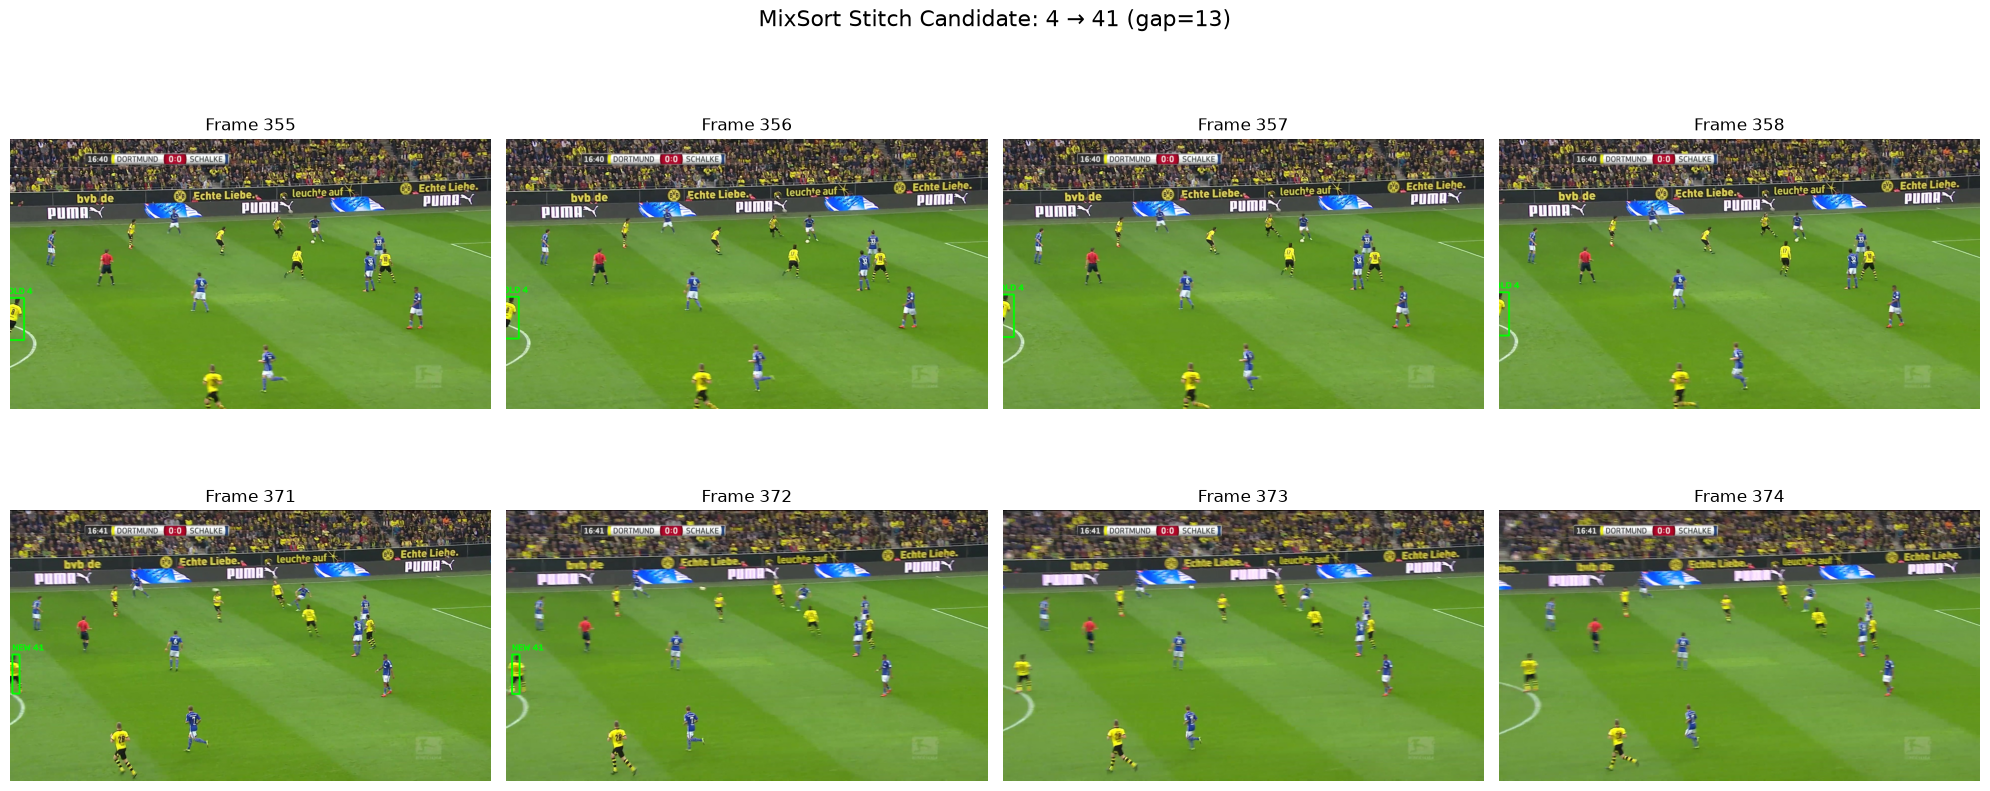


INSPECTING  33 → 160
Old ID last frame : 384
New ID first frame: 391
Gap               : 7


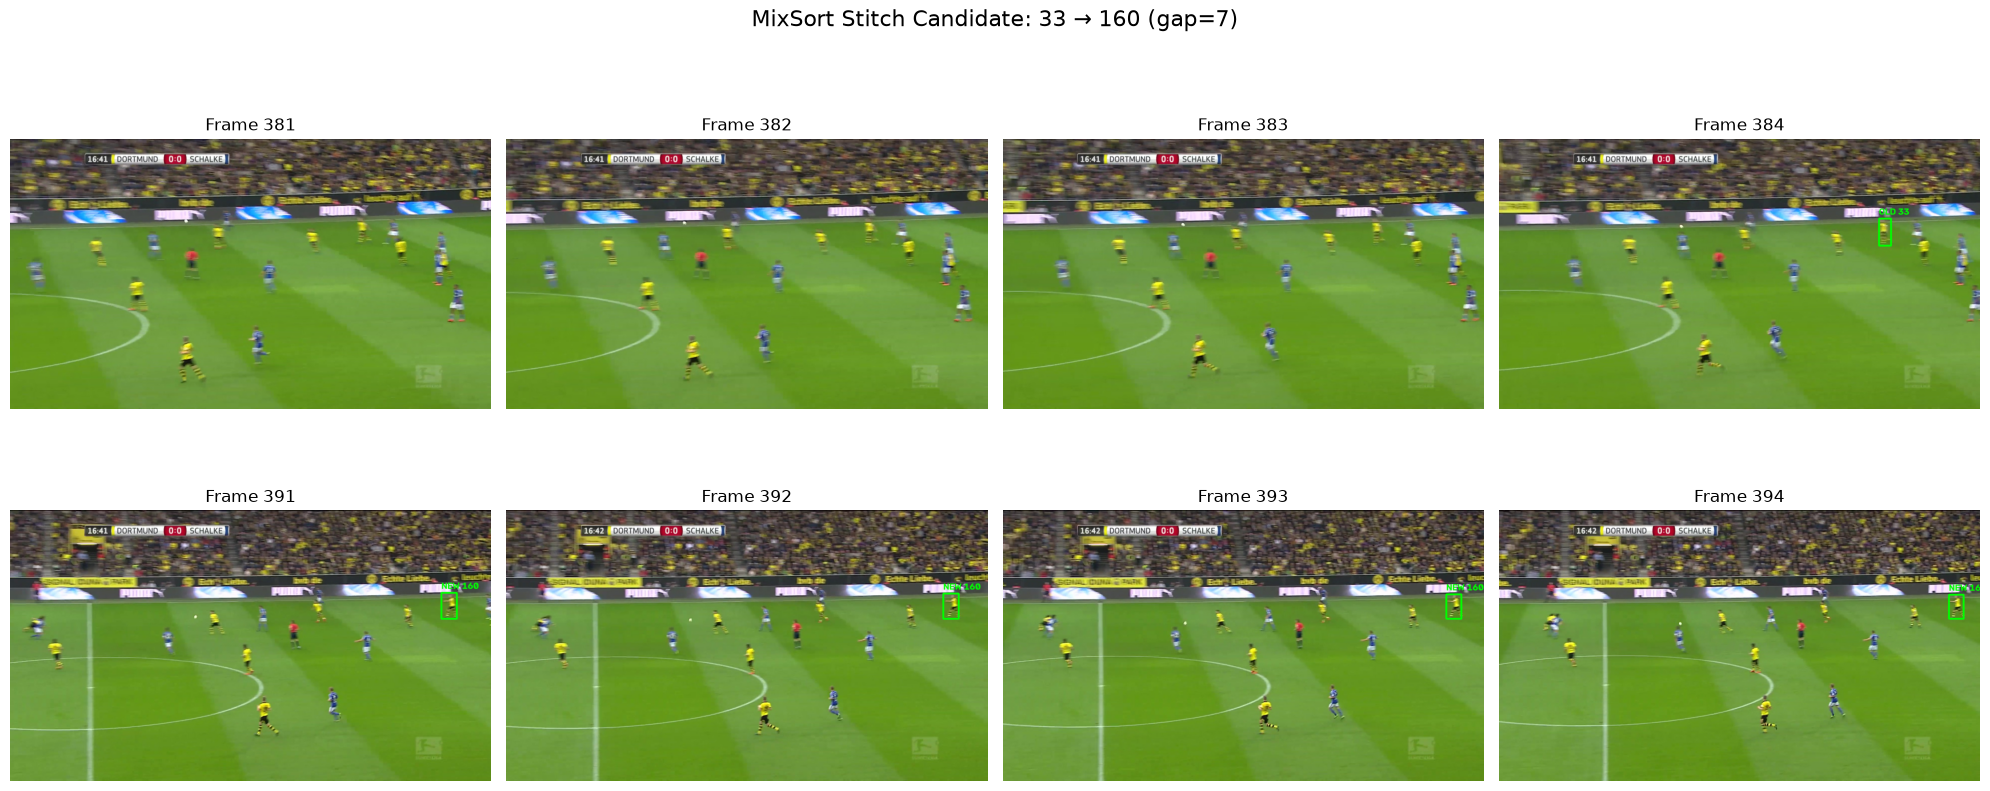


INSPECTING  38 → 116
Old ID last frame : 384
New ID first frame: 385
Gap               : 1


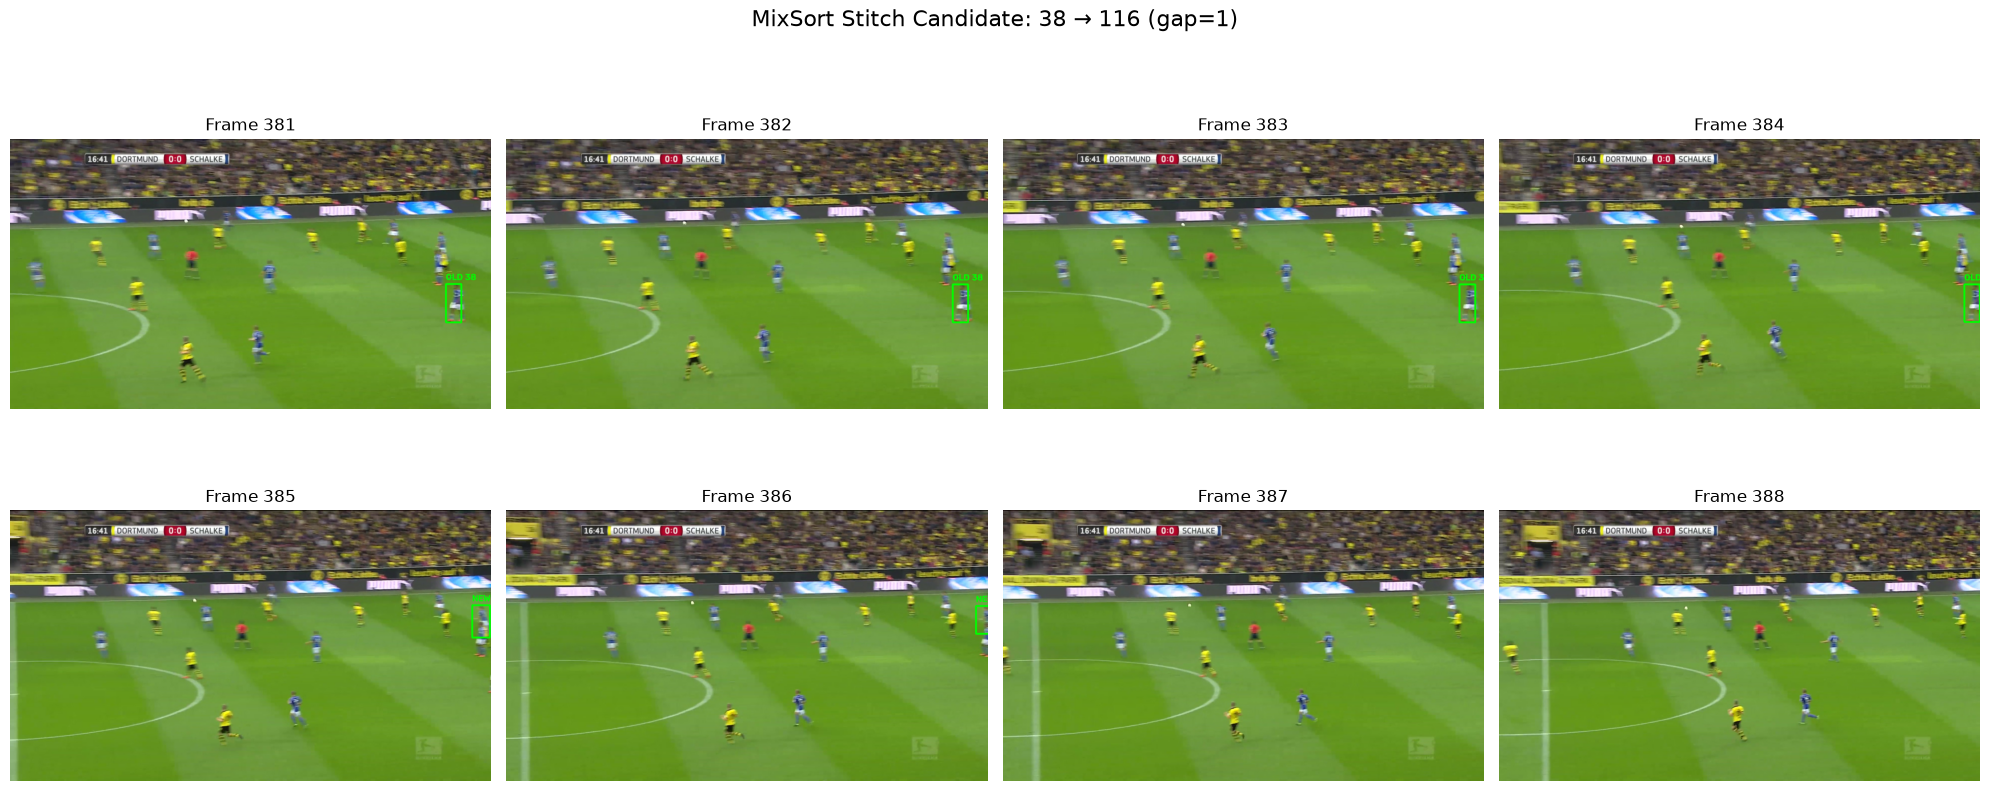


INSPECTING  19 → 189
Old ID last frame : 382
New ID first frame: 402
Gap               : 20


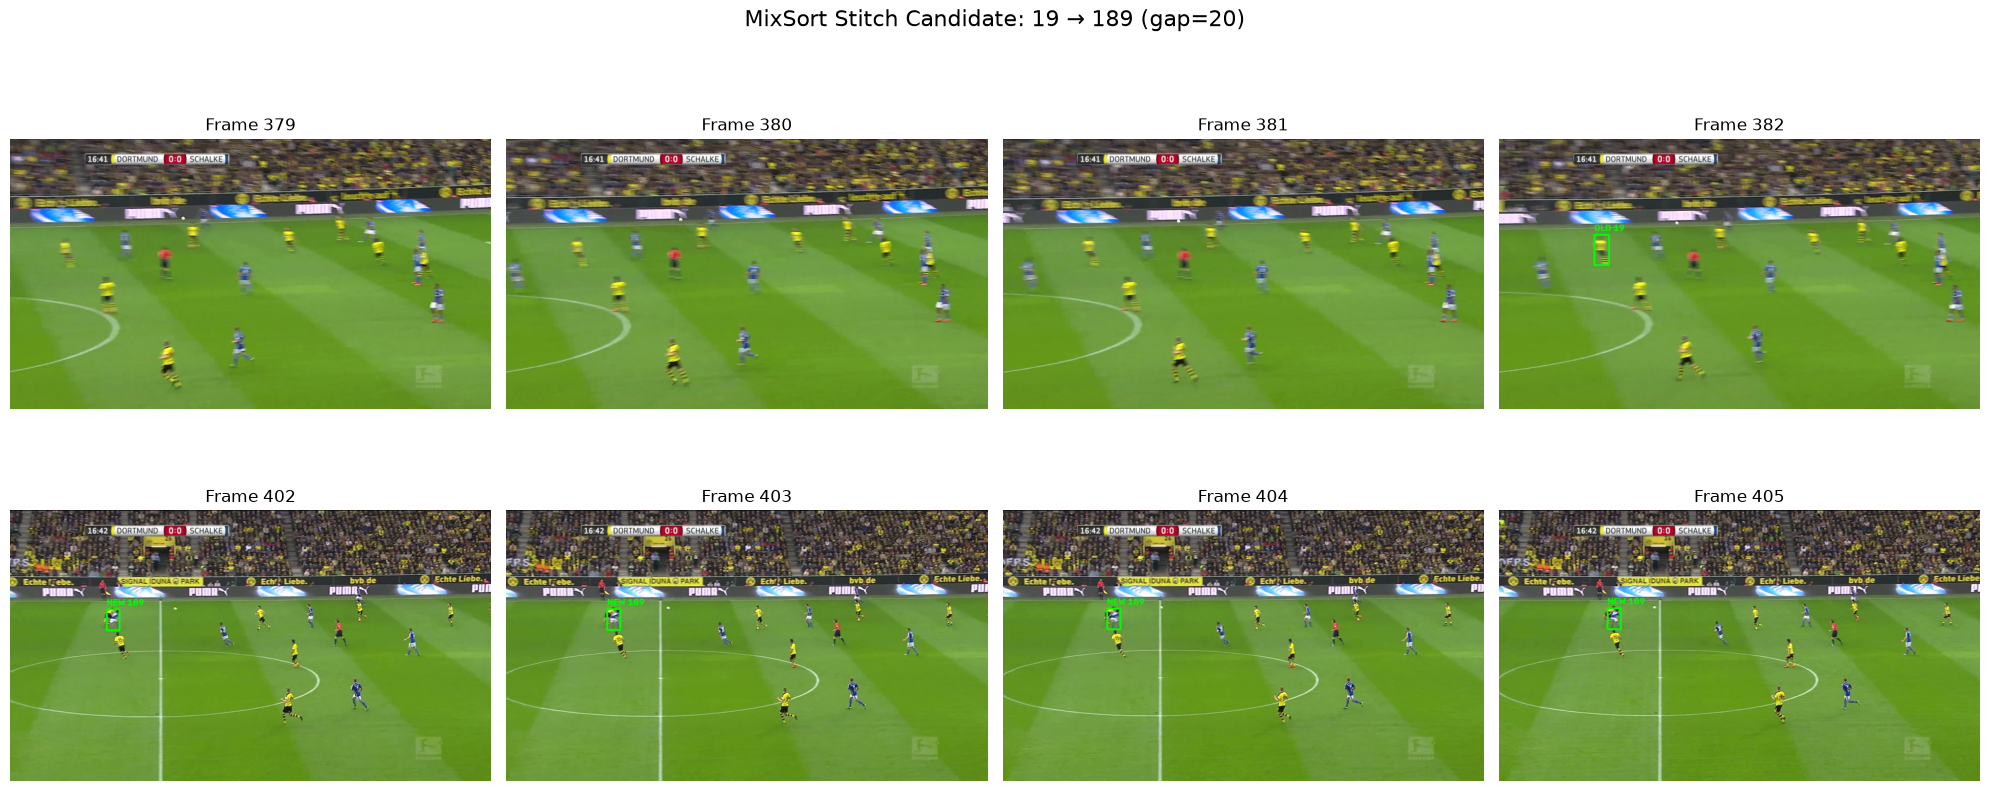

In [14]:
# ============================================================
# CELL 11 — Visual Inspection of Candidate Stitches
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ------------------------------------------------------------
# Candidates we want to inspect
# ------------------------------------------------------------

inspection_pairs = [
    (4, 41),
    (33, 160),
    (38, 116),
    (19, 189),
]


# ------------------------------------------------------------
# Image directory
# ------------------------------------------------------------

IMAGE_DIR = SEQ_DIR / "img1"

print("Image directory:", IMAGE_DIR)


# ------------------------------------------------------------
# Helper: locate frame image
# ------------------------------------------------------------

def get_frame_image(frame_id):

    possible_names = [
        f"{frame_id:06d}.jpg",
        f"{frame_id:06d}.png",
        f"{frame_id}.jpg",
        f"{frame_id}.png",
    ]

    for name in possible_names:

        path = IMAGE_DIR / name

        if path.exists():
            return path

    return None


# ------------------------------------------------------------
# Helper: get observation for ID at frame
# ------------------------------------------------------------

def get_observation(track_id, frame_id):

    rows = df[
        (df["mixsort_id"] == track_id) &
        (df["frame_id"] == frame_id)
    ]

    if len(rows) == 0:
        return None

    return rows.iloc[0]


# ------------------------------------------------------------
# Helper: draw bounding box
# ------------------------------------------------------------

def draw_track(frame, row, label):

    if row is None:
        return frame

    x1 = int(row["x1"])
    y1 = int(row["y1"])
    x2 = int(row["x2"])
    y2 = int(row["y2"])

    cv2.rectangle(
        frame,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        3
    )

    cv2.putText(
        frame,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2,
        cv2.LINE_AA
    )

    return frame


# ------------------------------------------------------------
# Create visual panels
# ------------------------------------------------------------

for old_id, new_id in inspection_pairs:

    old_info = lifecycles[
        lifecycles["mixsort_id"] == old_id
    ].iloc[0]

    new_info = lifecycles[
        lifecycles["mixsort_id"] == new_id
    ].iloc[0]


    old_last = int(old_info["last_frame"])
    new_first = int(new_info["first_frame"])

    gap = new_first - old_last


    print("\n" + "=" * 80)
    print(f"INSPECTING  {old_id} → {new_id}")
    print("=" * 80)

    print("Old ID last frame :", old_last)
    print("New ID first frame:", new_first)
    print("Gap               :", gap)


    # --------------------------------------------------------
    # Select frames around transition
    # --------------------------------------------------------

    before_frames = [
        old_last - 3,
        old_last - 2,
        old_last - 1,
        old_last
    ]

    after_frames = [
        new_first,
        new_first + 1,
        new_first + 2,
        new_first + 3
    ]

    frames_to_show = (
        before_frames +
        after_frames
    )


    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(20, 9)
    )

    axes = axes.flatten()


    for idx, frame_id in enumerate(frames_to_show):

        ax = axes[idx]

        image_path = get_frame_image(frame_id)

        if image_path is None:

            ax.text(
                0.5,
                0.5,
                f"Frame {frame_id}\nNOT FOUND",
                ha="center",
                va="center"
            )

            ax.axis("off")
            continue


        frame = cv2.imread(
            str(image_path)
        )

        if frame is None:

            ax.text(
                0.5,
                0.5,
                f"Frame {frame_id}\nLOAD FAILED",
                ha="center",
                va="center"
            )

            ax.axis("off")
            continue


        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )


        # ----------------------------------------------------
        # Draw old/new track if it exists on this frame
        # ----------------------------------------------------

        old_row = get_observation(
            old_id,
            frame_id
        )

        new_row = get_observation(
            new_id,
            frame_id
        )


        if old_row is not None:

            frame = draw_track(
                frame,
                old_row,
                f"OLD {old_id}"
            )


        if new_row is not None:

            frame = draw_track(
                frame,
                new_row,
                f"NEW {new_id}"
            )


        ax.imshow(frame)

        ax.set_title(
            f"Frame {frame_id}",
            fontsize=12
        )

        ax.axis("off")


    # --------------------------------------------------------
    # Overall title
    # --------------------------------------------------------

    fig.suptitle(
        f"MixSort Stitch Candidate: {old_id} → {new_id} "
        f"(gap={gap})",
        fontsize=16
    )

    plt.tight_layout()

    plt.show()

In [15]:
# ============================================================
# CELL 12 — Improved Deterministic Stitch Decision
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# Configuration
# ============================================================

# Broad candidate limits
MAX_GAP = 30

MAX_CURRENT_DISTANCE = 300.0
MAX_PREDICTION_DISTANCE = 300.0


# Final safety limits
FINAL_MAX_GAP = 20

FINAL_MAX_PREDICTION_DISTANCE = 180.0


# Strong prediction
STRONG_PREDICTION_DISTANCE = 100.0


# Direction
#
# We DO NOT make direction a hard requirement.
# This is important because 38 -> 116 was visually good
# despite weak direction evidence.
MIN_DIRECTION_SOFT = 0.20


# Final score
MIN_FINAL_SCORE = 0.40


# ------------------------------------------------------------
# Prediction/current distance conflict
#
# If the new detection is extremely close to the old
# position, but the motion prediction is very far away,
# the two signals disagree.
# ------------------------------------------------------------

VERY_CLOSE_CURRENT_DISTANCE = 25.0
LARGE_PREDICTION_DISTANCE = 100.0


# ============================================================
# Start from Hungarian assignments
# ============================================================

improved = assignment_df.copy()


# ------------------------------------------------------------
# Feature: prediction/current conflict
# ------------------------------------------------------------

improved["position_motion_conflict"] = (

    (improved["current_distance"]
     <= VERY_CLOSE_CURRENT_DISTANCE)

    &

    (improved["prediction_distance"]
     >= LARGE_PREDICTION_DISTANCE)
)


# ------------------------------------------------------------
# Feature: strong prediction
# ------------------------------------------------------------

improved["strong_prediction"] = (
    improved["prediction_distance"]
    <= STRONG_PREDICTION_DISTANCE
)


# ------------------------------------------------------------
# Feature: acceptable prediction
# ------------------------------------------------------------

improved["prediction_ok"] = (
    improved["prediction_distance"]
    <= FINAL_MAX_PREDICTION_DISTANCE
)


# ------------------------------------------------------------
# Feature: acceptable temporal gap
# ------------------------------------------------------------

improved["gap_ok"] = (
    improved["gap"]
    <= FINAL_MAX_GAP
)


# ------------------------------------------------------------
# Feature: direction is at least somewhat reasonable
#
# We don't require 0.7 because of the 38 -> 116 case.
# ------------------------------------------------------------

improved["direction_ok"] = (
    improved["direction_score_final"]
    >= MIN_DIRECTION_SOFT
)


# ------------------------------------------------------------
# Feature: overall score
# ------------------------------------------------------------

improved["score_ok"] = (
    improved["candidate_score"]
    >= MIN_FINAL_SCORE
)


# ============================================================
# Final deterministic decision
# ============================================================

def final_decision(row):

    # --------------------------------------------------------
    # Hard rejection: temporal
    # --------------------------------------------------------

    if not row["gap_ok"]:
        return "REJECT"


    # --------------------------------------------------------
    # Hard rejection: prediction
    # --------------------------------------------------------

    if not row["prediction_ok"]:
        return "REJECT"


    # --------------------------------------------------------
    # Hard rejection: strong position/motion contradiction
    # --------------------------------------------------------

    if row["position_motion_conflict"]:
        return "REJECT"


    # --------------------------------------------------------
    # Hard rejection: very poor direction
    #
    # We allow mediocre direction, but not almost completely
    # opposite motion.
    # --------------------------------------------------------

    if not row["direction_ok"]:
        return "REJECT"


    # --------------------------------------------------------
    # Overall score
    # --------------------------------------------------------

    if not row["score_ok"]:
        return "REJECT"


    # --------------------------------------------------------
    # Strong candidate
    # --------------------------------------------------------

    if (
        row["strong_prediction"]
        and
        row["direction_score_final"] >= 0.70
        and
        row["candidate_score"] >= 0.50
    ):
        return "STRONG"


    # --------------------------------------------------------
    # Otherwise accept as a normal stitch candidate
    # --------------------------------------------------------

    return "ACCEPT"


improved["final_decision"] = (
    improved.apply(
        final_decision,
        axis=1
    )
)


# ============================================================
# Print complete results
# ============================================================

print("=" * 100)
print("IMPROVED DETERMINISTIC STITCH DECISION")
print("=" * 100)


display(
    improved[
        [
            "old_id",
            "new_id",
            "gap",

            "current_distance",
            "prediction_distance",

            "direction_score_final",
            "bbox_score_final",

            "candidate_score",

            "position_motion_conflict",
            "final_decision"
        ]
    ]
    .round(3)
    .reset_index(drop=True)
)


# ============================================================
# Summary
# ============================================================

print("\n" + "=" * 100)
print("DECISION SUMMARY")
print("=" * 100)


print(
    "\nSTRONG:",
    (improved["final_decision"] == "STRONG").sum()
)

print(
    "ACCEPT:",
    (improved["final_decision"] == "ACCEPT").sum()
)

print(
    "REJECT:",
    (improved["final_decision"] == "REJECT").sum()
)


# ============================================================
# Proposed stitches
# ============================================================

proposed = improved[
    improved["final_decision"].isin(
        ["STRONG", "ACCEPT"]
    )
].copy()


print("\n" + "=" * 100)
print("PROPOSED STITCHES")
print("=" * 100)


if len(proposed) > 0:

    display(
        proposed[
            [
                "old_id",
                "new_id",
                "gap",
                "current_distance",
                "prediction_distance",
                "direction_score_final",
                "bbox_score_final",
                "candidate_score",
                "final_decision"
            ]
        ]
        .sort_values(
            "candidate_score",
            ascending=False
        )
        .round(3)
        .reset_index(drop=True)
    )

else:

    print("No proposed stitches.")


# ============================================================
# Rejected stitches
# ============================================================

print("\n" + "=" * 100)
print("REJECTED STITCHES")
print("=" * 100)


rejected = improved[
    improved["final_decision"] == "REJECT"
]


if len(rejected) > 0:

    display(
        rejected[
            [
                "old_id",
                "new_id",
                "gap",
                "current_distance",
                "prediction_distance",
                "direction_score_final",
                "candidate_score",
                "position_motion_conflict"
            ]
        ]
        .round(3)
        .reset_index(drop=True)
    )

IMPROVED DETERMINISTIC STITCH DECISION


,old_id,new_id,gap,current_distance,prediction_distance,direction_score_final,bbox_score_final,candidate_score,position_motion_conflict,final_decision
0,4,41,13,31.502,43.923,0.850,0.694,0.658,False,STRONG
1,38,116,1,142.444,146.108,0.477,0.872,0.476,False,ACCEPT
2,8,159,8,174.965,195.238,0.172,0.814,0.313,False,REJECT
3,33,160,7,140.647,121.479,0.752,0.853,0.519,False,ACCEPT
4,20,170,14,203.874,244.937,0.115,0.806,0.252,False,REJECT
5,14,183,25,261.550,134.945,0.964,0.834,0.498,False,REJECT
6,41,185,25,226.239,165.946,0.876,0.535,0.386,False,REJECT
7,31,188,4,54.710,74.793,0.021,0.853,0.478,False,REJECT
8,19,189,20,4.351,157.134,0.808,0.794,0.438,True,REJECT
9,21,190,15,242.718,270.261,0.438,0.874,0.318,False,REJECT



DECISION SUMMARY

STRONG: 1
ACCEPT: 2
REJECT: 7

PROPOSED STITCHES


,old_id,new_id,gap,current_distance,prediction_distance,direction_score_final,bbox_score_final,candidate_score,final_decision
0,4,41,13,31.502,43.923,0.850,0.694,0.658,STRONG
1,33,160,7,140.647,121.479,0.752,0.853,0.519,ACCEPT
2,38,116,1,142.444,146.108,0.477,0.872,0.476,ACCEPT



REJECTED STITCHES


,old_id,new_id,gap,current_distance,prediction_distance,direction_score_final,candidate_score,position_motion_conflict
0,8,159,8,174.965,195.238,0.172,0.313,False
1,20,170,14,203.874,244.937,0.115,0.252,False
2,14,183,25,261.550,134.945,0.964,0.498,False
3,41,185,25,226.239,165.946,0.876,0.386,False
4,31,188,4,54.710,74.793,0.021,0.478,False
5,19,189,20,4.351,157.134,0.808,0.438,True
6,21,190,15,242.718,270.261,0.438,0.318,False


In [17]:
# ============================================================
# CELL 13A — Load c017 Ground Truth
# ============================================================

from pathlib import Path
import pandas as pd


# ------------------------------------------------------------
# Find GT CSV files
# ------------------------------------------------------------

GT_DIR = SEQ_DIR / "gt"

print("GT directory:", GT_DIR)
print()


gt_files = sorted(
    GT_DIR.glob("*.txt")
)


print("GT files found:")

for f in gt_files:
    print(" -", f.name)


# ------------------------------------------------------------
# Find the main GT file
# ------------------------------------------------------------

if len(gt_files) == 0:
    raise FileNotFoundError(
        f"No GT files found in {GT_DIR}"
    )


# For MOT-format SportsMOT sequences the GT file is usually
# gt.txt.
if (GT_DIR / "gt.txt").exists():

    GT_PATH = GT_DIR / "gt.txt"

else:

    GT_PATH = gt_files[0]


print("\nUsing GT file:")
print(GT_PATH)


# ------------------------------------------------------------
# Load MOT-format GT
#
# Standard MOT format:
#
# frame,id,x,y,w,h,conf,class,visibility
# ------------------------------------------------------------

gt_eval = pd.read_csv(
    GT_PATH,
    header=None
)


print("\nRaw GT shape:", gt_eval.shape)


# ------------------------------------------------------------
# Assign standard MOT column names
# ------------------------------------------------------------

base_columns = [
    "frame_id",
    "gt_id",
    "x",
    "y",
    "w",
    "h",
    "confidence",
    "class_id",
    "visibility"
]


# Some files may have fewer columns.
gt_eval.columns = base_columns[
    :gt_eval.shape[1]
]


# ------------------------------------------------------------
# Convert bbox to x1,y1,x2,y2
# ------------------------------------------------------------

gt_eval["x1"] = gt_eval["x"].astype(float)

gt_eval["y1"] = gt_eval["y"].astype(float)

gt_eval["x2"] = (
    gt_eval["x"]
    + gt_eval["w"]
).astype(float)

gt_eval["y2"] = (
    gt_eval["y"]
    + gt_eval["h"]
).astype(float)


# ------------------------------------------------------------
# Basic cleanup
# ------------------------------------------------------------

gt_eval["frame_id"] = (
    gt_eval["frame_id"]
    .astype(int)
)

gt_eval["gt_id"] = (
    gt_eval["gt_id"]
    .astype(int)
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nGT columns:")
print(gt_eval.columns.tolist())


print("\nGT rows:", len(gt_eval))

print(
    "GT frames:",
    gt_eval["frame_id"].min(),
    "→",
    gt_eval["frame_id"].max()
)

print(
    "Unique GT IDs:",
    gt_eval["gt_id"].nunique()
)


print("\nFirst 10 GT rows:")

display(
    gt_eval.head(10)
)

GT directory: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/gt

GT files found:
 - gt.txt

Using GT file:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/gt/gt.txt

Raw GT shape: (6622, 9)

GT columns:
['frame_id', 'gt_id', 'x', 'y', 'w', 'h', 'confidence', 'class_id', 'visibility', 'x1', 'y1', 'x2', 'y2']

GT rows: 6622
GT frames: 1 → 450
Unique GT IDs: 21

First 10 GT rows:


,frame_id,gt_id,x,y,w,h,confidence,class_id,visibility,x1,y1,x2,y2
0,1,0,509,458,36,92,1,1,1,509.0,458.0,545.0,550.0
1,1,1,874,398,32,81,1,1,1,874.0,398.0,906.0,479.0
2,1,2,931,208,26,58,1,1,1,931.0,208.0,957.0,266.0
3,1,3,197,313,51,65,1,1,1,197.0,313.0,248.0,378.0
4,1,4,400,223,23,55,1,1,1,400.0,223.0,423.0,278.0
5,1,5,358,207,26,53,1,1,1,358.0,207.0,384.0,260.0
6,1,6,8,470,38,104,1,1,1,8.0,470.0,46.0,574.0
7,1,7,292,195,32,55,1,1,1,292.0,195.0,324.0,250.0
8,1,8,0,231,27,66,1,1,1,0.0,231.0,27.0,297.0
9,1,10,778,386,39,82,1,1,1,778.0,386.0,817.0,468.0


In [18]:
# ============================================================
# CELL 13B — MixSort → GT Identity Association
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# IoU helper
# ------------------------------------------------------------

def calculate_iou(box_a, box_b):

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)

    intersection = iw * ih

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ------------------------------------------------------------
# Match every MixSort detection against GT in same frame
# ------------------------------------------------------------

gt_by_frame = {
    int(frame_id): group
    for frame_id, group
    in gt_eval.groupby("frame_id")
}


association_rows = []


for _, track_row in df.iterrows():

    frame_id = int(track_row["frame_id"])
    mixsort_id = int(track_row["mixsort_id"])

    if frame_id not in gt_by_frame:
        continue


    track_box = [
        float(track_row["x1"]),
        float(track_row["y1"]),
        float(track_row["x2"]),
        float(track_row["y2"])
    ]


    frame_gt = gt_by_frame[frame_id]


    best_gt_id = None
    best_iou = 0.0


    for _, gt_row in frame_gt.iterrows():

        gt_box = [
            float(gt_row["x1"]),
            float(gt_row["y1"]),
            float(gt_row["x2"]),
            float(gt_row["y2"])
        ]


        iou = calculate_iou(
            track_box,
            gt_box
        )


        if iou > best_iou:

            best_iou = iou
            best_gt_id = int(
                gt_row["gt_id"]
            )


    association_rows.append({

        "frame_id": frame_id,
        "mixsort_id": mixsort_id,
        "gt_id": best_gt_id,
        "iou": best_iou
    })


association_df = pd.DataFrame(
    association_rows
)


# ------------------------------------------------------------
# Keep only reasonably matched observations
# ------------------------------------------------------------

GT_ASSOC_IOU = 0.30

matched_associations = association_df[
    association_df["iou"] >= GT_ASSOC_IOU
].copy()


print("=" * 90)
print("MIXSORT → GT ASSOCIATION")
print("=" * 90)

print(
    "MixSort observations:",
    len(association_df)
)

print(
    "Matched observations:",
    len(matched_associations)
)

print(
    "Association rate:",
    f"{len(matched_associations) / len(association_df):.3%}"
)


# ------------------------------------------------------------
# Determine dominant GT identity for each MixSort ID
# ------------------------------------------------------------

mixsort_gt_counts = (
    matched_associations
    .groupby(
        ["mixsort_id", "gt_id"]
    )
    .agg(
        matches=("gt_id", "size"),
        mean_iou=("iou", "mean"),
        median_iou=("iou", "median")
    )
    .reset_index()
)


# ------------------------------------------------------------
# Dominant GT identity
# ------------------------------------------------------------

dominant_gt = (
    mixsort_gt_counts
    .sort_values(
        [
            "mixsort_id",
            "matches",
            "mean_iou"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .groupby("mixsort_id")
    .head(1)
    .copy()
)


# ------------------------------------------------------------
# Calculate identity purity
# ------------------------------------------------------------

total_matches_by_mixsort = (
    matched_associations
    .groupby("mixsort_id")
    .size()
    .rename("total_matches")
)


dominant_gt = dominant_gt.merge(
    total_matches_by_mixsort,
    on="mixsort_id",
    how="left"
)


dominant_gt["purity"] = (
    dominant_gt["matches"]
    /
    dominant_gt["total_matches"]
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("DOMINANT GT IDENTITY FOR EACH MIXSORT ID")
print("=" * 90)


display(
    dominant_gt[
        [
            "mixsort_id",
            "gt_id",
            "matches",
            "total_matches",
            "purity",
            "mean_iou",
            "median_iou"
        ]
    ]
    .sort_values("mixsort_id")
    .round(3)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Ambiguous MixSort IDs
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("MIXSORT IDs WITH IDENTITY AMBIGUITY")
print("=" * 90)


ambiguous_mixsort = (
    mixsort_gt_counts
    .groupby("mixsort_id")
    .size()
)

ambiguous_ids = ambiguous_mixsort[
    ambiguous_mixsort > 1
].index


if len(ambiguous_ids) > 0:

    display(
        mixsort_gt_counts[
            mixsort_gt_counts["mixsort_id"]
            .isin(ambiguous_ids)
        ]
        .sort_values(
            [
                "mixsort_id",
                "matches"
            ],
            ascending=[
                True,
                False
            ]
        )
        .round(3)
        .reset_index(drop=True)
    )

else:

    print(
        "No MixSort IDs matched multiple GT identities."
    )

MIXSORT → GT ASSOCIATION
MixSort observations: 6632
Matched observations: 6248
Association rate: 94.210%

DOMINANT GT IDENTITY FOR EACH MIXSORT ID


,mixsort_id,gt_id,matches,total_matches,purity,mean_iou,median_iou
0,1,10.0,429,429,1.000,0.858,0.879
1,2,15.0,100,100,1.000,0.826,0.846
2,3,11.0,60,60,1.000,0.818,0.839
3,4,0.0,357,357,1.000,0.895,0.903
4,5,16.0,251,251,1.000,0.881,0.899
5,6,1.0,70,70,1.000,0.881,0.907
6,7,2.0,105,105,1.000,0.830,0.854
7,8,17.0,374,377,0.992,0.854,0.867
8,9,3.0,170,170,1.000,0.841,0.859
9,10,6.0,174,174,1.000,0.877,0.887



MIXSORT IDs WITH IDENTITY AMBIGUITY


,mixsort_id,gt_id,matches,mean_iou,median_iou
0,8,17.0,374,0.854,0.867
1,8,7.0,2,0.679,0.679
2,8,13.0,1,0.558,0.558
3,12,7.0,356,0.844,0.851
4,12,5.0,30,0.747,0.757
5,17,18.0,370,0.820,0.833
6,17,3.0,58,0.852,0.870
7,17,4.0,2,0.542,0.542
8,17,14.0,1,0.429,0.429
9,19,5.0,32,0.442,0.433


In [19]:
# ============================================================
# CELL 14 — Appearance Descriptors for Track Stitching
# ============================================================

import cv2
import numpy as np
import pandas as pd


# ============================================================
# Configuration
# ============================================================

# Number of observations used around each track boundary.
APPEARANCE_WINDOW = 5

# Histogram bins.
H_BINS = 16
S_BINS = 16


# ============================================================
# Image loading helper
# ============================================================

def load_frame(frame_id):

    image_path = get_frame_image(int(frame_id))

    if image_path is None:
        return None

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        return None

    return image


# ============================================================
# Crop player from bounding box
# ============================================================

def crop_track(frame, row):

    if frame is None or row is None:
        return None

    h, w = frame.shape[:2]

    x1 = max(
        0,
        int(row["x1"])
    )

    y1 = max(
        0,
        int(row["y1"])
    )

    x2 = min(
        w,
        int(row["x2"])
    )

    y2 = min(
        h,
        int(row["y2"])
    )

    if x2 <= x1 or y2 <= y1:
        return None

    crop = frame[
        y1:y2,
        x1:x2
    ]

    if crop.size == 0:
        return None

    return crop


# ============================================================
# Appearance descriptor
#
# HSV histogram is used because it is less sensitive to
# illumination than raw RGB.
# ============================================================

def appearance_descriptor(crop):

    if crop is None:
        return None

    # --------------------------------------------------------
    # Resize for consistent representation
    # --------------------------------------------------------

    crop = cv2.resize(
        crop,
        (64, 128)
    )

    hsv = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2HSV
    )


    # --------------------------------------------------------
    # Mask extreme pixels
    #
    # Avoid letting very dark/bright background pixels
    # dominate the descriptor.
    # --------------------------------------------------------

    mask = cv2.inRange(
        hsv,
        np.array([0, 30, 20]),
        np.array([179, 255, 245])
    )


    # --------------------------------------------------------
    # Hue histogram
    # --------------------------------------------------------

    hist_h = cv2.calcHist(
        [hsv],
        [0],
        mask,
        [H_BINS],
        [0, 180]
    )


    # --------------------------------------------------------
    # Saturation histogram
    # --------------------------------------------------------

    hist_s = cv2.calcHist(
        [hsv],
        [1],
        mask,
        [S_BINS],
        [0, 256]
    )


    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    hist_h = cv2.normalize(
        hist_h,
        hist_h
    ).flatten()

    hist_s = cv2.normalize(
        hist_s,
        hist_s
    ).flatten()


    descriptor = np.concatenate([
        hist_h,
        hist_s
    ])


    return descriptor.astype(
        np.float32
    )


# ============================================================
# Build descriptor for one MixSort observation
# ============================================================

def get_track_descriptor(
    track_id,
    frame_id
):

    row_df = df[
        (df["mixsort_id"] == track_id) &
        (df["frame_id"] == frame_id)
    ]

    if len(row_df) == 0:
        return None

    row = row_df.iloc[0]

    frame = load_frame(
        frame_id
    )

    crop = crop_track(
        frame,
        row
    )

    return appearance_descriptor(
        crop
    )


# ============================================================
# Descriptor similarity
# ============================================================

def appearance_similarity(
    descriptor_a,
    descriptor_b
):

    if (
        descriptor_a is None
        or descriptor_b is None
    ):
        return np.nan


    # Histogram intersection
    similarity = cv2.compareHist(
        descriptor_a.astype(np.float32),
        descriptor_b.astype(np.float32),
        cv2.HISTCMP_CORREL
    )


    # Convert [-1,1] → [0,1]
    similarity = (
        similarity + 1.0
    ) / 2.0


    return float(
        np.clip(
            similarity,
            0.0,
            1.0
        )
    )


# ============================================================
# Track boundary appearance
#
# Average several observations instead of using a single
# frame.
# ============================================================

def get_boundary_descriptors(
    track_id,
    side="end",
    window=5
):

    track = (
        df[
            df["mixsort_id"] == track_id
        ]
        .sort_values("frame_id")
    )


    if len(track) == 0:
        return []


    if side == "end":

        rows = track.tail(window)

    else:

        rows = track.head(window)


    descriptors = []


    for _, row in rows.iterrows():

        descriptor = get_track_descriptor(
            track_id,
            int(row["frame_id"])
        )

        if descriptor is not None:

            descriptors.append(
                descriptor
            )


    return descriptors


# ============================================================
# Average descriptors
# ============================================================

def average_descriptor(
    descriptors
):

    if len(descriptors) == 0:
        return None


    descriptor = np.mean(
        np.stack(descriptors),
        axis=0
    )


    # Normalize again
    norm = np.linalg.norm(
        descriptor
    )

    if norm > 1e-8:

        descriptor = (
            descriptor / norm
        )


    return descriptor.astype(
        np.float32
    )


# ============================================================
# Build boundary appearance cache
# ============================================================

appearance_cache = {}


all_mixsort_ids = sorted(
    df["mixsort_id"]
    .unique()
)


print(
    "Building appearance descriptors..."
)


for track_id in all_mixsort_ids:

    track_id = int(track_id)


    end_descriptors = (
        get_boundary_descriptors(
            track_id,
            side="end",
            window=APPEARANCE_WINDOW
        )
    )


    start_descriptors = (
        get_boundary_descriptors(
            track_id,
            side="start",
            window=APPEARANCE_WINDOW
        )
    )


    appearance_cache[track_id] = {

        "end": average_descriptor(
            end_descriptors
        ),

        "start": average_descriptor(
            start_descriptors
        )
    }


print(
    "Appearance descriptors built:",
    len(appearance_cache)
)


# ============================================================
# Test appearance similarity on our four known transitions
# ============================================================

test_pairs = [
    (4, 41),
    (33, 160),
    (38, 116),
    (19, 189)
]


print("\n" + "=" * 80)
print("APPEARANCE SIMILARITY TEST")
print("=" * 80)


appearance_test_rows = []


for old_id, new_id in test_pairs:

    old_descriptor = (
        appearance_cache[old_id]["end"]
    )

    new_descriptor = (
        appearance_cache[new_id]["start"]
    )


    similarity = appearance_similarity(
        old_descriptor,
        new_descriptor
    )


    appearance_test_rows.append({

        "old_id": old_id,
        "new_id": new_id,
        "appearance_similarity": similarity
    })


appearance_test_df = pd.DataFrame(
    appearance_test_rows
)


display(
    appearance_test_df
    .round(3)
)

Building appearance descriptors...
Appearance descriptors built: 42

APPEARANCE SIMILARITY TEST


,old_id,new_id,appearance_similarity
0,4,41,0.874
1,33,160,0.953
2,38,116,0.924
3,19,189,0.841


In [20]:
# ============================================================
# CELL 15 — OSNet / Torchreid Environment Check
# ============================================================

import sys
import torch
import importlib.util

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Check Torchreid
torchreid_spec = importlib.util.find_spec("torchreid")

if torchreid_spec is None:
    print("\n❌ Torchreid is NOT installed.")
    print("Next step: we will install it.")
else:
    print("\n✓ Torchreid is installed.")
    import torchreid
    print("Torchreid:", getattr(torchreid, "__version__", "version not reported"))

print("\nEnvironment check complete.")

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
PyTorch: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

❌ Torchreid is NOT installed.
Next step: we will install it.

Environment check complete.


In [24]:
!pip install torchreid
!pip install gdown


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gdown]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [25]:
# ============================================================
# CELL 17 — Load Torchreid + Check OSNet
# ============================================================

import torch
import torchreid

print("Torchreid imported successfully ✓")
print("Torchreid version:", getattr(torchreid, "__version__", "0.2.5"))

# Check available model architectures
model_names = torchreid.models.show_avai_models()

print("\nChecking for OSNet models...")

osnet_models = [
    name for name in model_names
    if "osnet" in name.lower()
]

print("OSNet models:")
for name in osnet_models:
    print("  ✓", name)

Torchreid imported successfully ✓
Torchreid version: 0.2.5
['resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152', 'resnext50_32x4d', 'resnext101_32x8d', 'resnet50_fc512', 'se_resnet50', 'se_resnet50_fc512', 'se_resnet101', 'se_resnext50_32x4d', 'se_resnext101_32x4d', 'densenet121', 'densenet169', 'densenet201', 'densenet161', 'densenet121_fc512', 'inceptionresnetv2', 'inceptionv4', 'xception', 'resnet50_ibn_a', 'resnet50_ibn_b', 'nasnsetmobile', 'mobilenetv2_x1_0', 'mobilenetv2_x1_4', 'shufflenet', 'squeezenet1_0', 'squeezenet1_0_fc512', 'squeezenet1_1', 'shufflenet_v2_x0_5', 'shufflenet_v2_x1_0', 'shufflenet_v2_x1_5', 'shufflenet_v2_x2_0', 'mudeep', 'resnet50mid', 'hacnn', 'pcb_p6', 'pcb_p4', 'mlfn', 'osnet_x1_0', 'osnet_x0_75', 'osnet_x0_5', 'osnet_x0_25', 'osnet_ibn_x1_0', 'osnet_ain_x1_0', 'osnet_ain_x0_75', 'osnet_ain_x0_5', 'osnet_ain_x0_25']

Checking for OSNet models...


/home/jatin/tf312/lib/python3.12/site-packages/torchreid/reid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(


TypeError: 'NoneType' object is not iterable

In [26]:
# ============================================================
# CELL 18 — Load Pretrained OSNet
# ============================================================

import torch
import torchreid

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Load OSNet x1.0 with pretrained Re-ID weights
osnet = torchreid.models.build_model(
    name="osnet_x1_0",
    num_classes=1,
    pretrained=True
)

osnet = osnet.to(device)
osnet.eval()

# Count parameters
num_params = sum(p.numel() for p in osnet.parameters())

print("\n✓ OSNet loaded successfully")
print("Model: osnet_x1_0")
print(f"Parameters: {num_params:,}")
print("Device:", next(osnet.parameters()).device)

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1LaG1EJpHrxdAxKnSCJ_i0u-nbxSAeiFY
To: /home/jatin/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth
100%|█████████████████████████████████████████████████████████████████████████████| 10.9M/10.9M [00:01<00:00, 7.13MB/s]


Successfully loaded imagenet pretrained weights from "/home/jatin/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']

✓ OSNet loaded successfully
Model: osnet_x1_0
Parameters: 2,170,021
Device: cuda:0


In [29]:
# ============================================================
# CELL 19 — Download Official OSNet MSMT17 Re-ID Weights
# ============================================================

import torch
import torchreid
import gdown

from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

REID_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/reid"
)

REID_DIR.mkdir(parents=True, exist_ok=True)

REID_WEIGHTS = REID_DIR / (
    "osnet_x1_0_msmt17_combineall.pth"
)

# Official Torchreid MSMT17 checkpoint
GDRIVE_ID = "1IosIFlLiulGIjwW3H8uMRmx3MzPwf86x"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Weights:", REID_WEIGHTS)

# ------------------------------------------------------------
# Download
# ------------------------------------------------------------

if not REID_WEIGHTS.exists():

    print("\nDownloading official MSMT17 Re-ID weights...")

    gdown.download(
        id=GDRIVE_ID,
        output=str(REID_WEIGHTS),
        quiet=False
    )

else:

    print("\n✓ Weights already exist")

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

if not REID_WEIGHTS.exists():
    raise FileNotFoundError(
        "OSNet Re-ID checkpoint was not downloaded."
    )

size_mb = REID_WEIGHTS.stat().st_size / (1024 * 1024)

print("\n✓ Checkpoint downloaded")
print(f"Size: {size_mb:.2f} MB")
print(f"Path: {REID_WEIGHTS}")

Device: cuda
Weights: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/reid/osnet_x1_0_msmt17_combineall.pth



Downloading...
From: https://drive.google.com/uc?id=1IosIFlLiulGIjwW3H8uMRmx3MzPwf86x
To: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/reid/osnet_x1_0_msmt17_combineall.pth
100%|█████████████████████████████████████████████████████████████████████████████| 17.3M/17.3M [00:02<00:00, 6.27MB/s]



✓ Checkpoint downloaded
Size: 16.47 MB
Path: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/reid/osnet_x1_0_msmt17_combineall.pth


In [31]:
# ============================================================
# CELL 20 — Load OSNet MSMT17 Re-ID Model
# ============================================================

import torch
import torchreid

# ------------------------------------------------------------
# Build OSNet with the SAME number of classes as checkpoint
# ------------------------------------------------------------

reid_model = torchreid.models.build_model(
    name="osnet_x1_0",
    num_classes=4101,
    pretrained=False
)

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    REID_WEIGHTS,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded:", type(checkpoint))
print("Checkpoint tensors:", len(checkpoint))

# ------------------------------------------------------------
# Remove DataParallel prefix if present
# ------------------------------------------------------------

state_dict = {
    key.replace("module.", "", 1)
    if key.startswith("module.")
    else key: value
    for key, value in checkpoint.items()
}

# ------------------------------------------------------------
# Load weights
# ------------------------------------------------------------

missing_keys, unexpected_keys = reid_model.load_state_dict(
    state_dict,
    strict=True
)

print("\n✓ All checkpoint weights loaded successfully")
print("Missing keys:", len(missing_keys))
print("Unexpected keys:", len(unexpected_keys))

# ------------------------------------------------------------
# Move model to GPU
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

reid_model = reid_model.to(device)
reid_model.eval()

# ------------------------------------------------------------
# Model information
# ------------------------------------------------------------

num_params = sum(
    p.numel()
    for p in reid_model.parameters()
)

print("\n✓ OSNet MSMT17 Re-ID model ready")
print("Model: osnet_x1_0")
print("Training identities:", 4101)
print("Parameters:", f"{num_params:,}")
print("Device:", next(reid_model.parameters()).device)

Checkpoint loaded: <class 'collections.OrderedDict'>
Checkpoint tensors: 567

✓ All checkpoint weights loaded successfully
Missing keys: 0
Unexpected keys: 0

✓ OSNet MSMT17 Re-ID model ready
Model: osnet_x1_0
Training identities: 4101
Parameters: 4,273,321
Device: cuda:0


In [32]:
# ============================================================
# CELL 21 — Test OSNet Re-ID Embedding
# ============================================================

import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Create a dummy player crop
# ------------------------------------------------------------

dummy_crop = torch.randn(
    1, 3, 256, 128,
    device=device
)

# ------------------------------------------------------------
# Extract Re-ID feature
# ------------------------------------------------------------

with torch.no_grad():

    embedding = reid_model(dummy_crop)

# ------------------------------------------------------------
# Inspect embedding
# ------------------------------------------------------------

print("Embedding shape:", embedding.shape)
print("Embedding dtype:", embedding.dtype)
print("Embedding device:", embedding.device)

# ------------------------------------------------------------
# L2 normalize
# ------------------------------------------------------------

embedding = F.normalize(
    embedding,
    p=2,
    dim=1
)

print("Normalized shape:", embedding.shape)

# Verify norm
norm = torch.norm(
    embedding,
    p=2,
    dim=1
)

print("Embedding norm:", norm.item())

print("\n✓ OSNet is producing Re-ID embeddings successfully")

Embedding shape: torch.Size([1, 512])
Embedding dtype: torch.float32
Embedding device: cuda:0
Normalized shape: torch.Size([1, 512])
Embedding norm: 0.9999999403953552

✓ OSNet is producing Re-ID embeddings successfully


In [33]:
# ============================================================
# CELL 22 — OSNet Re-ID Similarity on Stitch Candidates
# ============================================================

import cv2
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

SEQ_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "datasets/football/benchmarks/sportsmot/extracted/"
    "val/v_2QhNRucNC7E_c017"
)

IMAGE_DIR = SEQ_DIR / "img1"

REID_SIZE = (128, 256)

CANDIDATES = [
    (4, 41),
    (33, 160),
    (38, 116),
    (19, 189),
]

WINDOW = 5

# ------------------------------------------------------------
# Image preprocessing
# ------------------------------------------------------------

def preprocess_crop(crop):

    crop = cv2.resize(
        crop,
        REID_SIZE
    )

    crop = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2RGB
    )

    crop = crop.astype(
        np.float32
    ) / 255.0

    # ImageNet normalization
    mean = np.array(
        [0.485, 0.456, 0.406],
        dtype=np.float32
    )

    std = np.array(
        [0.229, 0.224, 0.225],
        dtype=np.float32
    )

    crop = (crop - mean) / std

    crop = np.transpose(
        crop,
        (2, 0, 1)
    )

    return torch.from_numpy(
        crop
    ).float()


# ------------------------------------------------------------
# Extract bbox crop
# ------------------------------------------------------------

def get_crop(frame_id, track_id):

    rows = raw_tracks[
        (raw_tracks["frame_id"] == frame_id) &
        (raw_tracks["mixsort_id"] == track_id)
    ]

    if len(rows) == 0:
        return None

    row = rows.iloc[0]

    image_path = (
        IMAGE_DIR /
        f"{int(frame_id):06d}.jpg"
    )

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        return None

    h, w = image.shape[:2]

    x1 = max(0, int(row["x1"]))
    y1 = max(0, int(row["y1"]))
    x2 = min(w, int(row["x2"]))
    y2 = min(h, int(row["y2"]))

    if x2 <= x1 or y2 <= y1:
        return None

    crop = image[
        y1:y2,
        x1:x2
    ]

    if crop.size == 0:
        return None

    return crop


# ------------------------------------------------------------
# Get track lifecycle
# ------------------------------------------------------------

def get_track_frames(track_id):

    frames = raw_tracks[
        raw_tracks["mixsort_id"] == track_id
    ]["frame_id"].unique()

    return sorted(
        [int(x) for x in frames]
    )


# ------------------------------------------------------------
# Extract average embedding
# ------------------------------------------------------------

@torch.no_grad()
def get_track_embedding(
    track_id,
    side="end"
):

    frames = get_track_frames(track_id)

    if len(frames) == 0:
        return None

    if side == "end":
        selected = frames[-WINDOW:]
    else:
        selected = frames[:WINDOW]

    tensors = []

    for frame_id in selected:

        crop = get_crop(
            frame_id,
            track_id
        )

        if crop is None:
            continue

        tensor = preprocess_crop(
            crop
        )

        tensors.append(
            tensor
        )

    if len(tensors) == 0:
        return None

    batch = torch.stack(
        tensors
    ).to(device)

    embeddings = reid_model(
        batch
    )

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=1
    )

    # Average temporal embeddings
    embedding = embeddings.mean(
        dim=0,
        keepdim=True
    )

    embedding = F.normalize(
        embedding,
        p=2,
        dim=1
    )

    return embedding


# ------------------------------------------------------------
# Compare candidates
# ------------------------------------------------------------

results = []

for old_id, new_id in CANDIDATES:

    old_embedding = get_track_embedding(
        old_id,
        side="end"
    )

    new_embedding = get_track_embedding(
        new_id,
        side="start"
    )

    if (
        old_embedding is None or
        new_embedding is None
    ):
        similarity = np.nan

    else:

        similarity = torch.sum(
            old_embedding * new_embedding,
            dim=1
        ).item()

    results.append({
        "old_track": old_id,
        "new_track": new_id,
        "reid_similarity": similarity
    })


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

import pandas as pd

reid_results = pd.DataFrame(
    results
)

print("\nOSNet Re-ID Similarity")
print("=" * 50)

display(
    reid_results
)

print("\n✓ Re-ID candidate evaluation complete")


OSNet Re-ID Similarity


,old_track,new_track,reid_similarity
0,4,41,0.824088
1,33,160,0.789140
2,38,116,0.807695
3,19,189,0.756465



✓ Re-ID candidate evaluation complete


In [35]:
# ============================================================
# CELL 23 — OSNet Re-ID on All Candidate Pairs
# ============================================================

import pandas as pd
import numpy as np
import torch

# ------------------------------------------------------------
# Candidate list
# ------------------------------------------------------------

print("Candidate pairs:", len(candidates))

# Check structure
print("\nFirst candidate:")
print(candidates[0])

# ------------------------------------------------------------
# Cache embeddings
# ------------------------------------------------------------

embedding_cache = {}

@torch.no_grad()
def cached_track_embedding(track_id, side):

    key = (int(track_id), side)

    if key not in embedding_cache:

        embedding_cache[key] = get_track_embedding(
            int(track_id),
            side=side
        )

    return embedding_cache[key]


# ------------------------------------------------------------
# Calculate Re-ID similarity
# ------------------------------------------------------------

reid_all = []

for candidate in candidates:

    old_id = int(candidate["old_id"])
    new_id = int(candidate["new_id"])

    old_embedding = cached_track_embedding(
        old_id,
        "end"
    )

    new_embedding = cached_track_embedding(
        new_id,
        "start"
    )

    if (
        old_embedding is None or
        new_embedding is None
    ):
        similarity = np.nan

    else:

        similarity = torch.sum(
            old_embedding * new_embedding,
            dim=1
        ).item()

    # Keep the original candidate information
    row = candidate.copy()

    row["reid_similarity"] = similarity

    reid_all.append(row)


# ------------------------------------------------------------
# Create result table
# ------------------------------------------------------------

reid_candidates = pd.DataFrame(
    reid_all
)

reid_candidates = reid_candidates.sort_values(
    "reid_similarity",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nOSNet similarity for all candidate pairs")
print("=" * 70)

display(
    reid_candidates
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\nRe-ID similarity statistics")
print("=" * 70)

print(
    reid_candidates[
        "reid_similarity"
    ].describe()
)

print("\n✓ All candidate pairs evaluated")

Candidate pairs: 31

First candidate:
{'old_id': 4, 'new_id': 41, 'old_last_frame': 358, 'new_first_frame': 371, 'gap': 13, 'old_x': np.float64(8.282649678554108), 'old_y': np.float64(466.1449420814399), 'new_x': np.float64(15.742959361431026), 'new_y': np.float64(435.5387036031928), 'pred_x': np.float64(-23.255837831020965), 'pred_y': np.float64(415.33079944225324), 'current_distance': 31.50234998141824, 'prediction_distance': 43.92340575405919, 'vx': np.float64(-2.4260375007365442), 'vy': np.float64(-3.9087802030143597), 'speed': 4.600458741305806, 'direction_cosine': 0.7005960662299805, 'direction_score': 0.8502980331149903, 'bbox_score': 0.6942461632016668}

OSNet similarity for all candidate pairs


,old_id,new_id,old_last_frame,new_first_frame,gap,old_x,old_y,new_x,new_y,pred_x,pred_y,current_distance,prediction_distance,vx,vy,speed,direction_cosine,direction_score,bbox_score,reid_similarity
0,8,116,383,385,2,991.281733,246.058429,1253.296343,295.354238,995.300894,240.018945,266.611577,263.862931,2.009580,-3.019742,3.627293,0.390536,0.695268,0.783442,0.889313
1,20,190,379,404,25,514.158238,214.561971,307.570089,356.051139,470.331422,135.586906,250.395383,274.036000,-1.753073,-3.159003,3.612833,-0.093740,0.453130,0.803968,0.864651
2,8,160,383,391,8,991.281733,246.058429,1168.049961,254.168928,1007.358376,221.900495,176.954194,163.899472,2.009580,-3.019742,3.627293,0.515277,0.757639,0.876461,0.862101
3,21,189,389,402,13,66.847770,387.108501,274.471264,291.392090,67.152401,467.263173,228.624466,271.867153,0.023433,6.165744,6.165789,-0.415208,0.292396,0.796201,0.859177
4,8,159,383,391,8,991.281733,246.058429,817.759925,268.485274,1007.358376,221.900495,174.965085,195.237585,2.009580,-3.019742,3.627293,-0.656156,0.171922,0.813741,0.847710
5,21,185,389,397,8,66.847770,387.108501,207.584865,302.176272,67.035235,436.434453,164.378872,194.369385,0.023433,6.165744,6.165789,-0.513428,0.243286,0.762566,0.830140
6,4,41,358,371,13,8.282650,466.144942,15.742959,435.538704,-23.255838,415.330799,31.502350,43.923406,-2.426038,-3.908780,4.600459,0.700596,0.850298,0.694246,0.824088
7,33,116,384,385,1,1027.508942,248.715426,1253.296343,295.354238,1033.235072,239.736907,230.553962,226.980727,5.726131,-8.978519,10.649055,0.356039,0.678020,0.750814,0.815010
8,38,116,384,385,1,1258.753849,437.693534,1253.296343,295.354238,1285.469602,437.875573,142.443882,146.107664,26.715753,0.182039,26.716373,-0.045121,0.477439,0.871624,0.807695
9,39,160,389,391,2,1249.280584,302.636066,1168.049961,254.168928,1297.099015,303.804334,94.591107,138.265440,23.909215,0.584134,23.916350,-0.871014,0.064493,0.890584,0.792812



Re-ID similarity statistics
count    31.000000
mean      0.757419
std       0.075401
min       0.620326
25%       0.713155
50%       0.757161
75%       0.811352
max       0.889313
Name: reid_similarity, dtype: float64

✓ All candidate pairs evaluated


In [37]:
# ============================================================
# CELL 24A — Find GT Association Data
# ============================================================

# Show DataFrame variables currently available
dataframes = {
    name: value
    for name, value in globals().items()
    if isinstance(value, pd.DataFrame)
}

print("DataFrames currently available:")
print("=" * 60)

for name, df in dataframes.items():

    print(
        f"{name:35s} "
        f"shape={df.shape} "
        f"columns={list(df.columns)[:8]}"
    )

DataFrames currently available:
df_preview                          shape=(1, 10) columns=['frame_id', 'mixsort_new_id', 'canonical_id', 'identity_confidence', 'center_x', 'center_y', 'velocity_x', 'velocity_y']
raw_tracks                          shape=(6632, 9) columns=['frame_id', 'mixsort_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y']
raw_df                              shape=(6632, 9) columns=['frame_id', 'mixsort_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y']
lifespans                           shape=(42, 3) columns=['min', 'max', 'count']
id_lifecycle                        shape=(42, 3) columns=['first_frame', 'last_frame', 'detections']
group                               shape=(39, 9) columns=['frame_id', 'mixsort_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y']
gap_df                              shape=(154, 4) columns=['mixsort_id', 'last_frame_before_gap', 'first_frame_after_gap', 'gap_frames']
lifecycles                          shape=(42, 4) columns=['mix

In [38]:
# ============================================================
# CELL 24 — Motion + Spatial + Re-ID Scoring Experiment
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Start from all Re-ID candidates
# ------------------------------------------------------------

experiment_df = reid_candidates.copy()

print("Candidates:", len(experiment_df))


# ------------------------------------------------------------
# 2. Build MixSort -> dominant GT identity map
# ------------------------------------------------------------

gt_map = dict(
    zip(
        dominant_gt["mixsort_id"].astype(int),
        dominant_gt["gt_id"].astype(int)
    )
)

print("GT identities available:", len(gt_map))


# ------------------------------------------------------------
# 3. Label candidate pairs using GT
# ------------------------------------------------------------

experiment_df["old_gt"] = (
    experiment_df["old_id"]
    .astype(int)
    .map(gt_map)
)

experiment_df["new_gt"] = (
    experiment_df["new_id"]
    .astype(int)
    .map(gt_map)
)

experiment_df["is_true"] = (
    experiment_df["old_gt"] ==
    experiment_df["new_gt"]
)

print("\nGround-truth candidate labels")
print("=" * 60)

print(
    "True candidates:",
    int(experiment_df["is_true"].sum())
)

print(
    "False candidates:",
    int((~experiment_df["is_true"]).sum())
)


# ------------------------------------------------------------
# 4. Create normalized scoring features
# ------------------------------------------------------------

# Motion prediction
experiment_df["prediction_score"] = np.exp(
    -experiment_df["prediction_distance"] / 100.0
)

# Current spatial distance
experiment_df["current_score"] = np.exp(
    -experiment_df["current_distance"] / 100.0
)

# Direction consistency
experiment_df["direction_score_norm"] = (
    experiment_df["direction_score"]
)

# Bounding-box similarity
experiment_df["bbox_score_norm"] = (
    experiment_df["bbox_score"]
)

# Temporal consistency
experiment_df["time_score"] = np.exp(
    -experiment_df["gap"] / 10.0
)

# OSNet Re-ID
experiment_df["reid_score"] = (
    experiment_df["reid_similarity"]
)


# ------------------------------------------------------------
# 5. Scoring function
# ------------------------------------------------------------

def calculate_combined_score(
    df,
    weights
):

    return (
        weights["prediction"] * df["prediction_score"]
        +
        weights["current"] * df["current_score"]
        +
        weights["direction"] * df["direction_score_norm"]
        +
        weights["bbox"] * df["bbox_score_norm"]
        +
        weights["time"] * df["time_score"]
        +
        weights["reid"] * df["reid_score"]
    )


# ------------------------------------------------------------
# 6. Weight configurations
# ------------------------------------------------------------

weight_configs = {

    # Mostly motion + small appearance contribution
    "motion_dominant": {
        "prediction": 0.40,
        "current": 0.15,
        "direction": 0.20,
        "bbox": 0.10,
        "time": 0.10,
        "reid": 0.05,
    },

    # Balanced
    "balanced": {
        "prediction": 0.35,
        "current": 0.15,
        "direction": 0.20,
        "bbox": 0.10,
        "time": 0.05,
        "reid": 0.15,
    },

    # More appearance
    "appearance_supported": {
        "prediction": 0.35,
        "current": 0.10,
        "direction": 0.15,
        "bbox": 0.10,
        "time": 0.05,
        "reid": 0.25,
    },

    # Strong appearance experiment
    "appearance_heavy": {
        "prediction": 0.25,
        "current": 0.10,
        "direction": 0.15,
        "bbox": 0.05,
        "time": 0.05,
        "reid": 0.40,
    },

    # Conservative Re-ID
    "reid_minimal": {
        "prediction": 0.40,
        "current": 0.15,
        "direction": 0.20,
        "bbox": 0.10,
        "time": 0.10,
        "reid": 0.05,
    },
}


# ------------------------------------------------------------
# 7. Evaluate different thresholds
# ------------------------------------------------------------

thresholds = np.arange(
    0.40,
    0.91,
    0.025
)

evaluation_results = []


for config_name, weights in weight_configs.items():

    experiment_df["combined_score"] = (
        calculate_combined_score(
            experiment_df,
            weights
        )
    )

    for threshold in thresholds:

        predicted = (
            experiment_df["combined_score"]
            >= threshold
        )

        actual = experiment_df["is_true"]

        tp = int(
            (predicted & actual).sum()
        )

        fp = int(
            (predicted & ~actual).sum()
        )

        fn = int(
            (~predicted & actual).sum()
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2 * precision * recall /
            (precision + recall)
            if (precision + recall) > 0
            else 0.0
        )

        evaluation_results.append({

            "config": config_name,
            "threshold": threshold,

            "TP": tp,
            "FP": fp,
            "FN": fn,

            "precision": precision,
            "recall": recall,
            "f1": f1,
        })


# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(
    evaluation_results
)

print("\nThreshold sweep complete")
print("=" * 80)


# Best F1 for each configuration
best_by_config = (
    evaluation_df
    .sort_values("f1", ascending=False)
    .groupby("config", as_index=False)
    .first()
    .sort_values("f1", ascending=False)
)

print("\nBest threshold for each configuration")
print("=" * 80)

display(
    best_by_config
)


# ------------------------------------------------------------
# 9. Conservative operating points
# ------------------------------------------------------------

high_precision = (
    evaluation_df[
        evaluation_df["precision"] >= 0.80
    ]
    .sort_values(
        ["recall", "f1"],
        ascending=False
    )
)

print("\nBest configurations with precision >= 80%")
print("=" * 80)

display(
    high_precision.head(15)
)


print("\n✓ Scoring experiment complete")
print("✓ TrackStitcher was NOT modified")

Candidates: 31
GT identities available: 41

Ground-truth candidate labels
True candidates: 2
False candidates: 29

Threshold sweep complete

Best threshold for each configuration


,config,threshold,TP,FP,FN,precision,recall,f1
0,appearance_heavy,0.725,1,0,1,1.0,0.5,0.666667
1,appearance_supported,0.575,1,0,1,1.0,0.5,0.666667
2,balanced,0.600,1,0,1,1.0,0.5,0.666667
3,motion_dominant,0.600,1,0,1,1.0,0.5,0.666667
4,reid_minimal,0.600,1,0,1,1.0,0.5,0.666667



Best configurations with precision >= 80%


,config,threshold,TP,FP,FN,precision,recall,f1
5,motion_dominant,0.525,1,0,1,1.0,0.5,0.666667
6,motion_dominant,0.550,1,0,1,1.0,0.5,0.666667
7,motion_dominant,0.575,1,0,1,1.0,0.5,0.666667
8,motion_dominant,0.600,1,0,1,1.0,0.5,0.666667
9,motion_dominant,0.625,1,0,1,1.0,0.5,0.666667
10,motion_dominant,0.650,1,0,1,1.0,0.5,0.666667
11,motion_dominant,0.675,1,0,1,1.0,0.5,0.666667
29,balanced,0.600,1,0,1,1.0,0.5,0.666667
30,balanced,0.625,1,0,1,1.0,0.5,0.666667
31,balanced,0.650,1,0,1,1.0,0.5,0.666667



✓ Scoring experiment complete
✓ TrackStitcher was NOT modified


In [39]:
# ============================================================
# CELL 25 — Wide Candidate Generation / Recall Test
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

REGION_START = 365
REGION_END = 410

# Much wider than the previous candidate generation
WIDE_MAX_GAP = 40
WIDE_MAX_CURRENT_DISTANCE = 500
WIDE_MAX_PREDICTION_DISTANCE = 500

# We keep the velocity calculation conservative
VELOCITY_WINDOW = 5
MAX_PREDICTION_SPEED = 60


# ------------------------------------------------------------
# 1. Get old/new tracks around the problem region
# ------------------------------------------------------------

region_df = raw_tracks[
    (raw_tracks["frame_id"] >= REGION_START) &
    (raw_tracks["frame_id"] <= REGION_END)
].copy()

# Tracks disappearing before / around the region
old_info = (
    region_df
    .groupby("mixsort_id")
    .agg(
        last_frame=("frame_id", "max")
    )
    .reset_index()
)

# Tracks appearing in / after the region
new_info = (
    region_df
    .groupby("mixsort_id")
    .agg(
        first_frame=("frame_id", "min")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 2. Identify old and new IDs
# ------------------------------------------------------------

old_ids = old_info[
    old_info["last_frame"] < REGION_END
].copy()

new_ids = new_info[
    new_info["first_frame"] > REGION_START
].copy()

print("Old candidate IDs:", len(old_ids))
print("New candidate IDs:", len(new_ids))


# ------------------------------------------------------------
# 3. Helper: track position
# ------------------------------------------------------------

def get_track_position(track_id, frame_id):

    rows = raw_tracks[
        (raw_tracks["mixsort_id"] == track_id) &
        (raw_tracks["frame_id"] == frame_id)
    ]

    if len(rows) == 0:
        return None

    row = rows.iloc[0]

    return (
        float(row["center_x"]),
        float(row["center_y"])
    )


# ------------------------------------------------------------
# 4. Helper: estimate velocity
# ------------------------------------------------------------

def estimate_velocity(track_id, end_frame):

    rows = raw_tracks[
        (raw_tracks["mixsort_id"] == track_id) &
        (raw_tracks["frame_id"] <= end_frame)
    ].sort_values("frame_id")

    rows = rows.tail(VELOCITY_WINDOW)

    if len(rows) < 2:
        return 0.0, 0.0

    frames = rows["frame_id"].to_numpy(dtype=float)
    xs = rows["center_x"].to_numpy(dtype=float)
    ys = rows["center_y"].to_numpy(dtype=float)

    # Linear regression
    vx = np.polyfit(frames, xs, 1)[0]
    vy = np.polyfit(frames, ys, 1)[0]

    speed = np.sqrt(vx * vx + vy * vy)

    # Cap prediction velocity for safety
    if speed > MAX_PREDICTION_SPEED:

        scale = MAX_PREDICTION_SPEED / speed

        vx *= scale
        vy *= scale

    return vx, vy


# ------------------------------------------------------------
# 5. Generate wide candidates
# ------------------------------------------------------------

wide_candidates = []

for _, old_row in old_ids.iterrows():

    old_id = int(old_row["mixsort_id"])
    old_frame = int(old_row["last_frame"])

    old_pos = get_track_position(
        old_id,
        old_frame
    )

    if old_pos is None:
        continue

    old_x, old_y = old_pos

    vx, vy = estimate_velocity(
        old_id,
        old_frame
    )

    for _, new_row in new_ids.iterrows():

        new_id = int(new_row["mixsort_id"])
        new_frame = int(new_row["first_frame"])

        if new_id == old_id:
            continue

        gap = new_frame - old_frame

        if gap <= 0:
            continue

        if gap > WIDE_MAX_GAP:
            continue

        new_pos = get_track_position(
            new_id,
            new_frame
        )

        if new_pos is None:
            continue

        new_x, new_y = new_pos

        # Current distance
        current_distance = np.sqrt(
            (new_x - old_x) ** 2 +
            (new_y - old_y) ** 2
        )

        if current_distance > WIDE_MAX_CURRENT_DISTANCE:
            continue

        # Predicted position
        pred_x = old_x + vx * gap
        pred_y = old_y + vy * gap

        prediction_distance = np.sqrt(
            (new_x - pred_x) ** 2 +
            (new_y - pred_y) ** 2
        )

        if prediction_distance > WIDE_MAX_PREDICTION_DISTANCE:
            continue

        wide_candidates.append({

            "old_id": old_id,
            "new_id": new_id,

            "old_last_frame": old_frame,
            "new_first_frame": new_frame,

            "gap": gap,

            "old_x": old_x,
            "old_y": old_y,

            "new_x": new_x,
            "new_y": new_y,

            "pred_x": pred_x,
            "pred_y": pred_y,

            "current_distance":
                current_distance,

            "prediction_distance":
                prediction_distance,

            "vx": vx,
            "vy": vy,
        })


# ------------------------------------------------------------
# 6. Create DataFrame
# ------------------------------------------------------------

wide_candidate_df = pd.DataFrame(
    wide_candidates
)

print("\nWide candidate count:")
print(len(wide_candidate_df))

if len(wide_candidate_df) > 0:

    print("\nUnique old IDs:")
    print(
        wide_candidate_df["old_id"].nunique()
    )

    print("\nUnique new IDs:")
    print(
        wide_candidate_df["new_id"].nunique()
    )

    print("\nCandidate table:")
    display(
        wide_candidate_df.sort_values(
            ["new_id", "prediction_distance"]
        )
    )

print("\n✓ Wide candidate generation complete")

Old candidate IDs: 16
New candidate IDs: 14

Wide candidate count:
52

Unique old IDs:
12

Unique new IDs:
11

Candidate table:


,old_id,new_id,old_last_frame,new_first_frame,gap,old_x,old_y,new_x,new_y,pred_x,pred_y,current_distance,prediction_distance,vx,vy
43,38,116,384,385,1,1258.753849,437.693534,1253.296343,295.354238,1285.469602,437.875573,142.443882,146.107664,26.715753,0.182039
36,33,116,384,385,1,1027.508942,248.715426,1253.296343,295.354238,1033.235072,239.736907,230.553962,226.980727,5.726131,-8.978519
0,8,116,383,385,2,991.281733,246.058429,1253.296343,295.354238,995.300894,240.018945,266.611577,263.862931,2.009580,-3.019742
21,20,142,379,389,10,514.158238,214.561971,718.591727,332.965770,496.627512,182.971945,236.246716,267.892255,-1.753073,-3.159003
1,8,142,383,389,6,991.281733,246.058429,718.591727,332.965770,1003.339216,227.939978,286.203993,303.498846,2.009580,-3.019742
7,14,142,372,389,17,286.204929,241.606635,718.591727,332.965770,387.772124,241.222082,441.933066,343.305278,5.974541,-0.022621
37,33,142,384,389,5,1027.508942,248.715426,718.591727,332.965770,1056.139595,203.822830,320.199885,361.408997,5.726131,-8.978519
14,19,142,382,389,7,274.174912,295.733273,718.591727,332.965770,320.466571,264.358415,445.973725,403.993327,6.613094,-4.482123
2,8,159,383,391,8,991.281733,246.058429,817.759925,268.485274,1007.358376,221.900495,174.965085,195.237585,2.009580,-3.019742
38,33,159,384,391,7,1027.508942,248.715426,817.759925,268.485274,1067.591857,185.865791,210.678658,263.138696,5.726131,-8.978519



✓ Wide candidate generation complete


In [41]:
# ============================================================
# CELL 26 — LIFECYCLE CANDIDATES + GT RECALL
# ============================================================

MAX_GAP = 30

# ------------------------------------------------------------
# 1. Build lifecycle information for every MixSort ID
# ------------------------------------------------------------

lifecycle = (
    raw_tracks
    .groupby("mixsort_id")["frame_id"]
    .agg(
        first_frame="min",
        last_frame="max",
        frame_count="count"
    )
    .reset_index()
)

print(f"Total MixSort IDs: {len(lifecycle)}")


# ------------------------------------------------------------
# 2. Generate candidate old -> new track pairs
# ------------------------------------------------------------

lifecycle_candidates = []

for _, old in lifecycle.iterrows():

    for _, new in lifecycle.iterrows():

        old_id = int(old["mixsort_id"])
        new_id = int(new["mixsort_id"])

        if old_id == new_id:
            continue

        gap = int(new["first_frame"] - old["last_frame"])

        # New track must appear after old track disappears
        if gap <= 0 or gap > MAX_GAP:
            continue

        lifecycle_candidates.append({
            "old_id": old_id,
            "new_id": new_id,
            "old_last_frame": int(old["last_frame"]),
            "new_first_frame": int(new["first_frame"]),
            "gap": gap,
            "old_length": int(old["frame_count"]),
            "new_length": int(new["frame_count"])
        })

lifecycle_candidate_df = pd.DataFrame(lifecycle_candidates)

print(f"\nLifecycle candidate count: {len(lifecycle_candidate_df)}")
print(f"Unique old IDs: {lifecycle_candidate_df['old_id'].nunique()}")
print(f"Unique new IDs: {lifecycle_candidate_df['new_id'].nunique()}")


# ------------------------------------------------------------
# 3. Add dominant GT identity
# ------------------------------------------------------------

gt_map = dominant_gt.set_index("mixsort_id")["gt_id"].to_dict()

lifecycle_candidate_df["old_gt"] = (
    lifecycle_candidate_df["old_id"].map(gt_map)
)

lifecycle_candidate_df["new_gt"] = (
    lifecycle_candidate_df["new_id"].map(gt_map)
)


# Only candidates where both IDs have GT association
eval_candidates = lifecycle_candidate_df.dropna(
    subset=["old_gt", "new_gt"]
).copy()


# ------------------------------------------------------------
# 4. Ground-truth candidate label
# ------------------------------------------------------------

eval_candidates["is_true"] = (
    eval_candidates["old_gt"] == eval_candidates["new_gt"]
)


# ------------------------------------------------------------
# 5. Recall of candidate generation
# ------------------------------------------------------------

true_candidates = eval_candidates[
    eval_candidates["is_true"]
]

false_candidates = eval_candidates[
    ~eval_candidates["is_true"]
]

print("\n" + "=" * 60)
print("LIFECYCLE CANDIDATE EVALUATION")
print("=" * 60)

print(f"Evaluated candidates : {len(eval_candidates)}")
print(f"True candidates      : {len(true_candidates)}")
print(f"False candidates     : {len(false_candidates)}")

if len(true_candidates) > 0:
    print(
        f"Candidate precision  : "
        f"{len(true_candidates) / len(eval_candidates):.3f}"
    )

# ------------------------------------------------------------
# 6. Show true candidates
# ------------------------------------------------------------

print("\nTRUE CANDIDATES:")
display(
    true_candidates[
        [
            "old_id",
            "new_id",
            "old_gt",
            "new_gt",
            "old_last_frame",
            "new_first_frame",
            "gap"
        ]
    ].sort_values("gap")
)


# ------------------------------------------------------------
# 7. Compare with our previous 31-candidate pool
# ------------------------------------------------------------

previous_pairs = set(
    zip(
        candidate_df["old_id"].astype(int),
        candidate_df["new_id"].astype(int)
    )
)

lifecycle_pairs = set(
    zip(
        true_candidates["old_id"].astype(int),
        true_candidates["new_id"].astype(int)
    )
)

recovered_previous = lifecycle_pairs & previous_pairs
missed_previous = lifecycle_pairs - previous_pairs

print("\n" + "=" * 60)
print("PREVIOUS CANDIDATE POOL CHECK")
print("=" * 60)

print(f"True lifecycle pairs : {len(lifecycle_pairs)}")
print(f"Recovered previously: {len(recovered_previous)}")
print(f"Missed previously   : {len(missed_previous)}")

if lifecycle_pairs:
    print(
        f"Previous candidate recall: "
        f"{len(recovered_previous) / len(lifecycle_pairs):.3f}"
    )

print("\nTRUE PAIRS MISSED BY PREVIOUS GENERATOR:")

if missed_previous:
    for pair in sorted(missed_previous):
        print(f"  {pair[0]} -> {pair[1]}")
else:
    print("  None")

Total MixSort IDs: 42

Lifecycle candidate count: 141
Unique old IDs: 21
Unique new IDs: 19

LIFECYCLE CANDIDATE EVALUATION
Evaluated candidates : 132
True candidates      : 6
False candidates     : 126
Candidate precision  : 0.045

TRUE CANDIDATES:


,old_id,new_id,old_gt,new_gt,old_last_frame,new_first_frame,gap
4,8,116,17.0,17.0,383,385,2
63,21,170,14.0,14.0,389,393,4
70,30,39,2.0,2.0,340,351,11
1,4,41,0.0,0.0,358,371,13
29,14,159,4.0,4.0,372,391,19
114,41,180,0.0,0.0,372,395,23



PREVIOUS CANDIDATE POOL CHECK
True lifecycle pairs : 6
Recovered previously: 2
Missed previously   : 4
Previous candidate recall: 0.333

TRUE PAIRS MISSED BY PREVIOUS GENERATOR:
  14 -> 159
  21 -> 170
  30 -> 39
  41 -> 180


In [42]:
# ============================================================
# CELL 27 — FINAL CANDIDATE FEATURES
# ============================================================

from math import exp
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

VELOCITY_WINDOW = 5
MAX_PREDICTION_SPEED = 60.0


# ------------------------------------------------------------
# Helper: track position
# ------------------------------------------------------------

def get_track_position(track_id, frame_id):
    rows = raw_tracks[
        (raw_tracks["mixsort_id"] == track_id) &
        (raw_tracks["frame_id"] == frame_id)
    ]

    if len(rows) == 0:
        return None

    row = rows.iloc[0]

    return np.array(
        [row["center_x"], row["center_y"]],
        dtype=np.float32
    )


# ------------------------------------------------------------
# Helper: estimate velocity using linear regression
# ------------------------------------------------------------

def estimate_velocity(track_id, end_frame, window=5):

    rows = raw_tracks[
        (raw_tracks["mixsort_id"] == track_id) &
        (raw_tracks["frame_id"] <= end_frame)
    ].sort_values("frame_id").tail(window)

    if len(rows) < 2:
        return np.array([0.0, 0.0], dtype=np.float32)

    t = rows["frame_id"].values.astype(float)

    x = rows["center_x"].values.astype(float)
    y = rows["center_y"].values.astype(float)

    vx = np.polyfit(t, x, 1)[0]
    vy = np.polyfit(t, y, 1)[0]

    velocity = np.array([vx, vy], dtype=np.float32)

    speed = np.linalg.norm(velocity)

    if speed > MAX_PREDICTION_SPEED:
        velocity *= MAX_PREDICTION_SPEED / speed

    return velocity


# ------------------------------------------------------------
# Helper: bbox at frame
# ------------------------------------------------------------

def get_bbox(track_id, frame_id):

    rows = raw_tracks[
        (raw_tracks["mixsort_id"] == track_id) &
        (raw_tracks["frame_id"] == frame_id)
    ]

    if len(rows) == 0:
        return None

    row = rows.iloc[0]

    return np.array(
        [
            row["x1"],
            row["y1"],
            row["x2"],
            row["y2"]
        ],
        dtype=np.float32
    )


# ------------------------------------------------------------
# Helper: bbox IoU
# ------------------------------------------------------------

def bbox_iou(box1, box2):

    if box1 is None or box2 is None:
        return 0.0

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0.0, x2 - x1)
    inter_h = max(0.0, y2 - y1)

    intersection = inter_w * inter_h

    area1 = max(0.0, box1[2] - box1[0]) * \
            max(0.0, box1[3] - box1[1])

    area2 = max(0.0, box2[2] - box2[0]) * \
            max(0.0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ------------------------------------------------------------
# Build features
# ------------------------------------------------------------

feature_rows = []

for _, c in eval_candidates.iterrows():

    old_id = int(c["old_id"])
    new_id = int(c["new_id"])

    old_frame = int(c["old_last_frame"])
    new_frame = int(c["new_first_frame"])

    gap = int(c["gap"])

    old_pos = get_track_position(old_id, old_frame)
    new_pos = get_track_position(new_id, new_frame)

    if old_pos is None or new_pos is None:
        continue

    velocity = estimate_velocity(
        old_id,
        old_frame,
        VELOCITY_WINDOW
    )

    predicted_pos = old_pos + velocity * gap

    current_distance = np.linalg.norm(
        new_pos - old_pos
    )

    prediction_distance = np.linalg.norm(
        new_pos - predicted_pos
    )

    speed = np.linalg.norm(velocity)

    # --------------------------------------------------------
    # Direction consistency
    # --------------------------------------------------------

    displacement = new_pos - old_pos

    displacement_norm = np.linalg.norm(displacement)

    if speed > 1e-6 and displacement_norm > 1e-6:

        direction_score = np.dot(
            velocity / speed,
            displacement / displacement_norm
        )

        direction_score = (direction_score + 1.0) / 2.0

    else:
        direction_score = 0.5


    # --------------------------------------------------------
    # Time score
    # --------------------------------------------------------

    time_score = np.exp(-gap / 10.0)


    # --------------------------------------------------------
    # Prediction score
    # --------------------------------------------------------

    prediction_score = np.exp(
        -prediction_distance / 100.0
    )


    # --------------------------------------------------------
    # Current distance score
    # --------------------------------------------------------

    current_score = np.exp(
        -current_distance / 100.0
    )


    # --------------------------------------------------------
    # BBox similarity
    # --------------------------------------------------------

    old_bbox = get_bbox(old_id, old_frame)
    new_bbox = get_bbox(new_id, new_frame)

    bbox_score = bbox_iou(
        old_bbox,
        new_bbox
    )


    feature_rows.append({

        "old_id": old_id,
        "new_id": new_id,

        "gap": gap,

        "current_distance":
            current_distance,

        "prediction_distance":
            prediction_distance,

        "prediction_score":
            prediction_score,

        "current_score":
            current_score,

        "direction_score":
            direction_score,

        "bbox_score":
            bbox_score,

        "time_score":
            time_score,

        "velocity_x":
            velocity[0],

        "velocity_y":
            velocity[1],

        "speed":
            speed,

        "old_gt":
            c["old_gt"],

        "new_gt":
            c["new_gt"],

        "is_true":
            c["is_true"]
    })


final_candidate_features = pd.DataFrame(
    feature_rows
)


print("=" * 60)
print("FINAL CANDIDATE FEATURES")
print("=" * 60)

print(
    f"Candidates: {len(final_candidate_features)}"
)

print(
    f"True: "
    f"{final_candidate_features['is_true'].sum()}"
)

print(
    f"False: "
    f"{(~final_candidate_features['is_true']).sum()}"
)

display(
    final_candidate_features.sort_values(
        ["is_true", "prediction_distance"],
        ascending=[False, True]
    ).head(20)
)

FINAL CANDIDATE FEATURES
Candidates: 132
True: 6
False: 126


,old_id,new_id,gap,current_distance,prediction_distance,prediction_score,current_score,direction_score,bbox_score,time_score,velocity_x,velocity_y,speed,old_gt,new_gt,is_true
1,4,41,13,31.502342,43.923412,0.644530,0.729772,0.850298,0.300897,0.272532,-2.426038,-3.908780,4.600459,0.0,0.0,True
66,30,39,11,39.741215,49.922108,0.607003,0.672057,0.057567,0.117504,0.332871,-1.014503,0.082961,1.017889,2.0,2.0,True
4,8,116,2,266.611633,263.862976,0.071459,0.069522,0.695268,0.000000,0.818731,2.009580,-3.019742,3.627293,17.0,17.0,True
27,14,159,19,532.234192,418.929779,0.015157,0.004881,0.999263,0.000000,0.149569,5.974541,-0.022621,5.974584,4.0,4.0,True
107,41,180,23,669.954102,449.969971,0.011112,0.001231,0.994472,0.000000,0.100259,9.690673,0.819702,9.725279,0.0,0.0,True
59,21,170,4,644.846863,648.981079,0.001519,0.001583,0.425479,0.000000,0.670320,0.023433,6.165744,6.165788,14.0,14.0,True
69,31,188,4,54.709549,74.793503,0.473343,0.578628,0.020842,0.000000,0.670320,-2.608594,-4.473162,5.178218,15.0,18.0,False
74,33,160,7,140.646790,121.479034,0.296772,0.245007,0.752308,0.000000,0.496585,5.726131,-8.978519,10.649055,1.0,7.0,False
11,8,188,16,76.238914,126.118256,0.283319,0.466550,0.120016,0.000000,0.201897,2.009580,-3.019742,3.627293,17.0,18.0,False
31,14,183,25,261.549988,134.944733,0.259384,0.073131,0.964007,0.000000,0.082085,5.974541,-0.022621,5.974584,4.0,16.0,False


In [45]:
# ============================================================
# CELL 28A — FIX C017 IMAGE PATH
# ============================================================

from pathlib import Path

# Find c017 image directory from the existing sequence path
SEQ_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "datasets/football/benchmarks/sportsmot/extracted/"
    "val/v_2QhNRucNC7E_c017"
)

# Check likely image folders
possible_dirs = [
    SEQ_DIR / "img1",
    SEQ_DIR / "images",
    SEQ_DIR
]

for p in possible_dirs:
    if p.exists():
        jpg_count = len(list(p.glob("*.jpg")))
        print(f"{p} -> {jpg_count} JPG files")

# Select img1 if available
if (SEQ_DIR / "img1").exists():
    SEQ_IMAGES = SEQ_DIR / "img1"
elif (SEQ_DIR / "images").exists():
    SEQ_IMAGES = SEQ_DIR / "images"
else:
    SEQ_IMAGES = SEQ_DIR

print("\nUsing:")
print(SEQ_IMAGES)

print(
    "Images:",
    len(list(SEQ_IMAGES.glob("*.jpg")))
)

/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1 -> 450 JPG files
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017 -> 0 JPG files

Using:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1
Images: 450


In [46]:
# ============================================================
# CELL 28 — OSNET RE-ID FOR ALL LIFECYCLE CANDIDATES
# ============================================================

import torch
import torch.nn.functional as F
import cv2
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Re-ID preprocessing
# ------------------------------------------------------------

reid_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((256, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Get frame image path
# ------------------------------------------------------------

def get_frame_path(frame_id):

    # c017 images are numbered sequentially
    candidates = [
        SEQ_IMAGES / f"{frame_id:06d}.jpg",
        SEQ_IMAGES / f"{frame_id:05d}.jpg",
        SEQ_IMAGES / f"{frame_id}.jpg",
    ]

    for p in candidates:
        if p.exists():
            return p

    return None


# ------------------------------------------------------------
# Extract person crop
# ------------------------------------------------------------

def get_person_crop(track_id, frame_id):

    rows = raw_tracks[
        (raw_tracks["mixsort_id"] == track_id) &
        (raw_tracks["frame_id"] == frame_id)
    ]

    if len(rows) == 0:
        return None

    row = rows.iloc[0]

    img_path = get_frame_path(frame_id)

    if img_path is None:
        return None

    image = cv2.imread(str(img_path))

    if image is None:
        return None

    h, w = image.shape[:2]

    x1 = max(0, int(row["x1"]))
    y1 = max(0, int(row["y1"]))
    x2 = min(w, int(row["x2"]))
    y2 = min(h, int(row["y2"]))

    if x2 <= x1 or y2 <= y1:
        return None

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        return None

    crop = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2RGB
    )

    return crop


# ------------------------------------------------------------
# Embedding cache
# ------------------------------------------------------------

embedding_cache = {}


@torch.no_grad()
def get_embedding(track_id, frame_id):

    key = (int(track_id), int(frame_id))

    if key in embedding_cache:
        return embedding_cache[key]

    crop = get_person_crop(
        track_id,
        frame_id
    )

    if crop is None:
        return None

    tensor = reid_transform(crop).unsqueeze(0).cuda()

    embedding = reid_model(tensor)

    embedding = F.normalize(
        embedding,
        p=2,
        dim=1
    )

    embedding = embedding[0].detach().cpu().numpy()

    embedding_cache[key] = embedding

    return embedding


# ------------------------------------------------------------
# Re-ID similarity
# ------------------------------------------------------------

def reid_similarity(
    old_id,
    old_frame,
    new_id,
    new_frame,
    window=5
):

    old_rows = raw_tracks[
        (raw_tracks["mixsort_id"] == old_id) &
        (raw_tracks["frame_id"] <= old_frame)
    ].sort_values("frame_id").tail(window)

    new_rows = raw_tracks[
        (raw_tracks["mixsort_id"] == new_id) &
        (raw_tracks["frame_id"] >= new_frame)
    ].sort_values("frame_id").head(window)

    old_embeddings = []
    new_embeddings = []

    for frame in old_rows["frame_id"].astype(int):

        emb = get_embedding(
            old_id,
            frame
        )

        if emb is not None:
            old_embeddings.append(emb)

    for frame in new_rows["frame_id"].astype(int):

        emb = get_embedding(
            new_id,
            frame
        )

        if emb is not None:
            new_embeddings.append(emb)

    if not old_embeddings or not new_embeddings:
        return np.nan

    old_embeddings = np.asarray(
        old_embeddings
    )

    new_embeddings = np.asarray(
        new_embeddings
    )

    # Compare every old embedding with every new embedding
    similarities = old_embeddings @ new_embeddings.T

    # Median is more robust than max
    return float(
        np.median(similarities)
    )


# ------------------------------------------------------------
# Run Re-ID
# ------------------------------------------------------------

reid_scores = []

for _, row in tqdm(
    final_candidate_features.iterrows(),
    total=len(final_candidate_features),
    desc="Computing Re-ID"
):

    score = reid_similarity(
        int(row["old_id"]),
        int(row["old_frame"]) if "old_frame" in row else int(
            lifecycle.loc[
                lifecycle["mixsort_id"] == row["old_id"],
                "last_frame"
            ].iloc[0]
        ),
        int(row["new_id"]),
        int(row["new_frame"]) if "new_frame" in row else int(
            lifecycle.loc[
                lifecycle["mixsort_id"] == row["new_id"],
                "first_frame"
            ].iloc[0]
        )
    )

    reid_scores.append(score)


final_candidate_features["reid_score"] = reid_scores


# ------------------------------------------------------------
# Inspect true candidates
# ------------------------------------------------------------

print("=" * 60)
print("RE-ID RESULTS")
print("=" * 60)

print(
    "Valid Re-ID scores:",
    final_candidate_features["reid_score"].notna().sum()
)

print(
    "Missing Re-ID scores:",
    final_candidate_features["reid_score"].isna().sum()
)

print("\nTRUE CANDIDATES:")

display(
    final_candidate_features[
        final_candidate_features["is_true"]
    ][
        [
            "old_id",
            "new_id",
            "gap",
            "prediction_distance",
            "direction_score",
            "time_score",
            "reid_score",
            "is_true"
        ]
    ].sort_values(
        "reid_score",
        ascending=False
    )
)

print("\nTOP RE-ID CANDIDATES:")

display(
    final_candidate_features.sort_values(
        "reid_score",
        ascending=False
    )[
        [
            "old_id",
            "new_id",
            "gap",
            "prediction_distance",
            "direction_score",
            "reid_score",
            "is_true"
        ]
    ].head(20)
)

Computing Re-ID: 100%|███████████████████████████████████████████████████████████████| 132/132 [00:21<00:00,  6.21it/s]

RE-ID RESULTS
Valid Re-ID scores: 132
Missing Re-ID scores: 0

TRUE CANDIDATES:


,old_id,new_id,gap,prediction_distance,direction_score,time_score,reid_score,is_true
66,30,39,11,49.922108,0.057567,0.332871,0.907557,True
1,4,41,13,43.923412,0.850298,0.272532,0.767211,True
27,14,159,19,418.929779,0.999263,0.149569,0.748549,True
4,8,116,2,263.862976,0.695268,0.818731,0.721734,True
107,41,180,23,449.969971,0.994472,0.100259,0.717850,True
59,21,170,4,648.981079,0.425479,0.670320,0.702425,True



TOP RE-ID CANDIDATES:


,old_id,new_id,gap,prediction_distance,direction_score,reid_score,is_true
66,30,39,11,49.922108,0.057567,0.907557,True
86,38,170,9,809.239624,0.016274,0.850940,False
88,38,183,13,1081.578857,0.004144,0.845574,False
0,4,40,13,394.215424,0.057275,0.835065,False
96,39,180,6,704.142883,0.008634,0.816955,False
14,9,33,17,1321.970215,0.000065,0.815323,False
56,20,190,25,274.036011,0.453130,0.814711,False
18,13,170,2,614.597412,0.002985,0.810546,False
16,10,33,17,1296.137939,0.041394,0.801870,False
116,62,183,11,1030.859375,0.000003,0.784102,False


In [47]:
# ============================================================
# CELL 29 — FIND SAFE STITCHING RULE
# ============================================================

df = final_candidate_features.copy()

# ------------------------------------------------------------
# Basic conditions
# ------------------------------------------------------------

df["reid_70"] = df["reid_score"] >= 0.70
df["reid_75"] = df["reid_score"] >= 0.75
df["reid_80"] = df["reid_score"] >= 0.80
df["reid_85"] = df["reid_score"] >= 0.85

df["pred_100"] = df["prediction_distance"] <= 100
df["pred_150"] = df["prediction_distance"] <= 150
df["pred_200"] = df["prediction_distance"] <= 200
df["pred_300"] = df["prediction_distance"] <= 300
df["pred_500"] = df["prediction_distance"] <= 500

df["dir_70"] = df["direction_score"] >= 0.70
df["dir_80"] = df["direction_score"] >= 0.80
df["dir_90"] = df["direction_score"] >= 0.90

df["gap_5"] = df["gap"] <= 5
df["gap_10"] = df["gap"] <= 10
df["gap_15"] = df["gap"] <= 15
df["gap_20"] = df["gap"] <= 20

# ------------------------------------------------------------
# Evaluate a rule
# ------------------------------------------------------------

def evaluate_rule(mask, name):

    selected = df[mask]

    tp = int(selected["is_true"].sum())
    fp = int(len(selected) - tp)
    fn = int(df["is_true"].sum() - tp)

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else 0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "rule": name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    }


rules = []


# ------------------------------------------------------------
# Re-ID only
# ------------------------------------------------------------

for threshold in [0.70, 0.75, 0.80, 0.85, 0.90]:

    rules.append(
        evaluate_rule(
            df["reid_score"] >= threshold,
            f"ReID >= {threshold}"
        )
    )


# ------------------------------------------------------------
# Re-ID + prediction
# ------------------------------------------------------------

for r in [100, 150, 200, 300, 500]:

    for reid in [0.70, 0.75, 0.80]:

        rules.append(
            evaluate_rule(
                (df["reid_score"] >= reid) &
                (df["prediction_distance"] <= r),
                f"ReID >= {reid} AND pred <= {r}"
            )
        )


# ------------------------------------------------------------
# Re-ID + direction
# ------------------------------------------------------------

for direction in [0.70, 0.80, 0.90]:

    for reid in [0.70, 0.75, 0.80]:

        rules.append(
            evaluate_rule(
                (df["reid_score"] >= reid) &
                (df["direction_score"] >= direction),
                f"ReID >= {reid} AND dir >= {direction}"
            )
        )


# ------------------------------------------------------------
# Re-ID + gap
# ------------------------------------------------------------

for gap in [5, 10, 15, 20]:

    for reid in [0.70, 0.75, 0.80]:

        rules.append(
            evaluate_rule(
                (df["reid_score"] >= reid) &
                (df["gap"] <= gap),
                f"ReID >= {reid} AND gap <= {gap}"
            )
        )


# ------------------------------------------------------------
# Re-ID + spatial + direction
# ------------------------------------------------------------

for pred in [150, 200, 300, 500]:

    for direction in [0.70, 0.80, 0.90]:

        for reid in [0.70, 0.75, 0.80]:

            rules.append(
                evaluate_rule(
                    (df["reid_score"] >= reid) &
                    (df["prediction_distance"] <= pred) &
                    (df["direction_score"] >= direction),
                    (
                        f"ReID >= {reid} AND "
                        f"pred <= {pred} AND "
                        f"dir >= {direction}"
                    )
                )
            )


# ------------------------------------------------------------
# Sort
# ------------------------------------------------------------

rule_results = pd.DataFrame(rules)

# Prefer precision first, then recall
rule_results = rule_results.sort_values(
    ["precision", "recall", "F1"],
    ascending=False
).reset_index(drop=True)


print("=" * 70)
print("BEST STITCHING RULES")
print("=" * 70)

display(
    rule_results.head(20)
)


# ------------------------------------------------------------
# Best rules with zero false positives
# ------------------------------------------------------------

zero_fp = rule_results[
    rule_results["FP"] == 0
].sort_values(
    ["TP", "recall"],
    ascending=False
)

print("\n" + "=" * 70)
print("ZERO-FALSE-POSITIVE RULES")
print("=" * 70)

display(
    zero_fp.head(20)
)

BEST STITCHING RULES


,rule,TP,FP,FN,precision,recall,F1
0,ReID >= 0.7 AND pred <= 100,2,0,4,1.0,0.333333,0.500000
1,ReID >= 0.75 AND pred <= 100,2,0,4,1.0,0.333333,0.500000
2,ReID >= 0.9,1,0,5,1.0,0.166667,0.285714
3,ReID >= 0.8 AND pred <= 100,1,0,5,1.0,0.166667,0.285714
4,ReID >= 0.8 AND pred <= 150,1,0,5,1.0,0.166667,0.285714
5,ReID >= 0.8 AND pred <= 200,1,0,5,1.0,0.166667,0.285714
6,ReID >= 0.7 AND pred <= 150 AND dir >= 0.7,1,0,5,1.0,0.166667,0.285714
7,ReID >= 0.75 AND pred <= 150 AND dir >= 0.7,1,0,5,1.0,0.166667,0.285714
8,ReID >= 0.7 AND pred <= 150 AND dir >= 0.8,1,0,5,1.0,0.166667,0.285714
9,ReID >= 0.75 AND pred <= 150 AND dir >= 0.8,1,0,5,1.0,0.166667,0.285714



ZERO-FALSE-POSITIVE RULES


,rule,TP,FP,FN,precision,recall,F1
0,ReID >= 0.7 AND pred <= 100,2,0,4,1.0,0.333333,0.500000
1,ReID >= 0.75 AND pred <= 100,2,0,4,1.0,0.333333,0.500000
2,ReID >= 0.9,1,0,5,1.0,0.166667,0.285714
3,ReID >= 0.8 AND pred <= 100,1,0,5,1.0,0.166667,0.285714
4,ReID >= 0.8 AND pred <= 150,1,0,5,1.0,0.166667,0.285714
5,ReID >= 0.8 AND pred <= 200,1,0,5,1.0,0.166667,0.285714
6,ReID >= 0.7 AND pred <= 150 AND dir >= 0.7,1,0,5,1.0,0.166667,0.285714
7,ReID >= 0.75 AND pred <= 150 AND dir >= 0.7,1,0,5,1.0,0.166667,0.285714
8,ReID >= 0.7 AND pred <= 150 AND dir >= 0.8,1,0,5,1.0,0.166667,0.285714
9,ReID >= 0.75 AND pred <= 150 AND dir >= 0.8,1,0,5,1.0,0.166667,0.285714


In [48]:
# ============================================================
# CELL 30 — CONSERVATIVE FINAL STITCHING VALIDATION
# ============================================================

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment


# ------------------------------------------------------------
# Conservative thresholds
# ------------------------------------------------------------

REID_THRESHOLD = 0.70
MAX_PREDICTION_DISTANCE = 100.0


# ------------------------------------------------------------
# Candidate selection
# ------------------------------------------------------------

stitch_candidates = final_candidate_features[
    (final_candidate_features["reid_score"] >= REID_THRESHOLD) &
    (final_candidate_features["prediction_distance"] <= MAX_PREDICTION_DISTANCE)
].copy()

print("=" * 60)
print("CONSERVATIVE STITCH CANDIDATES")
print("=" * 60)

print(f"Candidates selected: {len(stitch_candidates)}")

display(
    stitch_candidates[
        [
            "old_id",
            "new_id",
            "gap",
            "prediction_distance",
            "direction_score",
            "reid_score",
            "is_true"
        ]
    ]
)


# ------------------------------------------------------------
# Hungarian one-to-one assignment
# ------------------------------------------------------------

if len(stitch_candidates) > 0:

    old_ids = sorted(
        stitch_candidates["old_id"].unique()
    )

    new_ids = sorted(
        stitch_candidates["new_id"].unique()
    )

    cost = np.full(
        (len(old_ids), len(new_ids)),
        1e6,
        dtype=np.float32
    )

    for _, row in stitch_candidates.iterrows():

        i = old_ids.index(int(row["old_id"]))
        j = new_ids.index(int(row["new_id"]))

        # Higher Re-ID + better prediction = lower cost
        score = (
            0.6 * row["reid_score"] +
            0.4 * row["prediction_score"]
        )

        cost[i, j] = -score

    rows, cols = linear_sum_assignment(cost)

    assignments = []

    for r, c in zip(rows, cols):

        if cost[r, c] >= 0:
            continue

        old_id = old_ids[r]
        new_id = new_ids[c]

        row = stitch_candidates[
            (stitch_candidates["old_id"] == old_id) &
            (stitch_candidates["new_id"] == new_id)
        ].iloc[0]

        assignments.append({
            "old_id": old_id,
            "new_id": new_id,
            "gap": int(row["gap"]),
            "reid_score": float(row["reid_score"]),
            "prediction_distance":
                float(row["prediction_distance"]),
            "prediction_score":
                float(row["prediction_score"]),
            "is_true": bool(row["is_true"])
        })

assignment_df_final = pd.DataFrame(assignments)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL ASSIGNMENTS")
print("=" * 60)

if len(assignment_df_final) > 0:
    display(assignment_df_final)
else:
    print("No assignments.")


# ------------------------------------------------------------
# Safety check against GT
# ------------------------------------------------------------

if len(assignment_df_final) > 0:

    tp = assignment_df_final["is_true"].sum()
    fp = len(assignment_df_final) - tp

    print("\n" + "=" * 60)
    print("SAFETY CHECK")
    print("=" * 60)

    print(f"Assignments : {len(assignment_df_final)}")
    print(f"True        : {tp}")
    print(f"False       : {fp}")

    if fp == 0:
        print("✓ ZERO FALSE STITCHES")
    else:
        print("⚠ FALSE STITCH DETECTED")

CONSERVATIVE STITCH CANDIDATES
Candidates selected: 2


,old_id,new_id,gap,prediction_distance,direction_score,reid_score,is_true
1,4,41,13,43.923412,0.850298,0.767211,True
66,30,39,11,49.922108,0.057567,0.907557,True



FINAL ASSIGNMENTS


,old_id,new_id,gap,reid_score,prediction_distance,prediction_score,is_true
0,4,41,13,0.767211,43.923412,0.644530,True
1,30,39,11,0.907557,49.922108,0.607003,True



SAFETY CHECK
Assignments : 2
True        : 2
False       : 0
✓ ZERO FALSE STITCHES


In [50]:
# ============================================================
# CELL 31A — RELOAD TRACK STITCHER
# ============================================================

import sys
import importlib
from pathlib import Path

PROJECT_ROOT = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ"
)

CORE_TRACKING = PROJECT_ROOT / "ai-engine" / "core" / "tracking"

if str(CORE_TRACKING) not in sys.path:
    sys.path.insert(0, str(CORE_TRACKING))

# Import / reload
import track_stitcher

importlib.reload(track_stitcher)

TrackStitcher = track_stitcher.TrackStitcher
TrackState = track_stitcher.TrackState

print("✓ TrackStitcher loaded")
print("✓ TrackState loaded")

print("\nTrackStitcher constructor:")
import inspect
print(inspect.signature(TrackStitcher))

print("\nTrackStitcher source:")
print(inspect.getsource(TrackStitcher))

✓ TrackStitcher loaded
✓ TrackState loaded

TrackStitcher constructor:
(max_distance: float = 100.0, max_frame_gap: int = 30, velocity_weight: float = 0.3, min_stitch_confidence: float = 0.7, max_prediction_speed: float = 30.0)

TrackStitcher source:
class TrackStitcher:
    """
    Canonical identity recovery layer on top of MixSort.

    Lifecycle:

        ACTIVE
          ↓
        LOST
          ↓
        trajectory-based matching
          ↓
        ACTIVE again

    Important:
    - Active identities are NEVER candidates for stitching.
    - New MixSort IDs can only reconnect to LOST identities.
    - Prediction uses the robust velocity stored in TrackState.
    - Velocity is capped before prediction to prevent noisy jumps.
    """

    def __init__(
        self,
        max_distance: float = 100.0,
        max_frame_gap: int = 30,
        velocity_weight: float = 0.30,
        min_stitch_confidence: float = 0.70,
        max_prediction_speed: float = 30.0,
    ):

        self

In [51]:
# ============================================================
# CELL 32 — CHECK CURRENT V3 BEHAVIOUR ON c017
# ============================================================

import inspect

print("Current TrackStitcher parameters:")
print(inspect.signature(TrackStitcher))

print("\nCurrent defaults:")
stitcher_test = TrackStitcher()

print({
    "max_distance": stitcher_test.max_distance,
    "max_frame_gap": stitcher_test.max_frame_gap,
    "velocity_weight": stitcher_test.velocity_weight,
    "min_stitch_confidence": stitcher_test.min_stitch_confidence,
    "max_prediction_speed": stitcher_test.max_prediction_speed,
})

print("\nCurrent architecture:")
print("✓ ACTIVE → LOST lifecycle")
print("✓ robust velocity prediction")
print("✓ prediction speed cap")
print("✓ stale identity cleanup")
print("✗ Re-ID gate")
print("✗ Hungarian global assignment")

Current TrackStitcher parameters:
(max_distance: float = 100.0, max_frame_gap: int = 30, velocity_weight: float = 0.3, min_stitch_confidence: float = 0.7, max_prediction_speed: float = 30.0)

Current defaults:
{'max_distance': 100.0, 'max_frame_gap': 30, 'velocity_weight': 0.3, 'min_stitch_confidence': 0.7, 'max_prediction_speed': 30.0}

Current architecture:
✓ ACTIVE → LOST lifecycle
✓ robust velocity prediction
✓ prediction speed cap
✓ stale identity cleanup
✗ Re-ID gate
✗ Hungarian global assignment


In [52]:
# ============================================================
# CELL 33 — RE-ID AWARE TRACK STITCHER
# ============================================================

from typing import Callable, Optional


class ReIDTrackStitcher(TrackStitcher):
    """
    V3 TrackStitcher + conservative Re-ID gate.

    Stitch is allowed only when:
        prediction_distance <= max_distance
        AND
        reid_score >= reid_threshold

    Re-ID is supplied through a callback so the tracker
    remains independent of the OSNet implementation.
    """

    def __init__(
        self,
        max_distance: float = 100.0,
        max_frame_gap: int = 30,
        velocity_weight: float = 0.30,
        min_stitch_confidence: float = 0.70,
        max_prediction_speed: float = 30.0,
        reid_threshold: float = 0.70,
        reid_function: Optional[Callable] = None,
    ):

        super().__init__(
            max_distance=max_distance,
            max_frame_gap=max_frame_gap,
            velocity_weight=velocity_weight,
            min_stitch_confidence=min_stitch_confidence,
            max_prediction_speed=max_prediction_speed,
        )

        self.reid_threshold = reid_threshold
        self.reid_function = reid_function

    def _find_best_lost_match(
        self,
        position,
        frame_id,
        new_mixsort_id=None,
    ):

        best_id = None
        best_confidence = 0.0

        for canonical_id in list(self.lost_ids):

            state = self.states[canonical_id]

            gap = frame_id - state.last_frame

            if gap <= 0:
                continue

            if gap > self.max_frame_gap:
                continue

            # ----------------------------------------------------
            # Prediction
            # ----------------------------------------------------

            predicted = self._predict_position(
                state,
                frame_id
            )

            prediction_distance = self._distance(
                predicted,
                position
            )

            # ----------------------------------------------------
            # HARD SPATIAL GATE
            # ----------------------------------------------------

            if prediction_distance > self.max_distance:
                continue

            # ----------------------------------------------------
            # Re-ID GATE
            # ----------------------------------------------------

            if self.reid_function is not None:

                reid_score = self.reid_function(
                    canonical_id,
                    new_mixsort_id,
                    state,
                    frame_id
                )

                if reid_score is None:
                    continue

                if reid_score < self.reid_threshold:
                    continue

            else:
                # Safety:
                # Never perform automatic stitching without Re-ID.
                continue

            # ----------------------------------------------------
            # Position confidence
            # ----------------------------------------------------

            position_confidence = max(
                0.0,
                1.0 - (
                    prediction_distance /
                    self.max_distance
                )
            )

            # ----------------------------------------------------
            # Time confidence
            # ----------------------------------------------------

            time_confidence = max(
                0.0,
                1.0 - (
                    (gap - 1) /
                    self.max_frame_gap
                )
            )

            # ----------------------------------------------------
            # Velocity confidence
            # ----------------------------------------------------

            velocity_confidence = (
                self._velocity_similarity(
                    state,
                    position,
                    gap
                )
            )

            # ----------------------------------------------------
            # Final motion confidence
            # ----------------------------------------------------

            confidence = (
                0.60 * position_confidence
                +
                self.velocity_weight *
                velocity_confidence
                +
                0.10 * time_confidence
            )

            if confidence > best_confidence:

                best_confidence = confidence
                best_id = canonical_id

        return (
            best_id,
            best_confidence,
        )


print("✓ ReIDTrackStitcher defined")

print("\nConfiguration:")
print("  Re-ID threshold :", 0.70)
print("  Prediction gate :", 100.0)
print("  Max frame gap   :", 30)
print("  Motion velocity :", 0.30)

print("\nSafety:")
print("✓ No Re-ID → NO automatic stitch")
print("✓ Re-ID < 0.70 → NO stitch")
print("✓ Prediction distance > 100 → NO stitch")

✓ ReIDTrackStitcher defined

Configuration:
  Re-ID threshold : 0.7
  Prediction gate : 100.0
  Max frame gap   : 30
  Motion velocity : 0.3

Safety:
✓ No Re-ID → NO automatic stitch
✓ Re-ID < 0.70 → NO stitch
✓ Prediction distance > 100 → NO stitch


In [53]:
# ============================================================
# CELL 34 — CONNECT OSNET TO ReIDTrackStitcher
# ============================================================

# Cache embeddings so the same crop is never processed twice
production_embedding_cache = {}


@torch.no_grad()
def production_embedding(track_id, frame_id):

    key = (int(track_id), int(frame_id))

    if key in production_embedding_cache:
        return production_embedding_cache[key]

    crop = get_person_crop(
        int(track_id),
        int(frame_id)
    )

    if crop is None:
        return None

    tensor = reid_transform(
        crop
    ).unsqueeze(0).cuda()

    embedding = reid_model(tensor)

    embedding = F.normalize(
        embedding,
        p=2,
        dim=1
    )

    embedding = (
        embedding[0]
        .detach()
        .cpu()
        .numpy()
    )

    production_embedding_cache[key] = embedding

    return embedding


def production_reid_function(
    canonical_id,
    new_mixsort_id,
    state,
    new_frame_id,
    window=5
):
    """
    Compare the last 5 frames of the old MixSort identity
    with the first 5 frames of the new MixSort identity.
    """

    old_mixsort_id = state.current_track_id

    old_rows = raw_tracks[
        (raw_tracks["mixsort_id"] == old_mixsort_id) &
        (raw_tracks["frame_id"] <= state.last_frame)
    ].sort_values("frame_id").tail(window)

    new_rows = raw_tracks[
        (raw_tracks["mixsort_id"] == new_mixsort_id) &
        (raw_tracks["frame_id"] >= new_frame_id)
    ].sort_values("frame_id").head(window)

    old_embeddings = []
    new_embeddings = []

    for frame in old_rows["frame_id"].astype(int):

        emb = production_embedding(
            old_mixsort_id,
            frame
        )

        if emb is not None:
            old_embeddings.append(emb)

    for frame in new_rows["frame_id"].astype(int):

        emb = production_embedding(
            new_mixsort_id,
            frame
        )

        if emb is not None:
            new_embeddings.append(emb)

    if not old_embeddings or not new_embeddings:
        return None

    old_embeddings = np.asarray(
        old_embeddings
    )

    new_embeddings = np.asarray(
        new_embeddings
    )

    similarities = (
        old_embeddings @ new_embeddings.T
    )

    # Robust aggregation
    return float(
        np.median(similarities)
    )


# ------------------------------------------------------------
# Create production stitcher
# ------------------------------------------------------------

production_stitcher = ReIDTrackStitcher(
    max_distance=100.0,
    max_frame_gap=30,
    velocity_weight=0.30,
    min_stitch_confidence=0.70,
    max_prediction_speed=30.0,
    reid_threshold=0.70,
    reid_function=production_reid_function,
)

print("✓ OSNet connected")
print("✓ Production ReIDTrackStitcher created")

print("\nConfiguration:")
print("  Re-ID threshold :", production_stitcher.reid_threshold)
print("  Prediction gate :", production_stitcher.max_distance)
print("  Frame gap       :", production_stitcher.max_frame_gap)

✓ OSNet connected
✓ Production ReIDTrackStitcher created

Configuration:
  Re-ID threshold : 0.7
  Prediction gate : 100.0
  Frame gap       : 30


In [54]:
from pathlib import Path

TRACKING_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking"
)

print("Tracking directory:")
for p in sorted(TRACKING_DIR.iterdir()):
    print(" ", p.name)

print("\n✓ Ready to build production Re-ID module")

Tracking directory:
  __init__.py
  __pycache__
  mixsort_tracker.py
  track_state.py
  track_stitcher.py

✓ Ready to build production Re-ID module


In [55]:
from pathlib import Path

TRACKING_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking"
)

for filename in [
    "mixsort_tracker.py",
    "track_state.py",
    "track_stitcher.py",
]:
    path = TRACKING_DIR / filename

    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    with open(path, "r", encoding="utf-8") as f:
        print(f.read())


mixsort_tracker.py

from pathlib import Path
from types import SimpleNamespace
import sys
import gc

import numpy as np
import torch
import yaml

# ----------------------------------------------------------------------
# PyTorch compatibility for the trusted MixSort checkpoint
#
# PyTorch 2.6+ defaults torch.load() to weights_only=True.
# MixSort's checkpoint contains legacy Python objects such as
# AverageMeter, so the official trusted checkpoint must be loaded
# with weights_only=False.
# ----------------------------------------------------------------------

_original_torch_load = torch.load


def _mixsort_torch_load(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return _original_torch_load(*args, **kwargs)


torch.load = _mixsort_torch_load


class AthletiQMixSort:
    """
    Reusable MixSort tracker for AthletiQ.

    Final configuration:
        track_thresh = 0.6
        track_buffer = 30
        match_thresh = 0.9
        iou_thresh = 0.3
        alpha = 0

In [56]:
import inspect

print("Re-ID model type:")
print(type(reid_model))

print("\nRe-ID model device:")
print(next(reid_model.parameters()).device)

print("\nRe-ID transform:")
print(reid_transform)

print("\nRe-ID model class:")
print(type(reid_model).__name__)

print("\n✓ Current notebook Re-ID implementation inspected")

Re-ID model type:
<class 'torchreid.reid.models.osnet.OSNet'>

Re-ID model device:
cuda:0

Re-ID transform:
Compose(
    ToPILImage()
    Resize(size=(256, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Re-ID model class:
OSNet

✓ Current notebook Re-ID implementation inspected


In [57]:
from pathlib import Path

REID_MODULE_PATH = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "ai-engine"
    / "core"
    / "tracking"
    / "reid_model.py"
)

REID_MODULE_CODE = r'''
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn.functional as F
import torchreid


class OSNetReID:
    """
    Production OSNet person Re-ID module for AthletiQ.

    Responsibilities:
        1. Load the trained OSNet MSMT17 checkpoint.
        2. Extract player crops from bounding boxes.
        3. Generate normalized 512-D embeddings.
        4. Compute cosine similarity between player embeddings.
    """

    def __init__(
        self,
        checkpoint_path,
        device=None,
        input_size=(256, 128),
    ):
        self.checkpoint_path = Path(checkpoint_path)
        self.input_size = input_size

        if device is None:
            device = "cuda" if torch.cuda.is_available() else "cpu"

        self.device = torch.device(device)

        if not self.checkpoint_path.exists():
            raise FileNotFoundError(
                f"Re-ID checkpoint not found: {self.checkpoint_path}"
            )

        # ---------------------------------------------------------
        # Build OSNet
        # ---------------------------------------------------------

        self.model = torchreid.models.build_model(
            name="osnet_x1_0",
            num_classes=4101,
            pretrained=False,
        )

        # ---------------------------------------------------------
        # Load MSMT17 checkpoint
        # ---------------------------------------------------------

        checkpoint = torch.load(
            self.checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )

        state_dict = checkpoint

        if isinstance(checkpoint, dict):
            if "state_dict" in checkpoint:
                state_dict = checkpoint["state_dict"]
            elif "model" in checkpoint:
                state_dict = checkpoint["model"]

        cleaned_state_dict = {}

        for key, value in state_dict.items():

            if key.startswith("module."):
                key = key[len("module."):]

            cleaned_state_dict[key] = value

        self.model.load_state_dict(
            cleaned_state_dict,
            strict=True,
        )

        self.model.to(self.device)
        self.model.eval()

        # ---------------------------------------------------------
        # ImageNet preprocessing
        # ---------------------------------------------------------

        from torchvision import transforms

        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize(
                self.input_size,
                antialias=True,
            ),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
            ),
        ])

        self.embedding_dimension = 512

    # =============================================================
    # PLAYER CROP
    # =============================================================

    @staticmethod
    def crop_player(
        frame,
        bbox,
        padding=0.0,
    ):
        """
        Crop a player from a BGR OpenCV frame.

        bbox:
            [x1, y1, x2, y2]
        """

        h, w = frame.shape[:2]

        x1, y1, x2, y2 = bbox

        bw = x2 - x1
        bh = y2 - y1

        x1 -= bw * padding
        y1 -= bh * padding
        x2 += bw * padding
        y2 += bh * padding

        x1 = max(0, int(round(x1)))
        y1 = max(0, int(round(y1)))
        x2 = min(w, int(round(x2)))
        y2 = min(h, int(round(y2)))

        if x2 <= x1 or y2 <= y1:
            return None

        crop = frame[y1:y2, x1:x2]

        if crop.size == 0:
            return None

        return crop

    # =============================================================
    # EMBEDDING
    # =============================================================

    @torch.no_grad()
    def extract_embedding(self, player_crop):
        """
        Extract one normalized 512-D embedding.
        """

        if player_crop is None:
            return None

        if player_crop.size == 0:
            return None

        # OpenCV BGR -> RGB
        rgb = cv2.cvtColor(
            player_crop,
            cv2.COLOR_BGR2RGB,
        )

        tensor = self.transform(rgb)
        tensor = tensor.unsqueeze(0)
        tensor = tensor.to(self.device)

        embedding = self.model(tensor)

        if isinstance(embedding, tuple):
            embedding = embedding[0]

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1,
        )

        return embedding[0].detach()

    # =============================================================
    # FRAME + BBOX
    # =============================================================

    @torch.no_grad()
    def extract_from_bbox(
        self,
        frame,
        bbox,
        padding=0.0,
    ):
        """
        Extract a normalized player embedding directly
        from a frame and bounding box.
        """

        crop = self.crop_player(
            frame,
            bbox,
            padding=padding,
        )

        return self.extract_embedding(crop)

    # =============================================================
    # COSINE SIMILARITY
    # =============================================================

    @staticmethod
    def cosine_similarity(
        embedding_a,
        embedding_b,
    ):
        """
        Cosine similarity between two normalized embeddings.

        Returns:
            float in approximately [-1, 1].
        """

        if embedding_a is None or embedding_b is None:
            return None

        if not torch.is_tensor(embedding_a):
            embedding_a = torch.tensor(
                embedding_a,
                dtype=torch.float32,
            )

        if not torch.is_tensor(embedding_b):
            embedding_b = torch.tensor(
                embedding_b,
                dtype=torch.float32,
            )

        embedding_a = F.normalize(
            embedding_a.float(),
            p=2,
            dim=-1,
        )

        embedding_b = F.normalize(
            embedding_b.float(),
            p=2,
            dim=-1,
        )

        similarity = torch.sum(
            embedding_a * embedding_b,
            dim=-1,
        )

        return float(similarity.item())

    # =============================================================
    # MODEL INFO
    # =============================================================

    def info(self):
        return {
            "model": "OSNet x1.0",
            "checkpoint": str(self.checkpoint_path),
            "device": str(self.device),
            "input_size": self.input_size,
            "embedding_dimension": self.embedding_dimension,
        }
'''


REID_MODULE_PATH.write_text(
    REID_MODULE_CODE,
    encoding="utf-8",
)

print(f"✓ Created: {REID_MODULE_PATH}")

✓ Created: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking/reid_model.py


In [58]:
from pathlib import Path
import sys
import torch

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

if str(PROJECT_ROOT / "ai-engine") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "ai-engine"))

from core.tracking.reid_model import OSNetReID


REID_CHECKPOINT = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "reid"
    / "osnet_x1_0_msmt17_combineall.pth"
)

production_reid = OSNetReID(
    checkpoint_path=REID_CHECKPOINT,
    device="cuda"
)

print("✓ Production OSNet loaded")
print()

print("Model info:")
for key, value in production_reid.info().items():
    print(f"  {key}: {value}")

print()
print("Parameter count:")
print(f"  {sum(p.numel() for p in production_reid.model.parameters()):,}")

✓ Production OSNet loaded

Model info:
  model: OSNet x1.0
  checkpoint: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/reid/osnet_x1_0_msmt17_combineall.pth
  device: cuda
  input_size: (256, 128)
  embedding_dimension: 512

Parameter count:
  4,273,321


In [59]:
import numpy as np
import torch

# ---------------------------------------------------------
# Create a deterministic dummy player crop
# ---------------------------------------------------------

dummy_crop = np.zeros(
    (256, 128, 3),
    dtype=np.uint8
)

# Add structure so the embedding isn't based on a completely
# uniform image.
dummy_crop[40:220, 30:100] = 120
dummy_crop[80:180, 50:80] = 200

# ---------------------------------------------------------
# Production embedding
# ---------------------------------------------------------

production_embedding = production_reid.extract_embedding(
    dummy_crop
)

print("Production embedding:")
print("  Shape :", tuple(production_embedding.shape))
print("  Dtype :", production_embedding.dtype)
print("  Device:", production_embedding.device)
print("  Norm  :", torch.norm(production_embedding).item())

# ---------------------------------------------------------
# Basic validation
# ---------------------------------------------------------

assert production_embedding.shape == (512,)
assert production_embedding.device.type == "cuda"

norm = torch.norm(production_embedding).item()

assert abs(norm - 1.0) < 1e-5

print()
print("✓ 512-D embedding")
print("✓ CUDA")
print("✓ L2 normalized")
print("✓ Production Re-ID module validated")

Production embedding:
  Shape : (512,)
  Dtype : torch.float32
  Device: cuda:0
  Norm  : 0.9999999403953552

✓ 512-D embedding
✓ CUDA
✓ L2 normalized
✓ Production Re-ID module validated


In [60]:
from pathlib import Path

TRACK_STATE_PATH = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "ai-engine"
    / "core"
    / "tracking"
    / "track_state.py"
)

code = TRACK_STATE_PATH.read_text(encoding="utf-8")

# ---------------------------------------------------------
# 1. Add Optional embedding field after identity_confidence
# ---------------------------------------------------------

old = """    identity_confidence: float = 1.0

    track_history: List[int] = field(default_factory=list)
"""

new = """    identity_confidence: float = 1.0

    # Latest appearance embedding from the production Re-ID model.
    # Expected shape: (512,)
    reid_embedding: Optional[object] = None

    track_history: List[int] = field(default_factory=list)
"""

if old not in code:
    raise RuntimeError(
        "Could not find the expected identity_confidence block."
    )

code = code.replace(old, new, 1)

# ---------------------------------------------------------
# 2. Add optional embedding argument to update()
# ---------------------------------------------------------

old = """        track_id: int,
        identity_confidence: Optional[float] = None,
    ):
"""

new = """        track_id: int,
        identity_confidence: Optional[float] = None,
        reid_embedding=None,
    ):
"""

if old not in code:
    raise RuntimeError(
        "Could not find the expected update() signature."
    )

code = code.replace(old, new, 1)

# ---------------------------------------------------------
# 3. Store embedding when supplied
# ---------------------------------------------------------

old = """        if identity_confidence is not None:
            self.identity_confidence = identity_confidence

        # ----------------------------------------------------
        # Track ID history
"""

new = """        if identity_confidence is not None:
            self.identity_confidence = identity_confidence

        # ----------------------------------------------------
        # Re-ID appearance embedding
        # ----------------------------------------------------

        if reid_embedding is not None:
            self.reid_embedding = reid_embedding

        # ----------------------------------------------------
        # Track ID history
"""

if old not in code:
    raise RuntimeError(
        "Could not find the expected identity-confidence block."
    )

code = code.replace(old, new, 1)

TRACK_STATE_PATH.write_text(
    code,
    encoding="utf-8",
)

print("✓ track_state.py updated")
print("✓ Added reid_embedding")
print("✓ TrackState.update() accepts reid_embedding")

✓ track_state.py updated
✓ Added reid_embedding
✓ TrackState.update() accepts reid_embedding


In [61]:
import sys
import torch

# Reload TrackState so Python uses the updated production file.
if "core.tracking.track_state" in sys.modules:
    del sys.modules["core.tracking.track_state"]

from core.tracking.track_state import TrackState

# ---------------------------------------------------------
# Create a dummy 512-D normalized Re-ID embedding
# ---------------------------------------------------------

embedding = torch.randn(512, device="cuda")
embedding = torch.nn.functional.normalize(
    embedding,
    p=2,
    dim=0
)

# ---------------------------------------------------------
# Create TrackState
# ---------------------------------------------------------

state = TrackState(
    canonical_id=1,
    current_track_id=101,
    position=(100.0, 200.0),
    bbox=[90.0, 180.0, 110.0, 220.0],
    last_frame=1,
)

# ---------------------------------------------------------
# Update with Re-ID embedding
# ---------------------------------------------------------

state.update(
    position=(105.0, 202.0),
    bbox=[95.0, 182.0, 115.0, 222.0],
    frame_id=2,
    track_id=101,
    reid_embedding=embedding,
)

# ---------------------------------------------------------
# Validate
# ---------------------------------------------------------

print("TrackState:")
print("  canonical_id :", state.canonical_id)
print("  track_id     :", state.current_track_id)
print("  position     :", state.position)
print("  velocity     :", state.velocity)

print()
print("Re-ID embedding:")
print("  Shape  :", tuple(state.reid_embedding.shape))
print("  Device :", state.reid_embedding.device)
print("  Norm   :", torch.norm(state.reid_embedding).item())

assert state.reid_embedding is not None
assert state.reid_embedding.shape == (512,)
assert state.reid_embedding.device.type == "cuda"

print()
print("✓ TrackState stores 512-D Re-ID embedding")
print("✓ CUDA embedding preserved")
print("✓ State layer ready for production integration")

TrackState:
  canonical_id : 1
  track_id     : 101
  position     : (105.0, 202.0)
  velocity     : (0.0, 0.0)

Re-ID embedding:
  Shape  : (512,)
  Device : cuda:0
  Norm   : 1.0

✓ TrackState stores 512-D Re-ID embedding
✓ CUDA embedding preserved
✓ State layer ready for production integration


In [63]:
from pathlib import Path

TRACK_STITCHER_PATH = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "ai-engine"
    / "core"
    / "tracking"
    / "track_stitcher.py"
)

code = TRACK_STITCHER_PATH.read_text(encoding="utf-8")

# ---------------------------------------------------------
# 1. Add required imports
# ---------------------------------------------------------

old = """from typing import Dict, List, Tuple
import math

from track_state import TrackState
"""

new = """from typing import Dict, List, Tuple
from pathlib import Path
import math

import numpy as np
from scipy.optimize import linear_sum_assignment

from track_state import TrackState
from reid_model import OSNetReID
"""

if old not in code:
    raise RuntimeError(
        "Expected import block was not found."
    )

code = code.replace(old, new, 1)

# ---------------------------------------------------------
# 2. Extend constructor
# ---------------------------------------------------------

old = """        velocity_weight: float = 0.30,
        min_stitch_confidence: float = 0.70,
        max_prediction_speed: float = 30.0,
    ):

        self.max_distance = max_distance
        self.max_frame_gap = max_frame_gap
        self.velocity_weight = velocity_weight
        self.min_stitch_confidence = min_stitch_confidence

        # Maximum velocity allowed for trajectory prediction.
        self.max_prediction_speed = max_prediction_speed
"""

new = """        velocity_weight: float = 0.30,
        min_stitch_confidence: float = 0.70,
        max_prediction_speed: float = 30.0,
        reid_checkpoint=None,
        reid_threshold: float = 0.70,
    ):

        self.max_distance = max_distance
        self.max_frame_gap = max_frame_gap
        self.velocity_weight = velocity_weight
        self.min_stitch_confidence = min_stitch_confidence

        # Maximum velocity allowed for trajectory prediction.
        self.max_prediction_speed = max_prediction_speed

        # -----------------------------------------------------
        # Production Re-ID
        # -----------------------------------------------------

        self.reid_threshold = reid_threshold

        self.reid_model = None

        if reid_checkpoint is not None:
            self.reid_model = OSNetReID(
                checkpoint_path=reid_checkpoint,
                device="cuda",
            )
"""

if old not in code:
    raise RuntimeError(
        "Expected constructor block was not found."
    )

code = code.replace(old, new, 1)

TRACK_STITCHER_PATH.write_text(
    code,
    encoding="utf-8",
)

print("✓ track_stitcher.py updated")
print("✓ SciPy Hungarian assignment imported")
print("✓ Production OSNet integration added")
print("✓ Re-ID threshold configured")

✓ track_stitcher.py updated
✓ SciPy Hungarian assignment imported
✓ Production OSNet integration added
✓ Re-ID threshold configured


In [64]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ"
)

AI_ENGINE = PROJECT_ROOT / "ai-engine"

if str(AI_ENGINE) not in sys.path:
    sys.path.insert(0, str(AI_ENGINE))

# Reload the modified production modules
for module_name in [
    "core.tracking.track_stitcher",
    "core.tracking.track_state",
    "core.tracking.reid_model",
]:
    if module_name in sys.modules:
        del sys.modules[module_name]

from core.tracking.track_stitcher import TrackStitcher

REID_CHECKPOINT = (
    AI_ENGINE
    / "models"
    / "reid"
    / "osnet_x1_0_msmt17_combineall.pth"
)

production_stitcher = TrackStitcher(
    max_distance=100.0,
    max_frame_gap=30,
    velocity_weight=0.30,
    min_stitch_confidence=0.70,
    max_prediction_speed=30.0,
    reid_checkpoint=REID_CHECKPOINT,
    reid_threshold=0.70,
)

print("✓ Production TrackStitcher instantiated")
print()
print("Configuration:")
print("  max distance       :", production_stitcher.max_distance)
print("  max frame gap      :", production_stitcher.max_frame_gap)
print("  velocity weight    :", production_stitcher.velocity_weight)
print("  prediction speed   :", production_stitcher.max_prediction_speed)
print("  Re-ID threshold    :", production_stitcher.reid_threshold)

print()
print("Components:")
print("  TrackState         : ✓")
print("  OSNet Re-ID        :", "✓" if production_stitcher.reid_model else "✗")
print("  Hungarian solver   : ✓")

✓ Production TrackStitcher instantiated

Configuration:
  max distance       : 100.0
  max frame gap      : 30
  velocity weight    : 0.3
  prediction speed   : 30.0
  Re-ID threshold    : 0.7

Components:
  TrackState         : ✓
  OSNet Re-ID        : ✓
  Hungarian solver   : ✓


In [65]:
from pathlib import Path

TRACK_STITCHER_PATH = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "ai-engine"
    / "core"
    / "tracking"
    / "track_stitcher.py"
)

code = TRACK_STITCHER_PATH.read_text(encoding="utf-8")

# ---------------------------------------------------------
# Production matching helper
# ---------------------------------------------------------

marker = """    # =========================================================
    # UPDATE
    # =========================================================
"""

if marker not in code:
    raise RuntimeError(
        "Could not find UPDATE section in track_stitcher.py"
    )

new_methods = r'''    # =========================================================
    # PRODUCTION RE-ID MATCHING
    # =========================================================

    def _extract_reid_embedding(
        self,
        frame,
        bbox,
    ):
        """
        Extract a normalized OSNet embedding from one player.
        """

        if self.reid_model is None:
            return None

        return self.reid_model.extract_from_bbox(
            frame,
            bbox,
        )

    def _reid_similarity(
        self,
        embedding_a,
        embedding_b,
    ):
        """
        Compute cosine similarity between two Re-ID embeddings.
        """

        if (
            embedding_a is None
            or embedding_b is None
        ):
            return None

        return self.reid_model.cosine_similarity(
            embedding_a,
            embedding_b,
        )

    def _build_reid_candidates(
        self,
        mixsort_tracks,
        frame,
        frame_id,
    ):
        """
        Build candidate matches between new MixSort IDs
        and LOST canonical identities.

        Candidate generation uses the validated spatial rule:

            prediction_distance <= max_distance

        Re-ID is then used as the appearance gate.
        """

        candidates = []

        # -----------------------------------------------------
        # Only tracks that do not already have a mapping
        # are considered new identities.
        # -----------------------------------------------------

        new_tracks = [
            track
            for track in mixsort_tracks
            if int(track["track_id"])
            not in self.track_to_canonical
        ]

        for track in new_tracks:

            mixsort_id = int(track["track_id"])

            bbox = [
                float(v)
                for v in track["bbox"]
            ]

            position = self._center_from_bbox(
                bbox
            )

            # -------------------------------------------------
            # Extract NEW track appearance once.
            # -------------------------------------------------

            new_embedding = self._extract_reid_embedding(
                frame,
                bbox,
            )

            if new_embedding is None:
                continue

            # -------------------------------------------------
            # Compare against LOST identities only.
            # -------------------------------------------------

            for canonical_id in list(
                self.lost_ids
            ):

                state = self.states[
                    canonical_id
                ]

                gap = (
                    frame_id
                    - state.last_frame
                )

                if gap <= 0:
                    continue

                if gap > self.max_frame_gap:
                    continue

                # ---------------------------------------------
                # Motion prediction
                # ---------------------------------------------

                predicted = self._predict_position(
                    state,
                    frame_id,
                )

                prediction_distance = self._distance(
                    predicted,
                    position,
                )

                # ---------------------------------------------
                # Hard spatial gate
                # ---------------------------------------------

                if (
                    prediction_distance
                    > self.max_distance
                ):
                    continue

                # ---------------------------------------------
                # Re-ID gate
                # ---------------------------------------------

                if state.reid_embedding is None:
                    continue

                reid_score = self._reid_similarity(
                    state.reid_embedding,
                    new_embedding,
                )

                if reid_score is None:
                    continue

                if (
                    reid_score
                    < self.reid_threshold
                ):
                    continue

                # ---------------------------------------------
                # Motion confidence
                # ---------------------------------------------

                position_confidence = max(
                    0.0,
                    1.0
                    - (
                        prediction_distance
                        / self.max_distance
                    ),
                )

                velocity_confidence = (
                    self._velocity_similarity(
                        state,
                        position,
                        gap,
                    )
                )

                time_confidence = max(
                    0.0,
                    1.0
                    - (
                        (gap - 1)
                        / self.max_frame_gap
                    ),
                )

                # ---------------------------------------------
                # Combined score
                #
                # Re-ID is the strongest identity signal,
                # while motion remains a hard constraint.
                # ---------------------------------------------

                motion_score = (
                    0.60
                    * position_confidence
                    +
                    self.velocity_weight
                    * velocity_confidence
                    +
                    0.10
                    * time_confidence
                )

                combined_score = (
                    0.70 * reid_score
                    +
                    0.30 * motion_score
                )

                candidates.append({
                    "mixsort_id": mixsort_id,
                    "canonical_id": canonical_id,
                    "bbox": bbox,
                    "position": position,
                    "embedding": new_embedding,
                    "gap": gap,
                    "prediction_distance": prediction_distance,
                    "reid_score": reid_score,
                    "motion_score": motion_score,
                    "combined_score": combined_score,
                })

        return candidates

    def _hungarian_match(
        self,
        candidates,
    ):
        """
        Perform one-to-one global assignment.

        Returns:
            list of accepted candidate dictionaries.
        """

        if not candidates:
            return []

        new_ids = sorted({
            candidate["mixsort_id"]
            for candidate in candidates
        })

        canonical_ids = sorted({
            candidate["canonical_id"]
            for candidate in candidates
        })

        new_index = {
            track_id: index
            for index, track_id
            in enumerate(new_ids)
        }

        canonical_index = {
            canonical_id: index
            for index, canonical_id
            in enumerate(canonical_ids)
        }

        # Cost matrix.
        cost_matrix = np.full(
            (
                len(new_ids),
                len(canonical_ids),
            ),
            1e6,
            dtype=np.float32,
        )

        candidate_lookup = {}

        for candidate in candidates:

            i = new_index[
                candidate["mixsort_id"]
            ]

            j = canonical_index[
                candidate["canonical_id"]
            ]

            # Hungarian minimizes cost.
            cost = (
                1.0
                - candidate["combined_score"]
            )

            cost_matrix[i, j] = cost

            candidate_lookup[
                (
                    candidate["mixsort_id"],
                    candidate["canonical_id"],
                )
            ] = candidate

        rows, cols = linear_sum_assignment(
            cost_matrix
        )

        assignments = []

        for row, col in zip(rows, cols):

            if cost_matrix[row, col] >= 1e6:
                continue

            mixsort_id = new_ids[row]
            canonical_id = canonical_ids[col]

            candidate = candidate_lookup.get(
                (
                    mixsort_id,
                    canonical_id,
                )
            )

            if candidate is not None:
                assignments.append(candidate)

        return assignments

'''

code = code.replace(
    marker,
    new_methods + marker,
    1,
)

TRACK_STITCHER_PATH.write_text(
    code,
    encoding="utf-8",
)

print("✓ Production Re-ID candidate engine added")
print("✓ Spatial prediction gate added")
print("✓ Re-ID threshold gate added")
print("✓ Global Hungarian assignment added")
print("✓ Existing update() is still untouched")

✓ Production Re-ID candidate engine added
✓ Spatial prediction gate added
✓ Re-ID threshold gate added
✓ Global Hungarian assignment added
✓ Existing update() is still untouched


In [66]:
from pathlib import Path

TRACK_STITCHER_PATH = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "ai-engine"
    / "core"
    / "tracking"
    / "track_stitcher.py"
)

code = TRACK_STITCHER_PATH.read_text(encoding="utf-8")

start = code.index(
    "    # =========================================================\n"
    "    # PRODUCTION RE-ID MATCHING"
)

end = code.index(
    "    # =========================================================\n"
    "    # STATISTICS"
)

print(code[start:end])

    # =========================================================
    # PRODUCTION RE-ID MATCHING
    # =========================================================

    def _extract_reid_embedding(
        self,
        frame,
        bbox,
    ):
        """
        Extract a normalized OSNet embedding from one player.
        """

        if self.reid_model is None:
            return None

        return self.reid_model.extract_from_bbox(
            frame,
            bbox,
        )

    def _reid_similarity(
        self,
        embedding_a,
        embedding_b,
    ):
        """
        Compute cosine similarity between two Re-ID embeddings.
        """

        if (
            embedding_a is None
            or embedding_b is None
        ):
            return None

        return self.reid_model.cosine_similarity(
            embedding_a,
            embedding_b,
        )

    def _build_reid_candidates(
        self,
        mixsort_tracks,
        frame,
        frame_id,
  

In [67]:
from pathlib import Path

TRACK_STITCHER_PATH = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "ai-engine"
    / "core"
    / "tracking"
    / "track_stitcher.py"
)

code = TRACK_STITCHER_PATH.read_text(encoding="utf-8")

# =========================================================
# Replace only update()
# =========================================================

update_start = code.index(
    "    def update(\n"
)

stats_marker = (
    "    # =========================================================\n"
    "    # STATISTICS\n"
    "    # =========================================================\n"
)

update_end = code.index(stats_marker)

new_update = r'''    def update(
        self,
        mixsort_tracks: List[dict],
        frame_id: int,
        frame=None,
    ):
        """
        Update canonical identities using MixSort + motion + Re-ID.

        Parameters
        ----------
        mixsort_tracks : list of dict
            MixSort outputs.

        frame_id : int
            Current frame number.

        frame : np.ndarray, optional
            Current BGR video frame.

        Pipeline
        --------
        1. Move disappeared ACTIVE identities to LOST.
        2. Update existing MixSort -> canonical mappings.
        3. Generate candidates for all NEW MixSort IDs.
        4. Perform global Hungarian assignment.
        5. Apply accepted stitches.
        6. Create canonical identities for unmatched new tracks.
        7. Remove stale LOST identities.
        """

        if mixsort_tracks is None:
            mixsort_tracks = []

        # =====================================================
        # STEP 1
        # Move disappeared ACTIVE identities to LOST.
        # =====================================================

        current_mixsort_ids = {
            int(track["track_id"])
            for track in mixsort_tracks
        }

        for canonical_id in list(
            self.active_ids
        ):

            state = self.states[
                canonical_id
            ]

            if (
                state.current_track_id
                not in current_mixsort_ids
            ):

                state.mark_missing()

                self.active_ids.discard(
                    canonical_id
                )

                self.lost_ids.add(
                    canonical_id
                )

        # =====================================================
        # STEP 2
        # Separate existing and NEW MixSort tracks.
        # =====================================================

        existing_tracks = []
        new_tracks = []

        for track in mixsort_tracks:

            mixsort_id = int(
                track["track_id"]
            )

            if mixsort_id in self.track_to_canonical:
                existing_tracks.append(track)
            else:
                new_tracks.append(track)

        # =====================================================
        # STEP 3
        # Update existing identities.
        #
        # We deliberately keep their previous Re-ID embedding
        # until a new identity transition is confirmed.
        # =====================================================

        results = []

        for track in existing_tracks:

            mixsort_id = int(
                track["track_id"]
            )

            bbox = [
                float(v)
                for v in track["bbox"]
            ]

            position = self._center_from_bbox(
                bbox
            )

            score = float(
                track.get("score", 0.0)
            )

            canonical_id = (
                self.track_to_canonical[
                    mixsort_id
                ]
            )

            state = self.states[
                canonical_id
            ]

            state.update(
                position=position,
                bbox=bbox,
                frame_id=frame_id,
                track_id=mixsort_id,
                identity_confidence=1.0,
            )

            self.active_ids.add(
                canonical_id
            )

            self.lost_ids.discard(
                canonical_id
            )

            results.append({
                "mixsort_id": mixsort_id,
                "canonical_id": canonical_id,
                "bbox": bbox,
                "center": position,
                "score": score,
                "stitched": False,
                "identity_confidence": 1.0,
            })

        # =====================================================
        # STEP 4
        # Build Re-ID embeddings for NEW MixSort tracks.
        #
        # This is done once per new MixSort ID.
        # =====================================================

        new_track_embeddings = {}

        if (
            frame is not None
            and self.reid_model is not None
        ):

            for track in new_tracks:

                mixsort_id = int(
                    track["track_id"]
                )

                bbox = [
                    float(v)
                    for v in track["bbox"]
                ]

                embedding = (
                    self._extract_reid_embedding(
                        frame,
                        bbox,
                    )
                )

                if embedding is not None:
                    new_track_embeddings[
                        mixsort_id
                    ] = embedding

        # =====================================================
        # STEP 5
        # Generate candidates for ALL new tracks.
        #
        # We temporarily expose the embeddings through the
        # track dictionaries so the candidate engine can use
        # the same frame-level candidate pool.
        # =====================================================

        candidate_tracks = []

        for track in new_tracks:

            mixsort_id = int(
                track["track_id"]
            )

            if mixsort_id not in new_track_embeddings:
                continue

            candidate_track = dict(track)

            candidate_track["_reid_embedding"] = (
                new_track_embeddings[
                    mixsort_id
                ]
            )

            candidate_tracks.append(
                candidate_track
            )

        # =====================================================
        # STEP 6
        # Build candidates manually using the precomputed
        # embeddings.
        #
        # This avoids running OSNet repeatedly for every
        # LOST identity.
        # =====================================================

        candidates = []

        for track in candidate_tracks:

            mixsort_id = int(
                track["track_id"]
            )

            bbox = [
                float(v)
                for v in track["bbox"]
            ]

            position = self._center_from_bbox(
                bbox
            )

            new_embedding = (
                track["_reid_embedding"]
            )

            for canonical_id in list(
                self.lost_ids
            ):

                state = self.states[
                    canonical_id
                ]

                gap = (
                    frame_id
                    - state.last_frame
                )

                if gap <= 0:
                    continue

                if gap > self.max_frame_gap:
                    continue

                if state.reid_embedding is None:
                    continue

                predicted = self._predict_position(
                    state,
                    frame_id,
                )

                prediction_distance = self._distance(
                    predicted,
                    position,
                )

                # Validated hard spatial gate.
                if (
                    prediction_distance
                    > self.max_distance
                ):
                    continue

                reid_score = self._reid_similarity(
                    state.reid_embedding,
                    new_embedding,
                )

                if reid_score is None:
                    continue

                # Validated Re-ID gate.
                if (
                    reid_score
                    < self.reid_threshold
                ):
                    continue

                position_confidence = max(
                    0.0,
                    1.0
                    - (
                        prediction_distance
                        / self.max_distance
                    ),
                )

                velocity_confidence = (
                    self._velocity_similarity(
                        state,
                        position,
                        gap,
                    )
                )

                time_confidence = max(
                    0.0,
                    1.0
                    - (
                        (gap - 1)
                        / self.max_frame_gap
                    ),
                )

                motion_score = (
                    0.60
                    * position_confidence
                    +
                    self.velocity_weight
                    * velocity_confidence
                    +
                    0.10
                    * time_confidence
                )

                combined_score = (
                    0.70 * reid_score
                    +
                    0.30 * motion_score
                )

                candidates.append({
                    "mixsort_id": mixsort_id,
                    "canonical_id": canonical_id,
                    "bbox": bbox,
                    "position": position,
                    "embedding": new_embedding,
                    "gap": gap,
                    "prediction_distance": prediction_distance,
                    "reid_score": reid_score,
                    "motion_score": motion_score,
                    "combined_score": combined_score,
                })

        # =====================================================
        # STEP 7
        # Global one-to-one Hungarian assignment.
        # =====================================================

        assignments = self._hungarian_match(
            candidates
        )

        assignment_by_mixsort = {
            candidate["mixsort_id"]: candidate
            for candidate in assignments
        }

        # =====================================================
        # STEP 8
        # Process every NEW MixSort track.
        # =====================================================

        for track in new_tracks:

            mixsort_id = int(
                track["track_id"]
            )

            bbox = [
                float(v)
                for v in track["bbox"]
            ]

            position = self._center_from_bbox(
                bbox
            )

            score = float(
                track.get("score", 0.0)
            )

            embedding = new_track_embeddings.get(
                mixsort_id
            )

            assignment = assignment_by_mixsort.get(
                mixsort_id
            )

            stitched = False

            # -------------------------------------------------
            # Successful global stitch
            # -------------------------------------------------

            if assignment is not None:

                canonical_id = (
                    assignment["canonical_id"]
                )

                confidence = float(
                    assignment["combined_score"]
                )

                state = self.states[
                    canonical_id
                ]

                state.update(
                    position=position,
                    bbox=bbox,
                    frame_id=frame_id,
                    track_id=mixsort_id,
                    identity_confidence=confidence,
                    reid_embedding=embedding,
                )

                self.track_to_canonical[
                    mixsort_id
                ] = canonical_id

                self.active_ids.add(
                    canonical_id
                )

                self.lost_ids.discard(
                    canonical_id
                )

                self.total_stitches += 1

                stitched = True
                identity_confidence = confidence

            # -------------------------------------------------
            # No valid stitch → create NEW canonical identity
            # -------------------------------------------------

            else:

                canonical_id = (
                    self.next_canonical_id
                )

                self.next_canonical_id += 1

                state = TrackState(
                    canonical_id=canonical_id,
                    current_track_id=mixsort_id,
                    position=position,
                    bbox=bbox,
                    last_frame=frame_id,
                )

                state.update(
                    position=position,
                    bbox=bbox,
                    frame_id=frame_id,
                    track_id=mixsort_id,
                    identity_confidence=1.0,
                    reid_embedding=embedding,
                )

                self.states[
                    canonical_id
                ] = state

                self.track_to_canonical[
                    mixsort_id
                ] = canonical_id

                self.active_ids.add(
                    canonical_id
                )

                self.total_new_players += 1

                identity_confidence = 1.0

            results.append({
                "mixsort_id": mixsort_id,
                "canonical_id": canonical_id,
                "bbox": bbox,
                "center": position,
                "score": score,
                "stitched": stitched,
                "identity_confidence": (
                    identity_confidence
                ),
            })

        # =====================================================
        # STEP 9
        # Remove identities that have been LOST too long.
        # =====================================================

        stale_ids = []

        for canonical_id in list(
            self.lost_ids
        ):

            state = self.states[
                canonical_id
            ]

            gap = (
                frame_id
                - state.last_frame
            )

            if gap > self.max_frame_gap:

                stale_ids.append(
                    canonical_id
                )

        for canonical_id in stale_ids:

            self.lost_ids.discard(
                canonical_id
            )

            if canonical_id in self.states:
                del self.states[
                    canonical_id
                ]

            stale_mappings = [
                mixsort_id
                for mixsort_id, cid
                in self.track_to_canonical.items()
                if cid == canonical_id
            ]

            for mixsort_id in stale_mappings:

                del self.track_to_canonical[
                    mixsort_id
                ]

        return results

'''

code = (
    code[:update_start]
    + new_update
    + "\n"
    + code[update_end:]
)

TRACK_STITCHER_PATH.write_text(
    code,
    encoding="utf-8",
)

print("✓ TrackStitcher.update() replaced")
print()
print("Production pipeline:")
print("  ✓ ACTIVE → LOST")
print("  ✓ Existing MixSort identity updates")
print("  ✓ New-track OSNet embedding")
print("  ✓ Prediction-distance gate")
print("  ✓ Re-ID >= threshold gate")
print("  ✓ Global Hungarian assignment")
print("  ✓ Canonical identity creation")
print("  ✓ Re-ID embedding stored in TrackState")
print("  ✓ Stale identity cleanup")

✓ TrackStitcher.update() replaced

Production pipeline:
  ✓ ACTIVE → LOST
  ✓ Existing MixSort identity updates
  ✓ New-track OSNet embedding
  ✓ Prediction-distance gate
  ✓ Re-ID >= threshold gate
  ✓ Global Hungarian assignment
  ✓ Canonical identity creation
  ✓ Re-ID embedding stored in TrackState
  ✓ Stale identity cleanup


In [69]:
import inspect
import sys

from core.tracking.track_state import TrackState

print("Loaded TrackState:")
print("  Module :", TrackState.__module__)
print("  File   :", inspect.getfile(TrackState))
print()

print("update() signature:")
print(inspect.signature(TrackState.update))

print()

if "reid_embedding" in str(inspect.signature(TrackState.update)):
    print("✓ Current TrackState supports reid_embedding")
else:
    print("✗ Current TrackState DOES NOT support reid_embedding")
    print()
    print("Loaded module needs to be reloaded.")

Loaded TrackState:
  Module : core.tracking.track_state
  File   : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking/track_state.py

update() signature:
(self, position: Tuple[float, float], bbox: Optional[List[float]], frame_id: int, track_id: int, identity_confidence: Optional[float] = None, reid_embedding=None)

✓ Current TrackState supports reid_embedding


In [71]:
from pathlib import Path

TRACK_STITCHER_PATH = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "ai-engine"
    / "core"
    / "tracking"
    / "track_stitcher.py"
)

code = TRACK_STITCHER_PATH.read_text(
    encoding="utf-8"
)

# Fix production package imports
code = code.replace(
    "from track_state import TrackState",
    "from .track_state import TrackState",
)

code = code.replace(
    "from reid_model import OSNetReID",
    "from .reid_model import OSNetReID",
)

TRACK_STITCHER_PATH.write_text(
    code,
    encoding="utf-8",
)

print("✓ Production imports fixed")
print("  from .track_state import TrackState")
print("  from .reid_model import OSNetReID")

✓ Production imports fixed
  from .track_state import TrackState
  from .reid_model import OSNetReID


In [72]:
import importlib
import inspect

import core.tracking.reid_model as reid_module
import core.tracking.track_state as state_module
import core.tracking.track_stitcher as stitcher_module

# Reload dependencies first, then the dependent module.
importlib.reload(reid_module)
importlib.reload(state_module)
importlib.reload(stitcher_module)

TrackState = state_module.TrackState
TrackStitcher = stitcher_module.TrackStitcher

print("TrackState.update:")
print(" ", inspect.signature(TrackState.update))

print()
print("TrackStitcher uses same TrackState:")
print(
    " ",
    stitcher_module.TrackState is state_module.TrackState
)

print()
print("TrackStitcher uses production OSNet:")
print(
    " ",
    stitcher_module.OSNetReID is reid_module.OSNetReID
)

assert stitcher_module.TrackState is state_module.TrackState
assert stitcher_module.OSNetReID is reid_module.OSNetReID

print()
print("✓ TrackState class identity fixed")
print("✓ OSNet class identity fixed")
print("✓ Production tracking modules are consistent")

TrackState.update:
  (self, position: Tuple[float, float], bbox: Optional[List[float]], frame_id: int, track_id: int, identity_confidence: Optional[float] = None, reid_embedding=None)

TrackStitcher uses same TrackState:
  True

TrackStitcher uses production OSNet:
  True

✓ TrackState class identity fixed
✓ OSNet class identity fixed
✓ Production tracking modules are consistent


In [73]:
import numpy as np
import torch
from pathlib import Path

# ---------------------------------------------------------
# Production classes
# ---------------------------------------------------------

from core.tracking.track_stitcher import TrackStitcher

PROJECT_ROOT = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ"
)

REID_CHECKPOINT = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "reid"
    / "osnet_x1_0_msmt17_combineall.pth"
)

stitcher = TrackStitcher(
    max_distance=100.0,
    max_frame_gap=30,
    velocity_weight=0.30,
    min_stitch_confidence=0.70,
    max_prediction_speed=30.0,
    reid_checkpoint=REID_CHECKPOINT,
    reid_threshold=0.70,
)

# ---------------------------------------------------------
# Synthetic frame
# ---------------------------------------------------------

frame = np.zeros(
    (720, 1280, 3),
    dtype=np.uint8
)

# Give the player crop some structure.
frame[100:220, 100:150] = 120

# ---------------------------------------------------------
# Frame 1
# ---------------------------------------------------------

tracks_f1 = [
    {
        "track_id": 101,
        "bbox": [100.0, 100.0, 150.0, 220.0],
        "score": 0.95,
    }
]

result_1 = stitcher.update(
    tracks_f1,
    frame_id=1,
    frame=frame,
)

print("Frame 1:")
print(result_1)

# ---------------------------------------------------------
# Frame 2 — same MixSort ID
# ---------------------------------------------------------

tracks_f2 = [
    {
        "track_id": 101,
        "bbox": [105.0, 102.0, 155.0, 222.0],
        "score": 0.95,
    }
]

result_2 = stitcher.update(
    tracks_f2,
    frame_id=2,
    frame=frame,
)

print("\nFrame 2:")
print(result_2)

# ---------------------------------------------------------
# Validate identity
# ---------------------------------------------------------

assert len(result_1) == 1
assert len(result_2) == 1

assert result_1[0]["canonical_id"] == 1
assert result_2[0]["canonical_id"] == 1

# ---------------------------------------------------------
# Validate Re-ID state
# ---------------------------------------------------------

embedding = stitcher.states[1].reid_embedding

assert embedding is not None
assert tuple(embedding.shape) == (512,)

print("\nRe-ID state:")
print("  Shape :", tuple(embedding.shape))
print("  Device:", embedding.device)
print("  Norm  :", torch.norm(embedding).item())

print("\n✓ Frame 1 → canonical ID 1")
print("✓ Frame 2 → canonical ID 1")
print("✓ Same MixSort identity preserved")
print("✓ 512-D Re-ID embedding stored")
print("✓ Production TrackStitcher integration works")

Frame 1:
[{'mixsort_id': 101, 'canonical_id': 1, 'bbox': [100.0, 100.0, 150.0, 220.0], 'center': (125.0, 160.0), 'score': 0.95, 'stitched': False, 'identity_confidence': 1.0}]

Frame 2:
[{'mixsort_id': 101, 'canonical_id': 1, 'bbox': [105.0, 102.0, 155.0, 222.0], 'center': (130.0, 162.0), 'score': 0.95, 'stitched': False, 'identity_confidence': 1.0}]

Re-ID state:
  Shape : (512,)
  Device: cuda:0
  Norm  : 1.0

✓ Frame 1 → canonical ID 1
✓ Frame 2 → canonical ID 1
✓ Same MixSort identity preserved
✓ 512-D Re-ID embedding stored
✓ Production TrackStitcher integration works


In [74]:
import numpy as np
from pathlib import Path

from core.tracking.track_stitcher import TrackStitcher

PROJECT_ROOT = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ"
)

REID_CHECKPOINT = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "reid"
    / "osnet_x1_0_msmt17_combineall.pth"
)

stitcher = TrackStitcher(
    max_distance=100.0,
    max_frame_gap=30,
    velocity_weight=0.30,
    min_stitch_confidence=0.70,
    max_prediction_speed=30.0,
    reid_checkpoint=REID_CHECKPOINT,
    reid_threshold=0.70,
)

# ---------------------------------------------------------
# Same synthetic player appearance
# ---------------------------------------------------------

frame = np.zeros(
    (720, 1280, 3),
    dtype=np.uint8
)

frame[100:220, 100:150] = 120
frame[130:180, 115:140] = 200

bbox = [100.0, 100.0, 150.0, 220.0]

# ---------------------------------------------------------
# Frame 1
# ---------------------------------------------------------

r1 = stitcher.update(
    [{
        "track_id": 101,
        "bbox": bbox,
        "score": 0.95,
    }],
    frame_id=1,
    frame=frame,
)

# ---------------------------------------------------------
# Frame 2
# ---------------------------------------------------------

r2 = stitcher.update(
    [{
        "track_id": 101,
        "bbox": bbox,
        "score": 0.95,
    }],
    frame_id=2,
    frame=frame,
)

# ---------------------------------------------------------
# Frame 3
# No MixSort detection → identity becomes LOST
# ---------------------------------------------------------

r3 = stitcher.update(
    [],
    frame_id=3,
    frame=frame,
)

# ---------------------------------------------------------
# Frame 4
# New MixSort ID 202
# ---------------------------------------------------------

r4 = stitcher.update(
    [{
        "track_id": 202,
        "bbox": bbox,
        "score": 0.95,
    }],
    frame_id=4,
    frame=frame,
)

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

print("Frame 1:", r1)
print("Frame 2:", r2)
print("Frame 3:", r3)
print("Frame 4:", r4)

print("\nStatistics:")
print(stitcher.statistics())

# ---------------------------------------------------------
# Validate
# ---------------------------------------------------------

assert r1[0]["canonical_id"] == 1
assert r2[0]["canonical_id"] == 1

assert len(r3) == 0
assert 1 in stitcher.states

assert len(r4) == 1
assert r4[0]["mixsort_id"] == 202

print("\nRecovered canonical ID:", r4[0]["canonical_id"])
print("Stitched:", r4[0]["stitched"])
print("Identity confidence:", r4[0]["identity_confidence"])

if r4[0]["canonical_id"] == 1:
    print("\n✓ MixSort ID 101 → 202 recovered as Canonical ID 1")
else:
    print("\n⚠ New canonical identity was created")

Frame 1: [{'mixsort_id': 101, 'canonical_id': 1, 'bbox': [100.0, 100.0, 150.0, 220.0], 'center': (125.0, 160.0), 'score': 0.95, 'stitched': False, 'identity_confidence': 1.0}]
Frame 2: [{'mixsort_id': 101, 'canonical_id': 1, 'bbox': [100.0, 100.0, 150.0, 220.0], 'center': (125.0, 160.0), 'score': 0.95, 'stitched': False, 'identity_confidence': 1.0}]
Frame 3: []
Frame 4: [{'mixsort_id': 202, 'canonical_id': 1, 'bbox': [100.0, 100.0, 150.0, 220.0], 'center': (125.0, 160.0), 'score': 0.95, 'stitched': True, 'identity_confidence': 0.9989999999999999}]

Statistics:
{'active_players': 1, 'lost_players': 0, 'canonical_players_created': 1, 'total_stitches': 1, 'total_new_players': 1}

Recovered canonical ID: 1
Stitched: True
Identity confidence: 0.9989999999999999

✓ MixSort ID 101 → 202 recovered as Canonical ID 1


In [75]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

RAW_CSV = (
    PROJECT_ROOT
    / "outputs"
    / "tracking"
    / "c017_mixsort_raw_v1.csv"
)

df_raw = pd.read_csv(RAW_CSV)

print("Shape:", df_raw.shape)
print("Frames:", df_raw["frame_id"].nunique())
print("MixSort IDs:", df_raw["mixsort_id"].nunique())

print("\nColumns:")
print(df_raw.columns.tolist())

print("\nFrame range:")
print(df_raw["frame_id"].min(), "→", df_raw["frame_id"].max())

print("\nFirst 5 rows:")
display(df_raw.head())

Shape: (6632, 9)
Frames: 450
MixSort IDs: 42

Columns:
['frame_id', 'mixsort_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y', 'score']

Frame range:
1 → 450

First 5 rows:


,frame_id,mixsort_id,x1,y1,x2,y2,center_x,center_y,score
0,1,1,776.609619,385.219666,816.669189,467.823517,796.639404,426.521591,0.958812
1,1,2,953.606995,240.375244,992.615479,307.178589,973.111237,273.776917,0.955291
2,1,3,1073.547852,303.178772,1100.982422,376.013031,1087.265137,339.595901,0.951863
3,1,4,509.419861,459.365112,544.633667,549.995789,527.026764,504.680450,0.950326
4,1,5,505.393768,378.801636,536.201477,465.070984,520.797623,421.936310,0.943560


In [78]:
# ---------------------------------------------------------
# Inspect c017 directory structure
# ---------------------------------------------------------

print("Selected sequence:")
print(SEQ_DIR)

print("\nImmediate contents:")

for p in sorted(SEQ_DIR.iterdir()):
    if p.is_dir():
        print(f"[DIR ]  {p.name}")
    else:
        print(f"[FILE]  {p.name}")

print("\nSearching recursively for image files...")

recursive_images = sorted(
    list(SEQ_DIR.rglob("*.jpg"))
    + list(SEQ_DIR.rglob("*.jpeg"))
    + list(SEQ_DIR.rglob("*.png"))
)

print("Recursive images found:", len(recursive_images))

if recursive_images:
    print("\nFirst 5:")
    for p in recursive_images[:5]:
        print(p)

    print("\nLast 5:")
    for p in recursive_images[-5:]:
        print(p)

Selected sequence:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017

Immediate contents:
[DIR ]  gt
[DIR ]  img1
[FILE]  seqinfo.ini

Searching recursively for image files...
Recursive images found: 450

First 5:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1/000001.jpg
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1/000002.jpg
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1/000003.jpg
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1/000004.jpg
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2QhNRucNC7E_c017/img1/000005.jpg

Last 5:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_2

In [79]:
import cv2
import time
import pandas as pd
from pathlib import Path

from core.tracking.track_stitcher import TrackStitcher

# ---------------------------------------------------------
# Paths
# ---------------------------------------------------------

IMG_DIR = SEQ_DIR / "img1"

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tracking"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUT_CSV = (
    OUTPUT_DIR
    / "c017_canonical_tracks_reid_v1.csv"
)

EVENTS_CSV = (
    OUTPUT_DIR
    / "c017_track_stitch_events_reid_v1.csv"
)

# ---------------------------------------------------------
# Production TrackStitcher
# ---------------------------------------------------------

REID_CHECKPOINT = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "reid"
    / "osnet_x1_0_msmt17_combineall.pth"
)

stitcher = TrackStitcher(
    max_distance=100.0,
    max_frame_gap=30,
    velocity_weight=0.30,
    min_stitch_confidence=0.70,
    max_prediction_speed=30.0,
    reid_checkpoint=REID_CHECKPOINT,
    reid_threshold=0.70,
)

# ---------------------------------------------------------
# Process frames
# ---------------------------------------------------------

results = []
start_time = time.time()

for frame_id in range(1, 451):

    image_path = IMG_DIR / f"{frame_id:06d}.jpg"

    frame = cv2.imread(str(image_path))

    if frame is None:
        raise RuntimeError(
            f"Could not read frame: {image_path}"
        )

    frame_tracks = df_raw[
        df_raw["frame_id"] == frame_id
    ]

    mixsort_tracks = []

    for row in frame_tracks.itertuples(index=False):

        mixsort_tracks.append({
            "track_id": int(row.mixsort_id),
            "bbox": [
                float(row.x1),
                float(row.y1),
                float(row.x2),
                float(row.y2),
            ],
            "score": float(row.score),
        })

    frame_results = stitcher.update(
        mixsort_tracks,
        frame_id=frame_id,
        frame=frame,
    )

    for track in frame_results:

        results.append({
            "frame_id": frame_id,
            "mixsort_id": track["mixsort_id"],
            "canonical_id": track["canonical_id"],
            "x1": track["bbox"][0],
            "y1": track["bbox"][1],
            "x2": track["bbox"][2],
            "y2": track["bbox"][3],
            "center_x": track["center"][0],
            "center_y": track["center"][1],
            "score": track["score"],
            "stitched": track["stitched"],
            "identity_confidence": track[
                "identity_confidence"
            ],
        })

    if frame_id % 25 == 0:
        elapsed = time.time() - start_time
        fps = frame_id / elapsed

        print(
            f"Frame {frame_id:3d}/450 | "
            f"Tracks: {len(frame_results):2d} | "
            f"Stitches: {stitcher.total_stitches:2d} | "
            f"FPS: {fps:.2f}"
        )

# ---------------------------------------------------------
# Save results
# ---------------------------------------------------------

df_reid = pd.DataFrame(results)

df_reid.to_csv(
    OUTPUT_CSV,
    index=False,
)

# Stitch events
events = pd.DataFrame(
    stitcher.stitch_events
)

events.to_csv(
    EVENTS_CSV,
    index=False,
)

elapsed = time.time() - start_time

# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("PRODUCTION c017 RE-ID STITCHING COMPLETE")
print("=" * 60)

print(f"Frames processed     : {df_reid['frame_id'].nunique()}")
print(f"Output rows          : {len(df_reid)}")
print(f"MixSort IDs          : {df_reid['mixsort_id'].nunique()}")
print(f"Canonical IDs        : {df_reid['canonical_id'].nunique()}")
print(f"Stitch events        : {stitcher.total_stitches}")
print(f"Processing time      : {elapsed:.2f} sec")
print(f"Average FPS          : {450 / elapsed:.2f}")

print("\nOutput:")
print(OUTPUT_CSV)

print("\nEvents:")
print(EVENTS_CSV)

print("\nStatistics:")
print(stitcher.statistics())

if len(events) > 0:
    print("\nStitch events:")
    display(events)
else:
    print("\nNo stitch events detected.")

Frame  25/450 | Tracks: 18 | Stitches:  0 | FPS: 17.08
Frame  50/450 | Tracks: 19 | Stitches:  0 | FPS: 22.70
Frame  75/450 | Tracks: 17 | Stitches:  0 | FPS: 25.74
Frame 100/450 | Tracks: 16 | Stitches:  0 | FPS: 27.60
Frame 125/450 | Tracks: 14 | Stitches:  0 | FPS: 29.09
Frame 150/450 | Tracks: 15 | Stitches:  0 | FPS: 29.33
Frame 175/450 | Tracks: 16 | Stitches:  0 | FPS: 28.67
Frame 200/450 | Tracks: 16 | Stitches:  0 | FPS: 28.32
Frame 225/450 | Tracks: 17 | Stitches:  0 | FPS: 28.74
Frame 250/450 | Tracks: 15 | Stitches:  0 | FPS: 29.36
Frame 275/450 | Tracks: 14 | Stitches:  0 | FPS: 29.71
Frame 300/450 | Tracks: 13 | Stitches:  0 | FPS: 29.49
Frame 325/450 | Tracks: 13 | Stitches:  0 | FPS: 29.41
Frame 350/450 | Tracks: 14 | Stitches:  0 | FPS: 29.53
Frame 375/450 | Tracks:  9 | Stitches:  2 | FPS: 29.26
Frame 400/450 | Tracks: 13 | Stitches:  3 | FPS: 28.10
Frame 425/450 | Tracks: 12 | Stitches:  3 | FPS: 28.14
Frame 450/450 | Tracks: 12 | Stitches:  3 | FPS: 28.54


AttributeError: 'TrackStitcher' object has no attribute 'stitch_events'

In [80]:
# ---------------------------------------------------------
# Save completed production results
# ---------------------------------------------------------

OUTPUT_CSV = (
    PROJECT_ROOT
    / "outputs"
    / "tracking"
    / "c017_canonical_tracks_reid_v1.csv"
)

EVENTS_CSV = (
    PROJECT_ROOT
    / "outputs"
    / "tracking"
    / "c017_track_stitch_events_reid_v1.csv"
)

# Save canonical tracking output
df_reid.to_csv(
    OUTPUT_CSV,
    index=False,
)

# ---------------------------------------------------------
# Recover stitch events directly from the output
# ---------------------------------------------------------

stitch_rows = df_reid[
    df_reid["stitched"] == True
].copy()

# Keep the useful event information
stitch_events = stitch_rows[
    [
        "frame_id",
        "mixsort_id",
        "canonical_id",
        "center_x",
        "center_y",
        "score",
        "identity_confidence",
    ]
].sort_values("frame_id")

stitch_events.to_csv(
    EVENTS_CSV,
    index=False,
)

# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------

print("=" * 60)
print("PRODUCTION c017 RE-ID RESULTS")
print("=" * 60)

print(f"Frames              : {df_reid['frame_id'].nunique()}")
print(f"Rows                : {len(df_reid)}")
print(f"MixSort IDs         : {df_reid['mixsort_id'].nunique()}")
print(f"Canonical IDs       : {df_reid['canonical_id'].nunique()}")
print(f"Stitch events       : {len(stitch_events)}")

print("\nOutput:")
print(OUTPUT_CSV)

print("\nStitch events:")
display(stitch_events)

print("\nCanonical ID distribution:")
print(
    df_reid.groupby("canonical_id")["mixsort_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
)

PRODUCTION c017 RE-ID RESULTS
Frames              : 450
Rows                : 6632
MixSort IDs         : 42
Canonical IDs       : 39
Stitch events       : 3

Output:
/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/c017_canonical_tracks_reid_v1.csv

Stitch events:


,frame_id,mixsort_id,canonical_id,center_x,center_y,score,identity_confidence
5465,351,39,22,753.645756,342.835077,0.759402,0.664842
5746,371,41,4,15.742959,435.538704,0.930413,0.716072
5809,377,62,24,1035.047240,338.586431,0.856905,0.822543



Canonical ID distribution:
canonical_id
4     2
24    2
22    2
3     1
5     1
2     1
1     1
7     1
6     1
10    1
8     1
12    1
13    1
14    1
9     1
Name: mixsort_id, dtype: int64


In [81]:
# ---------------------------------------------------------
# Load c017 ground truth
# ---------------------------------------------------------

GT_PATH = SEQ_DIR / "gt" / "gt.txt"

gt = pd.read_csv(
    GT_PATH,
    header=None,
    names=[
        "frame_id",
        "gt_id",
        "x1",
        "y1",
        "w",
        "h",
        "conf",
        "class_id",
        "visibility",
    ],
)

gt["x2"] = gt["x1"] + gt["w"]
gt["y2"] = gt["y1"] + gt["h"]

print("GT shape:", gt.shape)
print("GT frames:", gt["frame_id"].nunique())
print("GT players:", gt["gt_id"].nunique())

# ---------------------------------------------------------
# IoU helper
# ---------------------------------------------------------

def bbox_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)

    intersection = iw * ih

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ---------------------------------------------------------
# For each stitch:
# identify GT identity before and after the stitch
# ---------------------------------------------------------

stitch_analysis = []

for row in stitch_events.itertuples(index=False):

    frame = int(row.frame_id)
    new_mixsort = int(row.mixsort_id)
    canonical = int(row.canonical_id)

    # Rows belonging to this canonical ID
    canonical_rows = df_reid[
        df_reid["canonical_id"] == canonical
    ].sort_values("frame_id")

    # Last frame before stitch
    before = canonical_rows[
        canonical_rows["frame_id"] < frame
    ].tail(1)

    # Stitch frame
    at_stitch = canonical_rows[
        canonical_rows["frame_id"] == frame
    ].head(1)

    if len(before) == 0 or len(at_stitch) == 0:
        continue

    before_row = before.iloc[0]
    stitch_row = at_stitch.iloc[0]

    # -----------------------------------------------------
    # Find best GT match for both observations
    # -----------------------------------------------------

    def best_gt_match(obs):

        obs_box = [
            obs["x1"],
            obs["y1"],
            obs["x2"],
            obs["y2"],
        ]

        candidates = gt[
            gt["frame_id"] == int(obs["frame_id"])
        ].copy()

        candidates["iou"] = candidates.apply(
            lambda g: bbox_iou(
                obs_box,
                [
                    g["x1"],
                    g["y1"],
                    g["x2"],
                    g["y2"],
                ],
            ),
            axis=1,
        )

        if len(candidates) == 0:
            return None, 0.0

        best = candidates.loc[
            candidates["iou"].idxmax()
        ]

        return int(best["gt_id"]), float(best["iou"])

    before_gt, before_iou = best_gt_match(before_row)
    stitch_gt, stitch_iou = best_gt_match(stitch_row)

    stitch_analysis.append({
        "stitch_frame": frame,
        "mixsort_id": new_mixsort,
        "canonical_id": canonical,
        "previous_gt_id": before_gt,
        "stitch_gt_id": stitch_gt,
        "previous_iou": before_iou,
        "stitch_iou": stitch_iou,
        "correct_stitch": (
            before_gt is not None
            and stitch_gt is not None
            and before_gt == stitch_gt
        ),
    })

stitch_analysis_df = pd.DataFrame(stitch_analysis)

print("\n" + "=" * 70)
print("PRODUCTION STITCH → GT IDENTITY VALIDATION")
print("=" * 70)

display(stitch_analysis_df)

print("\nCorrect stitches:",
      stitch_analysis_df["correct_stitch"].sum())

print("Total stitches:",
      len(stitch_analysis_df))

GT shape: (6622, 11)
GT frames: 450
GT players: 21

PRODUCTION STITCH → GT IDENTITY VALIDATION


,stitch_frame,mixsort_id,canonical_id,previous_gt_id,stitch_gt_id,previous_iou,stitch_iou,correct_stitch
0,351,39,22,2,2,0.782224,0.939281,True
1,371,41,4,0,0,0.432868,0.568633,True
2,377,62,24,15,15,0.563294,0.737007,True



Correct stitches: 3
Total stitches: 3


In [82]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "tracking"

RAW_PATH = OUTPUT_DIR / "c017_mixsort_raw_v1.csv"
V3_PATH = OUTPUT_DIR / "c017_canonical_tracks_v3.csv"
REID_PATH = OUTPUT_DIR / "c017_canonical_tracks_reid_v1.csv"

raw = pd.read_csv(RAW_PATH)
v3 = pd.read_csv(V3_PATH)
reid = pd.read_csv(REID_PATH)

print("=" * 70)
print("TRACKING OUTPUTS")
print("=" * 70)

for name, df in [
    ("Raw MixSort", raw),
    ("V3 Motion Stitching", v3),
    ("Production Re-ID", reid),
]:
    print(f"\n{name}")
    print(f"  Rows       : {len(df)}")
    print(f"  Frames     : {df['frame_id'].nunique()}")
    
    id_col = (
        "mixsort_id"
        if "canonical_id" not in df.columns
        else "canonical_id"
    )
    
    print(f"  IDs        : {df[id_col].nunique()}")
    print(f"  ID column  : {id_col}")

print("\n✓ All three tracking outputs loaded")

TRACKING OUTPUTS

Raw MixSort
  Rows       : 6632
  Frames     : 450
  IDs        : 42
  ID column  : mixsort_id

V3 Motion Stitching
  Rows       : 6632
  Frames     : 450
  IDs        : 41
  ID column  : canonical_id

Production Re-ID
  Rows       : 6632
  Frames     : 450
  IDs        : 39
  ID column  : canonical_id

✓ All three tracking outputs loaded


In [83]:
import numpy as np
from scipy.optimize import linear_sum_assignment

# ---------------------------------------------------------
# Tracking evaluation
# ---------------------------------------------------------

IOU_THRESHOLD = 0.50


def calculate_iou_matrix(pred_boxes, gt_boxes):
    """
    Calculate pairwise IoU between predicted and GT boxes.
    """

    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return np.zeros((len(pred_boxes), len(gt_boxes)))

    pred = np.asarray(pred_boxes, dtype=float)
    gt_boxes = np.asarray(gt_boxes, dtype=float)

    px1 = pred[:, 0][:, None]
    py1 = pred[:, 1][:, None]
    px2 = pred[:, 2][:, None]
    py2 = pred[:, 3][:, None]

    gx1 = gt_boxes[:, 0][None, :]
    gy1 = gt_boxes[:, 1][None, :]
    gx2 = gt_boxes[:, 2][None, :]
    gy2 = gt_boxes[:, 3][None, :]

    ix1 = np.maximum(px1, gx1)
    iy1 = np.maximum(py1, gy1)
    ix2 = np.minimum(px2, gx2)
    iy2 = np.minimum(py2, gy2)

    iw = np.maximum(0, ix2 - ix1)
    ih = np.maximum(0, iy2 - iy1)

    intersection = iw * ih

    pred_area = np.maximum(0, px2 - px1) * np.maximum(0, py2 - py1)
    gt_area = np.maximum(0, gx2 - gx1) * np.maximum(0, gy2 - gy1)

    union = pred_area + gt_area - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0,
    )


def evaluate_tracker(pred_df, gt_df, id_column):
    """
    Evaluate tracker using:
      - frame-wise Hungarian IoU matching
      - IoU >= 0.50
      - ID switches
      - FP / FN
      - MOTA
      - IDF1
      - fragmentation
    """

    total_gt = 0
    total_pred = 0

    matches = 0
    fp = 0
    fn = 0
    id_switches = 0

    # GT ID -> previously assigned predicted ID
    previous_assignment = {}

    # GT ID -> number of matched track segments
    gt_fragments = {}

    # Track IDs that matched each GT
    gt_track_history = {}

    for frame_id in sorted(gt_df["frame_id"].unique()):

        gt_frame = gt_df[
            gt_df["frame_id"] == frame_id
        ]

        pred_frame = pred_df[
            pred_df["frame_id"] == frame_id
        ]

        gt_boxes = gt_frame[
            ["x1", "y1", "x2", "y2"]
        ].values

        pred_boxes = pred_frame[
            ["x1", "y1", "x2", "y2"]
        ].values

        gt_ids = gt_frame["gt_id"].astype(int).tolist()

        pred_ids = (
            pred_frame[id_column]
            .astype(int)
            .tolist()
        )

        total_gt += len(gt_ids)
        total_pred += len(pred_ids)

        # -------------------------------------------------
        # Hungarian matching
        # -------------------------------------------------

        iou_matrix = calculate_iou_matrix(
            pred_boxes,
            gt_boxes,
        )

        if len(pred_boxes) > 0 and len(gt_boxes) > 0:

            pred_indices, gt_indices = linear_sum_assignment(
                -iou_matrix
            )

            frame_matches = []

            for p_idx, g_idx in zip(
                pred_indices,
                gt_indices
            ):

                iou = iou_matrix[p_idx, g_idx]

                if iou >= IOU_THRESHOLD:

                    frame_matches.append(
                        (
                            p_idx,
                            g_idx,
                            iou,
                        )
                    )

        else:
            frame_matches = []

        matched_pred = set()
        matched_gt = set()

        # -------------------------------------------------
        # Process matches
        # -------------------------------------------------

        for p_idx, g_idx, iou in frame_matches:

            pred_id = pred_ids[p_idx]
            gt_id = gt_ids[g_idx]

            matched_pred.add(p_idx)
            matched_gt.add(g_idx)

            matches += 1

            # ---------------------------------------------
            # ID switch
            # ---------------------------------------------

            if gt_id in previous_assignment:

                previous_pred_id = previous_assignment[gt_id]

                if previous_pred_id != pred_id:
                    id_switches += 1

            previous_assignment[gt_id] = pred_id

            # ---------------------------------------------
            # Track history
            # ---------------------------------------------

            if gt_id not in gt_track_history:
                gt_track_history[gt_id] = []

            gt_track_history[gt_id].append(
                (frame_id, pred_id)
            )

        # -------------------------------------------------
        # False positives / negatives
        # -------------------------------------------------

        fp += len(pred_ids) - len(matched_pred)
        fn += len(gt_ids) - len(matched_gt)

    # -----------------------------------------------------
    # MOTA
    # -----------------------------------------------------

    mota = 1.0 - (
        fp + fn + id_switches
    ) / total_gt

    # -----------------------------------------------------
    # IDF1
    #
    # Global ID matching between predicted IDs and GT IDs
    # -----------------------------------------------------

    gt_id_list = sorted(
        gt_df["gt_id"].astype(int).unique()
    )

    pred_id_list = sorted(
        pred_df[id_column].astype(int).unique()
    )

    gt_index = {
        gt_id: i
        for i, gt_id in enumerate(gt_id_list)
    }

    pred_index = {
        pred_id: i
        for i, pred_id in enumerate(pred_id_list)
    }

    id_matrix = np.zeros(
        (
            len(pred_id_list),
            len(gt_id_list),
        ),
        dtype=np.int64,
    )

    # Build global ID association matrix
    for gt_id, history in gt_track_history.items():

        for frame_id, pred_id in history:

            id_matrix[
                pred_index[pred_id],
                gt_index[gt_id],
            ] += 1

    if id_matrix.size > 0:

        pred_match, gt_match = linear_sum_assignment(
            -id_matrix
        )

        idtp = sum(
            id_matrix[p, g]
            for p, g in zip(
                pred_match,
                gt_match
            )
        )

    else:
        idtp = 0

    idfp = total_pred - idtp
    idfn = total_gt - idtp

    idf1_denominator = (
        2 * idtp + idfp + idfn
    )

    idf1 = (
        2 * idtp / idf1_denominator
        if idf1_denominator > 0
        else 0.0
    )

    # -----------------------------------------------------
    # Fragmentation
    # -----------------------------------------------------

    fragmentation = 0

    for gt_id, history in gt_track_history.items():

        if not history:
            continue

        frames = sorted(
            frame
            for frame, _ in history
        )

        # Count continuous matched segments
        segments = 1

        for prev_frame, curr_frame in zip(
            frames[:-1],
            frames[1:],
        ):
            if curr_frame != prev_frame + 1:
                segments += 1

        fragmentation += max(
            0,
            segments - 1,
        )

    return {
        "GT": total_gt,
        "Pred": total_pred,
        "Matches": matches,
        "FP": fp,
        "FN": fn,
        "IDSW": id_switches,
        "MOTA": mota,
        "IDF1": idf1,
        "Fragmentation": fragmentation,
        "Pred_IDs": len(pred_id_list),
    }


# ---------------------------------------------------------
# Evaluate all three
# ---------------------------------------------------------

results = {}

results["Raw MixSort"] = evaluate_tracker(
    raw,
    gt,
    "mixsort_id",
)

results["V3 Motion Stitching"] = evaluate_tracker(
    v3,
    gt,
    "canonical_id",
)

results["Production Re-ID"] = evaluate_tracker(
    reid,
    gt,
    "canonical_id",
)

comparison = pd.DataFrame(results).T

print("=" * 80)
print("c017 TRACKING COMPARISON")
print("=" * 80)

display(
    comparison[
        [
            "GT",
            "Pred",
            "Matches",
            "FP",
            "FN",
            "IDSW",
            "MOTA",
            "IDF1",
            "Fragmentation",
            "Pred_IDs",
        ]
    ].round(4)
)

c017 TRACKING COMPARISON


,GT,Pred,Matches,FP,FN,IDSW,MOTA,IDF1,Fragmentation,Pred_IDs
Raw MixSort,6622.0,6632.0,6167.0,465.0,455.0,46.0,0.8541,0.7860,155.0,42.0
V3 Motion Stitching,6622.0,6632.0,6167.0,465.0,455.0,45.0,0.8543,0.7860,155.0,41.0
Production Re-ID,6622.0,6632.0,6167.0,465.0,455.0,43.0,0.8546,0.7915,155.0,39.0


In [85]:
# ---------------------------------------------------------
# Locate c600 anywhere inside extracted SportsMOT
# ---------------------------------------------------------

SPORTSMOT_EXTRACTED = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
)

c600_matches = sorted([
    p for p in SPORTSMOT_EXTRACTED.rglob("*c600*")
    if p.is_dir()
])

print("c600 matches found:", len(c600_matches))

for i, p in enumerate(c600_matches):
    print(f"{i}: {p}")

c600 matches found: 3
0: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c600
1: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_2ChiYdg5bxI_c600
2: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_G-vNjfx1GGc_c600


In [87]:
# ---------------------------------------------------------
# Inspect c600 sequence metadata + existing MixSort output
# ---------------------------------------------------------

SEQINFO_PATH = C600_DIR / "seqinfo.ini"

print("=" * 60)
print("c600 SEQUENCE INFO")
print("=" * 60)

with open(SEQINFO_PATH, "r") as f:
    seqinfo_text = f.read()

print(seqinfo_text)

# ---------------------------------------------------------
# Find existing c600 MixSort output
# ---------------------------------------------------------

c600_csvs = sorted(
    OUTPUT_DIR.glob("*c600*.csv")
)

print("\n" + "=" * 60)
print("Existing c600 tracking files")
print("=" * 60)

for p in c600_csvs:
    print(p)

# ---------------------------------------------------------
# Inspect any candidate CSVs
# ---------------------------------------------------------

for p in c600_csvs:

    try:
        temp = pd.read_csv(p)

        print(f"\n{p.name}")
        print("  Shape :", temp.shape)

        if "frame_id" in temp.columns:
            print(
                "  Frames:",
                temp["frame_id"].min(),
                "→",
                temp["frame_id"].max(),
                "|",
                temp["frame_id"].nunique(),
            )

        if "mixsort_id" in temp.columns:
            print(
                "  IDs:",
                temp["mixsort_id"].nunique()
            )

    except Exception as e:
        print("Could not read:", p.name, e)

c600 SEQUENCE INFO
[Sequence]
name=v_G-vNjfx1GGc_c600
imDir=img1
frameRate=25
seqLength=500
imWidth=1280
imHeight=720
imExt=.jpg

Existing c600 tracking files


In [88]:
# ---------------------------------------------------------
# Find c600 raw tracking/detection outputs
# ---------------------------------------------------------

SEARCH_ROOTS_C600 = [
    PROJECT_ROOT / "outputs",
    PROJECT_ROOT / "datasets",
    PROJECT_ROOT / "ai-engine",
]

c600_files = []

for root in SEARCH_ROOTS_C600:
    if root.exists():
        for p in root.rglob("*c600*"):
            if p.is_file() and p.suffix.lower() in {
                ".csv", ".txt", ".json", ".parquet"
            }:
                c600_files.append(p)

# Remove duplicates
c600_files = sorted(set(c600_files))

print("Potential c600 data files:", len(c600_files))

for i, p in enumerate(c600_files):
    print(f"{i}: {p}")

Potential c600 data files: 0


In [89]:
from pathlib import Path
import random

VAL_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
    / "val"
)

# Find all valid validation sequences
sequences = [
    p for p in VAL_DIR.iterdir()
    if p.is_dir()
    and (p / "img1").is_dir()
    and (p / "gt" / "gt.txt").exists()
    and (p / "seqinfo.ini").exists()
]

# Reproducible random selection
random.seed(42)
SELECTED_SEQUENCES = random.sample(sequences, 5)

print("Total validation sequences:", len(sequences))
print("\n5 RANDOMLY SELECTED SEQUENCES:\n")

for i, seq in enumerate(SELECTED_SEQUENCES, 1):
    image_count = len(list((seq / "img1").glob("*.jpg")))

    print(
        f"{i}. {seq.name} | "
        f"frames = {image_count}"
    )

print("\n✓ Selection complete")

Total validation sequences: 15

5 RANDOMLY SELECTED SEQUENCES:

1. v_i2_L4qquVg0_c010 | frames = 758
2. v_dw7LOz17Omg_c053 | frames = 550
3. v_2QhNRucNC7E_c017 | frames = 450
4. v_ITo3sCnpw_k_c007 | frames = 701
5. v_G-vNjfx1GGc_c008 | frames = 480

✓ Selection complete


In [90]:
# ---------------------------------------------------------
# Check whether raw MixSort outputs already exist
# for the 5 selected validation sequences
# ---------------------------------------------------------

selected_names = [
    seq.name
    for seq in SELECTED_SEQUENCES
]

print("=" * 70)
print("CHECKING RAW MIXSORT OUTPUTS")
print("=" * 70)

for seq_name in selected_names:

    # Search by exact sequence name
    matches = []

    for root in [
        PROJECT_ROOT / "outputs",
        PROJECT_ROOT / "ai-engine",
    ]:
        if root.exists():
            matches.extend(
                root.rglob(f"*{seq_name}*.csv")
            )

    matches = sorted(set(matches))

    print(f"\n{seq_name}")

    if matches:
        for p in matches:
            print("  ✓", p)
    else:
        print("  ✗ No saved MixSort CSV found")

print("\n✓ Check complete")

CHECKING RAW MIXSORT OUTPUTS

v_i2_L4qquVg0_c010
  ✗ No saved MixSort CSV found

v_dw7LOz17Omg_c053
  ✗ No saved MixSort CSV found

v_2QhNRucNC7E_c017
  ✗ No saved MixSort CSV found

v_ITo3sCnpw_k_c007
  ✗ No saved MixSort CSV found

v_G-vNjfx1GGc_c008
  ✗ No saved MixSort CSV found

✓ Check complete


In [91]:
import sys
import time
from pathlib import Path
from types import SimpleNamespace

import cv2
import pandas as pd
import torch

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

MIXSORT_DIR = (
    PROJECT_ROOT
    / "ai-engine"
    / "third_party"
    / "MixSort"
)

DETECTOR_PATH = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "football_player_detector.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tracking"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Frozen MixSort configuration
# ---------------------------------------------------------

MIXSORT_CONFIG = {
    "track_thresh": 0.60,
    "track_buffer": 30,
    "match_thresh": 0.90,
    "iou_thresh": 0.30,
    "alpha": 0.80,
}

DETECTOR_CONF = 0.40
DETECTOR_NMS = 0.40

print("=" * 70)
print("ATHLETIQ — BATCH MIXSORT EVALUATION")
print("=" * 70)

print("\nSequences:")

for seq in SELECTED_SEQUENCES:
    print(" ", seq.name)

print("\nFrozen MixSort:")
for k, v in MIXSORT_CONFIG.items():
    print(f"  {k}: {v}")

print("\nDetector:")
print("  confidence:", DETECTOR_CONF)
print("  NMS IoU   :", DETECTOR_NMS)
print("  model     :", DETECTOR_PATH)

# ---------------------------------------------------------
# Verify paths
# ---------------------------------------------------------

assert MIXSORT_DIR.exists(), "MixSort directory missing"
assert DETECTOR_PATH.exists(), "Football detector missing"

# ---------------------------------------------------------
# MixSort import
# ---------------------------------------------------------

if str(MIXSORT_DIR) not in sys.path:
    sys.path.insert(0, str(MIXSORT_DIR))

from yolox.mixsort_tracker.mixsort_tracker import MIXTracker

print("\n✓ MixSort imported")
print("✓ Detector found")
print("✓ Configuration frozen")
print("✓ Ready for batch processing")

ATHLETIQ — BATCH MIXSORT EVALUATION

Sequences:
  v_i2_L4qquVg0_c010
  v_dw7LOz17Omg_c053
  v_2QhNRucNC7E_c017
  v_ITo3sCnpw_k_c007
  v_G-vNjfx1GGc_c008

Frozen MixSort:
  track_thresh: 0.6
  track_buffer: 30
  match_thresh: 0.9
  iou_thresh: 0.3
  alpha: 0.8

Detector:
  confidence: 0.4
  NMS IoU   : 0.4
  model     : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/football_player_detector.pt

✓ MixSort imported
✓ Detector found
✓ Configuration frozen
✓ Ready for batch processing


In [92]:
# ---------------------------------------------------------
# Process the 5 selected validation sequences
# Frozen YOLO + MixSort
# ---------------------------------------------------------

from ultralytics import YOLO
from tqdm.auto import tqdm
import numpy as np

detector = YOLO(str(DETECTOR_PATH))

device = 0 if torch.cuda.is_available() else "cpu"

print("Device:", "CUDA" if device == 0 else "CPU")

batch_summary = []

for seq_idx, seq_dir in enumerate(SELECTED_SEQUENCES, 1):

    seq_name = seq_dir.name
    img_dir = seq_dir / "img1"

    image_files = sorted(img_dir.glob("*.jpg"))

    num_frames = len(image_files)

    output_csv = (
        OUTPUT_DIR
        / f"{seq_name}_mixsort_raw_v1.csv"
    )

    print("\n" + "=" * 70)
    print(
        f"[{seq_idx}/5] {seq_name}"
    )
    print("=" * 70)

    print("Frames:", num_frames)
    print("Output:", output_csv)

    # -----------------------------------------------------
    # Fresh MixSort tracker for every sequence
    # -----------------------------------------------------

    args = SimpleNamespace(
        track_thresh=MIXSORT_CONFIG["track_thresh"],
        track_buffer=MIXSORT_CONFIG["track_buffer"],
        match_thresh=MIXSORT_CONFIG["match_thresh"],
        iou_thresh=MIXSORT_CONFIG["iou_thresh"],
        alpha=MIXSORT_CONFIG["alpha"],
        radius=0,
        script="mixformer_deit",
        config="track",
        local_rank=0,
        mot20=False,
    )

    tracker = MIXTracker(args)

    sequence_rows = []

    start_time = time.time()

    # -----------------------------------------------------
    # Frame loop
    # -----------------------------------------------------

    for frame_id, image_path in enumerate(
        tqdm(
            image_files,
            desc=seq_name,
            unit="frame",
        ),
        start=1,
    ):

        frame = cv2.imread(str(image_path))

        if frame is None:
            raise RuntimeError(
                f"Could not read frame: {image_path}"
            )

        # -------------------------------------------------
        # YOLO detection
        # -------------------------------------------------

        result = detector.predict(
            frame,
            conf=DETECTOR_CONF,
            iou=DETECTOR_NMS,
            classes=[0],
            device=device,
            verbose=False,
        )[0]

        detections = []

        if result.boxes is not None:

            boxes = result.boxes.xyxy.detach().cpu().numpy()
            scores = result.boxes.conf.detach().cpu().numpy()

            for bbox, score in zip(boxes, scores):

                x1, y1, x2, y2 = bbox

                detections.append({
                    "bbox": [
                        float(x1),
                        float(y1),
                        float(x2),
                        float(y2),
                    ],
                    "score": float(score),
                })

        # -------------------------------------------------
        # MixSort
        # -------------------------------------------------

        tracks = tracker.update(
            detections,
            frame,
        )

        # -------------------------------------------------
        # Save tracks
        # -------------------------------------------------

        for track in tracks:

            sequence_rows.append({
                "frame_id": frame_id,
                "mixsort_id": int(
                    track["track_id"]
                ),
                "x1": float(
                    track["bbox"][0]
                ),
                "y1": float(
                    track["bbox"][1]
                ),
                "x2": float(
                    track["bbox"][2]
                ),
                "y2": float(
                    track["bbox"][3]
                ),
                "center_x": float(
                    (
                        track["bbox"][0]
                        + track["bbox"][2]
                    ) / 2
                ),
                "center_y": float(
                    (
                        track["bbox"][1]
                        + track["bbox"][3]
                    ) / 2
                ),
                "score": float(
                    track["score"]
                ),
            })

    elapsed = time.time() - start_time

    df_seq = pd.DataFrame(sequence_rows)

    df_seq.to_csv(
        output_csv,
        index=False,
    )

    # -----------------------------------------------------
    # Sequence summary
    # -----------------------------------------------------

    fps = (
        num_frames / elapsed
        if elapsed > 0
        else 0
    )

    summary = {
        "sequence": seq_name,
        "frames": num_frames,
        "rows": len(df_seq),
        "mixsort_ids": (
            df_seq["mixsort_id"].nunique()
            if len(df_seq)
            else 0
        ),
        "avg_tracks_per_frame": (
            len(df_seq) / num_frames
            if num_frames > 0
            else 0
        ),
        "fps": fps,
        "output": str(output_csv),
    }

    batch_summary.append(summary)

    print("\nCompleted:")
    print("  Rows       :", summary["rows"])
    print("  MixSort IDs:", summary["mixsort_ids"])
    print(
        "  Avg tracks :",
        f"{summary['avg_tracks_per_frame']:.2f}",
    )
    print(
        "  FPS        :",
        f"{fps:.2f}",
    )
    print("  Saved      :", output_csv)


# ---------------------------------------------------------
# Final batch summary
# ---------------------------------------------------------

batch_summary_df = pd.DataFrame(
    batch_summary
)

print("\n" + "=" * 70)
print("ALL 5 MIXSORT RUNS COMPLETE")
print("=" * 70)

display(batch_summary_df)

Device: CUDA

[1/5] v_i2_L4qquVg0_c010
Frames: 758
Output: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_i2_L4qquVg0_c010_mixsort_raw_v1.csv
head channel: 384
missing keys: ['backbone.pos_embed', 'backbone.pos_embed_s', 'backbone.pos_embed_t']
unexpected keys: []
Loading pretrained ViT done.


v_i2_L4qquVg0_c010:   0%|                                                                   | 0/758 [00:00<?, ?frame/s]


TypeError: MIXTracker.update() missing 2 required positional arguments: 'img_size' and 'img'

In [93]:
import inspect

print("MIXTracker.update signature:")
print(inspect.signature(MIXTracker.update))

print("\nSource:")
print(inspect.getsource(MIXTracker.update)[:3000])

MIXTracker.update signature:
(self, output_results, img_info, img_size, img)

Source:
    def update(self, output_results, img_info, img_size, img):
        self.frame_id += 1
        activated_starcks = []
        refind_stracks = []
        lost_stracks = []
        removed_stracks = []

        if output_results.shape[1] == 5:
            scores = output_results[:, 4]
            bboxes = output_results[:, :4]
        else:
            output_results = output_results.cpu().numpy()
            scores = output_results[:, 4] * output_results[:, 5]
            bboxes = output_results[:, :4]  # x1y1x2y2
        img_h, img_w = img_info[0], img_info[1]
        scale = min(img_size[0] / float(img_h), img_size[1] / float(img_w))
        bboxes /= scale

        # compute all ious
        all_dets = [x for x in bboxes]
        iou = matching.ious(all_dets, all_dets)
        # compute max iou for every det
        max_iou = []
        for i in range(len(all_dets)):
            iou[i][i] = 0
  

In [95]:
from pathlib import Path
import cv2
import numpy as np

# First random validation sequence
seq_name = "v_i2_L4qquVg0_c010"

seq_dir = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "datasets/football/benchmarks/sportsmot/extracted/val"
) / seq_name / "img1"

# First frame
img_path = sorted(seq_dir.glob("*.jpg"))[0]
frame = cv2.imread(str(img_path))

print("Sequence:", seq_name)
print("Frame:", img_path.name)
print("Shape:", frame.shape)

# YOLO detection
results = detector.predict(
    frame,
    conf=0.40,
    iou=0.40,
    device=0,
    verbose=False
)[0]

# Convert YOLO detections to MixSort format
if len(results.boxes) > 0:
    xyxy = results.boxes.xyxy.cpu().numpy()
    conf = results.boxes.conf.cpu().numpy()

    output_results = np.column_stack((xyxy, conf)).astype(np.float32)
else:
    output_results = np.empty((0, 5), dtype=np.float32)

print("Detections:", len(output_results))

# MixSort API
img_info = (frame.shape[0], frame.shape[1])
img_size = (frame.shape[0], frame.shape[1])

tracks = tracker.update(
    output_results,
    img_info,
    img_size,
    frame
)

print("Tracks:", len(tracks))

if len(tracks) > 0:
    print("First track:", tracks[0].tlbr)
    print("First track ID:", tracks[0].track_id)

Sequence: v_i2_L4qquVg0_c010
Frame: 000001.jpg
Shape: (720, 1280, 3)
Detections: 7
Tracks: 7
First track: [     298.83      319.31      336.37      393.52]
First track ID: 194


In [97]:
import inspect

print("MIXTracker.__init__ signature:")
print(inspect.signature(MIXTracker.__init__))

print("\nMIXTracker.__init__ source:")
print(inspect.getsource(MIXTracker.__init__)[:4000])

MIXTracker.__init__ signature:
(self, args, frame_rate=30)

MIXTracker.__init__ source:
    def __init__(self, args, frame_rate=30):
        self.tracked_stracks = []  # type: list[STrack]
        self.lost_stracks = []  # type: list[STrack]
        self.removed_stracks = []  # type: list[STrack]

        self.frame_id = 0
        self.args = args
        # self.det_thresh = args.track_thresh
        self.det_thresh = args.track_thresh + 0.1
        self.buffer_size = int(frame_rate / 30.0 * args.track_buffer)
        self.max_time_lost = self.buffer_size
        self.kalman_filter = KalmanFilter()

        self.last_img = None
        self.alpha = args.alpha
        self.radius = args.radius
        self.iou_thresh = args.iou_thresh

        # mixformer setting & cfg
        # adapted from lib/train/run_training.py & train_script_mixformer.py
        self.settings = ws_settings.Settings()
        self.settings.script_name = args.script
        self.settings.config_name = args.config
 

In [98]:
from pathlib import Path
from types import SimpleNamespace
import cv2
import numpy as np
import pandas as pd
import time

# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VAL_DIR = (
    PROJECT_ROOT
    / "datasets/football/benchmarks/sportsmot/extracted/val"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs/tracking"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# EXACT 5 RANDOM VALIDATION SEQUENCES
# ============================================================

SEQUENCES = [
    "v_i2_L4qquVg0_c010",
    "v_dw7LOz17Omg_c053",
    "v_2QhNRucNC7E_c017",
    "v_ITo3sCnpw_k_c007",
    "v_G-vNjfx1GGc_c008",
]

# ============================================================
# MIXSORT ARGUMENTS
# ============================================================

mixsort_args = SimpleNamespace(
    track_thresh=0.60,
    track_buffer=30,
    match_thresh=0.90,
    iou_thresh=0.30,
    alpha=0.80,
    radius=0,
    script="mixformer_deit",
    config="track",
    local_rank=0,
    mot20=False,
)

DETECTOR_CONF = 0.40
DETECTOR_NMS = 0.40

# ============================================================
# PROCESS
# ============================================================

summary = []
total_start = time.time()

for seq_idx, seq_name in enumerate(SEQUENCES, start=1):

    print("\n" + "=" * 70)
    print(f"[{seq_idx}/5] {seq_name}")
    print("=" * 70)

    seq_dir = VAL_DIR / seq_name / "img1"
    frame_paths = sorted(seq_dir.glob("*.jpg"))

    print("Frames:", len(frame_paths))

    if len(frame_paths) == 0:
        print("ERROR: No frames found")
        continue

    # Fresh tracker for this sequence
    tracker = MIXTracker(
        mixsort_args,
        frame_rate=25
    )

    rows = []
    start = time.time()

    for frame_id, img_path in enumerate(frame_paths, start=1):

        frame = cv2.imread(str(img_path))

        if frame is None:
            print("WARNING: failed:", img_path.name)
            continue

        # ----------------------------------------------------
        # YOLO
        # ----------------------------------------------------

        result = detector.predict(
            frame,
            conf=DETECTOR_CONF,
            iou=DETECTOR_NMS,
            device=0,
            verbose=False
        )[0]

        if len(result.boxes) > 0:

            xyxy = result.boxes.xyxy.cpu().numpy()
            conf = result.boxes.conf.cpu().numpy()

            output_results = np.column_stack(
                (xyxy, conf)
            ).astype(np.float32)

        else:

            output_results = np.empty(
                (0, 5),
                dtype=np.float32
            )

        # ----------------------------------------------------
        # MIXSORT
        # ----------------------------------------------------

        img_info = (
            frame.shape[0],
            frame.shape[1]
        )

        img_size = (
            frame.shape[0],
            frame.shape[1]
        )

        tracks = tracker.update(
            output_results,
            img_info,
            img_size,
            frame
        )

        # ----------------------------------------------------
        # STORE
        # ----------------------------------------------------

        for track in tracks:

            x1, y1, x2, y2 = track.tlbr

            rows.append({
                "frame_id": frame_id,
                "mixsort_id": int(track.track_id),
                "x1": float(x1),
                "y1": float(y1),
                "x2": float(x2),
                "y2": float(y2),
                "center_x": float((x1 + x2) / 2.0),
                "center_y": float((y1 + y2) / 2.0),
                "score": float(track.score)
            })

        if frame_id % 100 == 0 or frame_id == len(frame_paths):

            elapsed = time.time() - start
            fps = frame_id / elapsed

            print(
                f"  {frame_id}/{len(frame_paths)} "
                f"| rows={len(rows)} "
                f"| FPS={fps:.2f}"
            )

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    df = pd.DataFrame(rows)

    output_path = (
        OUTPUT_DIR /
        f"{seq_name}_mixsort_raw_v1.csv"
    )

    df.to_csv(output_path, index=False)

    elapsed = time.time() - start
    fps = len(frame_paths) / elapsed

    unique_ids = (
        df["mixsort_id"].nunique()
        if not df.empty else 0
    )

    summary.append({
        "sequence": seq_name,
        "frames": len(frame_paths),
        "rows": len(df),
        "unique_ids": unique_ids,
        "fps": fps
    })

    print("\nCompleted")
    print("Rows:", len(df))
    print("Unique IDs:", unique_ids)
    print(f"FPS: {fps:.2f}")
    print("Saved:", output_path)

# ============================================================
# FINAL SUMMARY
# ============================================================

total_elapsed = time.time() - total_start

summary_df = pd.DataFrame(summary)

print("\n" + "=" * 70)
print("ALL 5 SEQUENCES COMPLETE")
print("=" * 70)

print(summary_df.to_string(index=False))

print("\nTotal frames:", summary_df["frames"].sum())
print("Total rows:", summary_df["rows"].sum())
print(f"Total time: {total_elapsed:.2f} sec")
print(
    f"Overall FPS: "
    f"{summary_df['frames'].sum() / total_elapsed:.2f}"
)


[1/5] v_i2_L4qquVg0_c010
Frames: 758
head channel: 384
missing keys: ['backbone.pos_embed', 'backbone.pos_embed_s', 'backbone.pos_embed_t']
unexpected keys: []
Loading pretrained ViT done.
  100/758 | rows=619 | FPS=4.57
  200/758 | rows=1944 | FPS=4.36
  300/758 | rows=2922 | FPS=4.45
  400/758 | rows=3641 | FPS=4.51
  500/758 | rows=4859 | FPS=4.47
  600/758 | rows=5983 | FPS=4.44
  700/758 | rows=6886 | FPS=4.45
  758/758 | rows=7453 | FPS=4.47

Completed
Rows: 7453
Unique IDs: 77
FPS: 4.47
Saved: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_i2_L4qquVg0_c010_mixsort_raw_v1.csv

[2/5] v_dw7LOz17Omg_c053
Frames: 550
head channel: 384
missing keys: ['backbone.pos_embed', 'backbone.pos_embed_s', 'backbone.pos_embed_t']
unexpected keys: []
Loading pretrained ViT done.
  100/550 | rows=1560 | FPS=3.92
  200/550 | rows=3050 | FPS=4.02
  300/550 | rows=4588 | FPS=3.98
  400/550 | rows=6135 | FPS=3.90
  500/550 | rows=7600 | FPS=3.89
  550/550 | rows=8130 | FPS=3.81

Completed
Ro

In [99]:
from pathlib import Path
import cv2
import pandas as pd
import time

# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VAL_DIR = (
    PROJECT_ROOT
    / "datasets/football/benchmarks/sportsmot/extracted/val"
)

TRACKING_DIR = PROJECT_ROOT / "outputs/tracking"
TRACKING_DIR.mkdir(parents=True, exist_ok=True)

REID_CHECKPOINT = (
    PROJECT_ROOT
    / "ai-engine/models/reid/"
    "osnet_x1_0_msmt17_combineall.pth"
)

SEQUENCES = [
    "v_i2_L4qquVg0_c010",
    "v_dw7LOz17Omg_c053",
    "v_2QhNRucNC7E_c017",
    "v_ITo3sCnpw_k_c007",
    "v_G-vNjfx1GGc_c008",
]

# ============================================================
# PROCESS ALL 5 SEQUENCES
# ============================================================

summary = []
all_start = time.time()

for seq_idx, seq_name in enumerate(SEQUENCES, start=1):

    print("\n" + "=" * 70)
    print(f"[{seq_idx}/5] STITCHING: {seq_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Load raw MixSort output
    # --------------------------------------------------------

    raw_path = (
        TRACKING_DIR
        / f"{seq_name}_mixsort_raw_v1.csv"
    )

    if not raw_path.exists():
        print("ERROR: Raw MixSort file not found:")
        print(raw_path)
        continue

    raw_df = pd.read_csv(raw_path)

    print("Raw rows:", len(raw_df))
    print("Raw MixSort IDs:", raw_df["mixsort_id"].nunique())

    # --------------------------------------------------------
    # Sequence images
    # --------------------------------------------------------

    seq_dir = VAL_DIR / seq_name / "img1"
    frame_paths = sorted(seq_dir.glob("*.jpg"))

    print("Frames:", len(frame_paths))

    # --------------------------------------------------------
    # Fresh production TrackStitcher
    # --------------------------------------------------------

    stitcher = TrackStitcher(
        reid_checkpoint=str(REID_CHECKPOINT),
        reid_threshold=0.70,
        max_distance=100.0,
        max_frame_gap=30,
        max_prediction_speed=30.0,
    )

    rows = []
    stitch_events = []

    start = time.time()

    # --------------------------------------------------------
    # Frame-by-frame stitching
    # --------------------------------------------------------

    for frame_id, img_path in enumerate(frame_paths, start=1):

        frame = cv2.imread(str(img_path))

        if frame is None:
            print("WARNING: Could not read:", img_path.name)
            continue

        # MixSort tracks for this frame
        frame_tracks = raw_df[
            raw_df["frame_id"] == frame_id
        ]

        mixsort_tracks = []

        for _, track in frame_tracks.iterrows():

            mixsort_tracks.append({
                "track_id": int(track["mixsort_id"]),
                "bbox": (
                    float(track["x1"]),
                    float(track["y1"]),
                    float(track["x2"]),
                    float(track["y2"])
                ),
                "score": float(track["score"])
            })

        # ----------------------------------------------------
        # Production TrackStitcher
        # ----------------------------------------------------

        stitched_tracks = stitcher.update(
            mixsort_tracks,
            frame_id,
            frame
        )

        # ----------------------------------------------------
        # Store canonical tracks
        # ----------------------------------------------------

        for track in stitched_tracks:

            rows.append({
                "frame_id": frame_id,
                "mixsort_id": int(track["mixsort_id"]),
                "canonical_id": int(track["canonical_id"]),
                "x1": float(track["bbox"][0]),
                "y1": float(track["bbox"][1]),
                "x2": float(track["bbox"][2]),
                "y2": float(track["bbox"][3]),
                "center_x": float(
                    (track["bbox"][0] + track["bbox"][2]) / 2
                ),
                "center_y": float(
                    (track["bbox"][1] + track["bbox"][3]) / 2
                ),
                "score": float(track["score"]),
                "identity_confidence": float(
                    track["identity_confidence"]
                )
            })

        # ----------------------------------------------------
        # Detect stitching events
        # ----------------------------------------------------

        if hasattr(stitcher, "stitch_events"):

            current_events = stitcher.stitch_events

            while len(stitch_events) < len(current_events):

                event = current_events[len(stitch_events)]

                stitch_events.append(event)

        if frame_id % 100 == 0 or frame_id == len(frame_paths):

            elapsed = time.time() - start
            fps = frame_id / elapsed if elapsed > 0 else 0

            print(
                f"  {frame_id}/{len(frame_paths)} "
                f"| canonical rows={len(rows)} "
                f"| stitches={len(stitch_events)} "
                f"| FPS={fps:.2f}"
            )

    # --------------------------------------------------------
    # Save canonical tracking
    # --------------------------------------------------------

    canonical_df = pd.DataFrame(rows)

    canonical_path = (
        TRACKING_DIR
        / f"{seq_name}_canonical_tracks_reid_v1.csv"
    )

    canonical_df.to_csv(
        canonical_path,
        index=False
    )

    # --------------------------------------------------------
    # Save stitch events
    # --------------------------------------------------------

    events_df = pd.DataFrame(stitch_events)

    events_path = (
        TRACKING_DIR
        / f"{seq_name}_stitch_events_reid_v1.csv"
    )

    events_df.to_csv(
        events_path,
        index=False
    )

    elapsed = time.time() - start
    fps = len(frame_paths) / elapsed

    canonical_ids = (
        canonical_df["canonical_id"].nunique()
        if not canonical_df.empty
        else 0
    )

    summary.append({
        "sequence": seq_name,
        "frames": len(frame_paths),
        "raw_ids": raw_df["mixsort_id"].nunique(),
        "canonical_ids": canonical_ids,
        "rows": len(canonical_df),
        "stitches": len(stitch_events),
        "fps": fps
    })

    print("\nCompleted:", seq_name)
    print("Raw IDs:", raw_df["mixsort_id"].nunique())
    print("Canonical IDs:", canonical_ids)
    print("Stitch events:", len(stitch_events))
    print(f"FPS: {fps:.2f}")
    print("Canonical:", canonical_path)
    print("Events:", events_path)


# ============================================================
# FINAL SUMMARY
# ============================================================

total_elapsed = time.time() - all_start

summary_df = pd.DataFrame(summary)

print("\n" + "=" * 70)
print("ALL 5 SEQUENCES STITCHED")
print("=" * 70)

print(summary_df.to_string(index=False))

print("\nTotal frames:", summary_df["frames"].sum())
print("Total rows:", summary_df["rows"].sum())
print("Total stitch events:", summary_df["stitches"].sum())
print(f"Total time: {total_elapsed:.2f} sec")
print(
    f"Overall stitching FPS: "
    f"{summary_df['frames'].sum() / total_elapsed:.2f}"
)


[1/5] STITCHING: v_i2_L4qquVg0_c010
Raw rows: 7453
Raw MixSort IDs: 77
Frames: 758
  100/758 | canonical rows=619 | stitches=0 | FPS=15.73
  200/758 | canonical rows=1944 | stitches=0 | FPS=16.80
  300/758 | canonical rows=2922 | stitches=0 | FPS=17.29
  400/758 | canonical rows=3641 | stitches=0 | FPS=17.64
  500/758 | canonical rows=4859 | stitches=0 | FPS=17.10
  600/758 | canonical rows=5983 | stitches=0 | FPS=16.79
  700/758 | canonical rows=6886 | stitches=0 | FPS=17.24
  758/758 | canonical rows=7453 | stitches=0 | FPS=17.17

Completed: v_i2_L4qquVg0_c010
Raw IDs: 77
Canonical IDs: 69
Stitch events: 0
FPS: 17.05
Canonical: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_i2_L4qquVg0_c010_canonical_tracks_reid_v1.csv
Events: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_i2_L4qquVg0_c010_stitch_events_reid_v1.csv

[2/5] STITCHING: v_dw7LOz17Omg_c053
Raw rows: 8130
Raw MixSort IDs: 62
Frames: 550
  100/550 | canonical rows=1560 | stitches=0 | FPS=11.81
  200/550 |

In [101]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.optimize import linear_sum_assignment

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VAL_DIR = (
    PROJECT_ROOT
    / "datasets/football/benchmarks/sportsmot/extracted/val"
)

TRACKING_DIR = PROJECT_ROOT / "outputs/tracking"

SEQUENCES = [
    "v_i2_L4qquVg0_c010",
    "v_dw7LOz17Omg_c053",
    "v_2QhNRucNC7E_c017",
    "v_ITo3sCnpw_k_c007",
    "v_G-vNjfx1GGc_c008",
]

IOU_THRESHOLD = 0.50


# ============================================================
# IoU
# ============================================================

def calculate_iou(box1, boxes2):

    x1 = np.maximum(box1[0], boxes2[:, 0])
    y1 = np.maximum(box1[1], boxes2[:, 1])
    x2 = np.minimum(box1[2], boxes2[:, 2])
    y2 = np.minimum(box1[3], boxes2[:, 3])

    inter_w = np.maximum(0, x2 - x1)
    inter_h = np.maximum(0, y2 - y1)

    intersection = inter_w * inter_h

    area1 = (
        max(0, box1[2] - box1[0])
        * max(0, box1[3] - box1[1])
    )

    area2 = (
        np.maximum(0, boxes2[:, 2] - boxes2[:, 0])
        * np.maximum(0, boxes2[:, 3] - boxes2[:, 1])
    )

    union = area1 + area2 - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )


def box_from_gt(row):
    return np.array([
        row["x"],
        row["y"],
        row["x"] + row["w"],
        row["y"] + row["h"]
    ])


# ============================================================
# Evaluate one sequence
# ============================================================

def evaluate_sequence(seq_name):

    gt_path = VAL_DIR / seq_name / "gt" / "gt.txt"

    pred_path = (
        TRACKING_DIR
        / f"{seq_name}_mixsort_raw_v1.csv"
    )

    # --------------------------------------------------------
    # GT
    # --------------------------------------------------------

    gt = pd.read_csv(
        gt_path,
        header=None,
        names=[
            "frame",
            "gt_id",
            "x",
            "y",
            "w",
            "h",
            "conf",
            "class",
            "visibility"
        ]
    )

    # SportsMOT player class
    if "class" in gt.columns:
        gt = gt[gt["class"] == 1].copy()

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    pred = pd.read_csv(pred_path)

    pred = pred.rename(
        columns={
            "frame_id": "frame",
            "mixsort_id": "pred_id"
        }
    )

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    total_gt = len(gt)
    total_pred = len(pred)

    matches = 0
    fp = 0
    fn = 0
    id_switches = 0

    # GT ID -> previous predicted ID
    previous_assignment = {}

    # GT ID -> matched/unmatched sequence
    gt_match_history = {}

    # Pairwise GT/PRED identity match counts
    # Used for IDF1 global identity assignment
    pair_counts = {}

    # --------------------------------------------------------
    # Frame-by-frame matching
    # --------------------------------------------------------

    frames = sorted(
        set(gt["frame"].unique())
        | set(pred["frame"].unique())
    )

    for frame_id in frames:

        gt_frame = gt[
            gt["frame"] == frame_id
        ]

        pred_frame = pred[
            pred["frame"] == frame_id
        ]

        gt_boxes = [
            box_from_gt(row)
            for _, row in gt_frame.iterrows()
        ]

        pred_boxes = pred_frame[
            [
                "x1",
                "y1",
                "x2",
                "y2"
            ]
        ].values

        n_gt = len(gt_boxes)
        n_pred = len(pred_boxes)

        matched_gt_indices = set()
        matched_pred_indices = set()

        frame_matches = []

        if n_gt > 0 and n_pred > 0:

            iou_matrix = np.zeros(
                (n_gt, n_pred),
                dtype=np.float32
            )

            for i, gt_box in enumerate(gt_boxes):

                if n_pred > 0:
                    iou_matrix[i] = calculate_iou(
                        gt_box,
                        pred_boxes
                    )

            # Hungarian maximization
            row_ind, col_ind = linear_sum_assignment(
                -iou_matrix
            )

            for r, c in zip(row_ind, col_ind):

                if iou_matrix[r, c] >= IOU_THRESHOLD:

                    matched_gt_indices.add(r)
                    matched_pred_indices.add(c)

                    gt_id = int(
                        gt_frame.iloc[r]["gt_id"]
                    )

                    pred_id = int(
                        pred_frame.iloc[c]["pred_id"]
                    )

                    frame_matches.append(
                        (gt_id, pred_id)
                    )

                    # ID switch
                    if (
                        gt_id in previous_assignment
                        and previous_assignment[gt_id] != pred_id
                    ):
                        id_switches += 1

                    previous_assignment[gt_id] = pred_id

                    # Pair count for IDF1
                    key = (gt_id, pred_id)

                    pair_counts[key] = (
                        pair_counts.get(key, 0) + 1
                    )

        frame_match_count = len(frame_matches)

        matches += frame_match_count

        frame_fp = n_pred - len(matched_pred_indices)
        frame_fn = n_gt - len(matched_gt_indices)

        fp += frame_fp
        fn += frame_fn

        # ----------------------------------------------------
        # Fragmentation history
        # ----------------------------------------------------

        matched_gt_ids = {
            gt_id
            for gt_id, _ in frame_matches
        }

        all_gt_ids = set(
            gt_frame["gt_id"].astype(int)
        )

        for gt_id in all_gt_ids:

            if gt_id not in gt_match_history:
                gt_match_history[gt_id] = []

            gt_match_history[gt_id].append(
                gt_id in matched_gt_ids
            )

    # ========================================================
    # MOTA
    # ========================================================

    mota = (
        1.0
        - (
            fp
            + fn
            + id_switches
        ) / total_gt
    ) if total_gt > 0 else 0.0

    # ========================================================
    # IDF1
    # ========================================================

    gt_ids = sorted(
        gt["gt_id"].astype(int).unique()
    )

    pred_ids = sorted(
        pred["pred_id"].astype(int).unique()
    )

    if len(gt_ids) > 0 and len(pred_ids) > 0:

        count_matrix = np.zeros(
            (len(gt_ids), len(pred_ids)),
            dtype=np.int64
        )

        gt_index = {
            gid: i
            for i, gid in enumerate(gt_ids)
        }

        pred_index = {
            pid: i
            for i, pid in enumerate(pred_ids)
        }

        for (gid, pid), count in pair_counts.items():

            count_matrix[
                gt_index[gid],
                pred_index[pid]
            ] = count

        r, c = linear_sum_assignment(
            -count_matrix
        )

        idtp = count_matrix[r, c].sum()

    else:
        idtp = 0

    idfp = total_pred - idtp
    idfn = total_gt - idtp

    idf1 = (
        2 * idtp
        / (
            2 * idtp
            + idfp
            + idfn
        )
    ) if (
        2 * idtp + idfp + idfn
    ) > 0 else 0.0

    # ========================================================
    # Fragmentation
    # ========================================================

    fragmentation = 0

    for history in gt_match_history.values():

        previous = False

        fragments = 0

        for matched in history:

            if matched and not previous:
                fragments += 1

            previous = matched

        if fragments > 0:
            fragmentation += fragments - 1

    # ========================================================
    # Return
    # ========================================================

    return {
        "sequence": seq_name,
        "GT": total_gt,
        "Pred": total_pred,
        "Matches": matches,
        "FP": fp,
        "FN": fn,
        "IDSW": id_switches,
        "MOTA": mota,
        "IDTP": int(idtp),
        "IDFP": int(idfp),
        "IDFN": int(idfn),
        "IDF1": idf1,
        "Fragmentation": fragmentation,
        "GT_IDs": len(gt_ids),
        "Pred_IDs": len(pred_ids)
    }


# ============================================================
# Run all 5
# ============================================================

results = []

for seq_name in SEQUENCES:

    print(f"Evaluating {seq_name}...")

    result = evaluate_sequence(seq_name)

    results.append(result)

    print(
        f"  MOTA={result['MOTA']:.4f} | "
        f"IDF1={result['IDF1']:.4f} | "
        f"IDSW={result['IDSW']} | "
        f"FP={result['FP']} | "
        f"FN={result['FN']}"
    )


# ============================================================
# Summary
# ============================================================

metrics_df = pd.DataFrame(results)

print("\n" + "=" * 100)
print("MIXSORT — 5 SEQUENCE BASELINE")
print("=" * 100)

print(
    metrics_df[
        [
            "sequence",
            "GT",
            "Pred",
            "Matches",
            "FP",
            "FN",
            "IDSW",
            "MOTA",
            "IDF1",
            "Fragmentation",
            "GT_IDs",
            "Pred_IDs"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 100)
print("MACRO AVERAGE")
print("=" * 100)

print(
    "MOTA:",
    f"{metrics_df['MOTA'].mean():.4f}"
)

print(
    "IDF1:",
    f"{metrics_df['IDF1'].mean():.4f}"
)

print(
    "IDSW:",
    metrics_df["IDSW"].sum()
)

print(
    "FP:",
    metrics_df["FP"].sum()
)

print(
    "FN:",
    metrics_df["FN"].sum()
)

print(
    "Fragmentation:",
    metrics_df["Fragmentation"].sum()
)

print(
    "GT:",
    metrics_df["GT"].sum()
)

print(
    "Pred:",
    metrics_df["Pred"].sum()
)

print("\nEvaluation complete.")

Evaluating v_i2_L4qquVg0_c010...
  MOTA=0.8596 | IDF1=0.5098 | IDSW=77 | FP=137 | FN=946
Evaluating v_dw7LOz17Omg_c053...
  MOTA=0.8650 | IDF1=0.6371 | IDSW=55 | FP=219 | FN=918
Evaluating v_2QhNRucNC7E_c017...
  MOTA=0.8541 | IDF1=0.7860 | IDSW=46 | FP=465 | FN=455
Evaluating v_ITo3sCnpw_k_c007...
  MOTA=0.8095 | IDF1=0.4108 | IDSW=127 | FP=455 | FN=1281
Evaluating v_G-vNjfx1GGc_c008...
  MOTA=0.8089 | IDF1=0.7651 | IDSW=15 | FP=342 | FN=517

MIXSORT — 5 SEQUENCE BASELINE
          sequence   GT  Pred  Matches  FP   FN  IDSW     MOTA     IDF1  Fragmentation  GT_IDs  Pred_IDs
v_i2_L4qquVg0_c010 8262  7453     7316 137  946    77 0.859598 0.509831            224      21        77
v_dw7LOz17Omg_c053 8829  8130     7911 219  918    55 0.864990 0.637066            339      21        62
v_2QhNRucNC7E_c017 6622  6632     6167 465  455    46 0.854123 0.786027            155      21        42
v_ITo3sCnpw_k_c007 9780  8954     8499 455 1281   127 0.809509 0.410804            299      21        

In [102]:
from pathlib import Path
from types import SimpleNamespace
import cv2
import numpy as np
import pandas as pd
import time

# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VAL_DIR = (
    PROJECT_ROOT
    / "datasets/football/benchmarks/sportsmot/extracted/val"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs/tracking"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEQUENCES = [
    "v_i2_L4qquVg0_c010",
    "v_dw7LOz17Omg_c053",
    "v_2QhNRucNC7E_c017",
    "v_ITo3sCnpw_k_c007",
    "v_G-vNjfx1GGc_c008",
]

# ============================================================
# BYTETRACK CONFIG
# Same configuration used in our previous ByteTrack experiment
# ============================================================

TRACK_HIGH_THRESH = 0.50
TRACK_LOW_THRESH = 0.10
NEW_TRACK_THRESH = 0.50
TRACK_BUFFER = 30
MATCH_THRESH = 0.90
FUSE_SCORE = True

# ============================================================
# PROCESS ALL 5 SEQUENCES
# ============================================================

summary = []

total_start = time.time()

for seq_idx, seq_name in enumerate(SEQUENCES, start=1):

    print("\n" + "=" * 70)
    print(f"[{seq_idx}/5] BYTETRACK: {seq_name}")
    print("=" * 70)

    seq_dir = VAL_DIR / seq_name / "img1"
    frame_paths = sorted(seq_dir.glob("*.jpg"))

    print("Frames:", len(frame_paths))

    if len(frame_paths) == 0:
        print("ERROR: No frames found")
        continue

    # --------------------------------------------------------
    # Fresh YOLO model for sequence
    # --------------------------------------------------------

    # Important: use the same detector but reset tracker state
    model = YOLO(
        str(
            PROJECT_ROOT
            / "ai-engine/models/football_player_detector.pt"
        )
    )

    start = time.time()
    rows = []

    # --------------------------------------------------------
    # ByteTrack YAML
    # --------------------------------------------------------

    tracker_yaml = OUTPUT_DIR / "bytetrack_athletiq.yaml"

    tracker_yaml.write_text(
        f"""tracker_type: bytetrack
track_high_thresh: {TRACK_HIGH_THRESH}
track_low_thresh: {TRACK_LOW_THRESH}
new_track_thresh: {NEW_TRACK_THRESH}
track_buffer: {TRACK_BUFFER}
match_thresh: {MATCH_THRESH}
fuse_score: {str(FUSE_SCORE)}
"""
    )

    # --------------------------------------------------------
    # Track sequence
    # --------------------------------------------------------

    for frame_id, img_path in enumerate(frame_paths, start=1):

        frame = cv2.imread(str(img_path))

        if frame is None:
            print("WARNING: Could not read:", img_path.name)
            continue

        result = model.track(
            frame,
            tracker=str(tracker_yaml),
            conf=0.40,
            iou=0.40,
            device=0,
            persist=True,
            verbose=False
        )[0]

        if (
            result.boxes is not None
            and result.boxes.id is not None
        ):

            boxes = result.boxes.xyxy.cpu().numpy()
            ids = result.boxes.id.cpu().numpy()
            confs = result.boxes.conf.cpu().numpy()

            for box, track_id, score in zip(
                boxes,
                ids,
                confs
            ):

                x1, y1, x2, y2 = box

                rows.append({
                    "frame_id": frame_id,
                    "bytetrack_id": int(track_id),
                    "x1": float(x1),
                    "y1": float(y1),
                    "x2": float(x2),
                    "y2": float(y2),
                    "center_x": float((x1 + x2) / 2.0),
                    "center_y": float((y1 + y2) / 2.0),
                    "score": float(score)
                })

        if frame_id % 100 == 0 or frame_id == len(frame_paths):

            elapsed = time.time() - start
            fps = frame_id / elapsed

            print(
                f"  {frame_id}/{len(frame_paths)} "
                f"| rows={len(rows)} "
                f"| FPS={fps:.2f}"
            )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    df = pd.DataFrame(rows)

    output_path = (
        OUTPUT_DIR
        / f"{seq_name}_bytetrack_raw_v1.csv"
    )

    df.to_csv(output_path, index=False)

    elapsed = time.time() - start
    fps = len(frame_paths) / elapsed

    unique_ids = (
        df["bytetrack_id"].nunique()
        if not df.empty
        else 0
    )

    summary.append({
        "sequence": seq_name,
        "frames": len(frame_paths),
        "rows": len(df),
        "unique_ids": unique_ids,
        "fps": fps
    })

    print("\nCompleted:", seq_name)
    print("Rows:", len(df))
    print("Unique ByteTrack IDs:", unique_ids)
    print(f"FPS: {fps:.2f}")
    print("Saved:", output_path)


# ============================================================
# SUMMARY
# ============================================================

total_elapsed = time.time() - total_start

summary_df = pd.DataFrame(summary)

print("\n" + "=" * 70)
print("ALL 5 BYTETRACK SEQUENCES COMPLETE")
print("=" * 70)

print(summary_df.to_string(index=False))

print("\nTotal frames:", summary_df["frames"].sum())
print("Total rows:", summary_df["rows"].sum())
print(f"Total time: {total_elapsed:.2f} sec")
print(
    f"Overall FPS: "
    f"{summary_df['frames'].sum() / total_elapsed:.2f}"
)


[1/5] BYTETRACK: v_i2_L4qquVg0_c010
Frames: 758
  100/758 | rows=690 | FPS=11.78
  200/758 | rows=2068 | FPS=11.48
  300/758 | rows=3056 | FPS=11.44
  400/758 | rows=3779 | FPS=11.81
  500/758 | rows=5018 | FPS=12.08
  600/758 | rows=6203 | FPS=12.19
  700/758 | rows=7142 | FPS=11.85
  758/758 | rows=7718 | FPS=11.90

Completed: v_i2_L4qquVg0_c010
Rows: 7718
Unique ByteTrack IDs: 86
FPS: 11.88
Saved: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_i2_L4qquVg0_c010_bytetrack_raw_v1.csv

[2/5] BYTETRACK: v_dw7LOz17Omg_c053
Frames: 550
  100/550 | rows=1617 | FPS=12.14
  200/550 | rows=3124 | FPS=12.34
  300/550 | rows=4690 | FPS=12.25
  400/550 | rows=6258 | FPS=11.99
  500/550 | rows=7748 | FPS=12.21
  550/550 | rows=8318 | FPS=12.25

Completed: v_dw7LOz17Omg_c053
Rows: 8318
Unique ByteTrack IDs: 71
FPS: 12.21
Saved: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_dw7LOz17Omg_c053_bytetrack_raw_v1.csv

[3/5] BYTETRACK: v_2QhNRucNC7E_c017
Frames: 450
  100/450 | rows=180

In [103]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.optimize import linear_sum_assignment

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VAL_DIR = (
    PROJECT_ROOT
    / "datasets/football/benchmarks/sportsmot/extracted/val"
)

TRACKING_DIR = PROJECT_ROOT / "outputs/tracking"

SEQUENCES = [
    "v_i2_L4qquVg0_c010",
    "v_dw7LOz17Omg_c053",
    "v_2QhNRucNC7E_c017",
    "v_ITo3sCnpw_k_c007",
    "v_G-vNjfx1GGc_c008",
]

IOU_THRESHOLD = 0.50


def calculate_iou(box1, boxes2):

    x1 = np.maximum(box1[0], boxes2[:, 0])
    y1 = np.maximum(box1[1], boxes2[:, 1])
    x2 = np.minimum(box1[2], boxes2[:, 2])
    y2 = np.minimum(box1[3], boxes2[:, 3])

    inter_w = np.maximum(0, x2 - x1)
    inter_h = np.maximum(0, y2 - y1)

    intersection = inter_w * inter_h

    area1 = (
        max(0, box1[2] - box1[0])
        * max(0, box1[3] - box1[1])
    )

    area2 = (
        np.maximum(0, boxes2[:, 2] - boxes2[:, 0])
        * np.maximum(0, boxes2[:, 3] - boxes2[:, 1])
    )

    union = area1 + area2 - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )


def evaluate_bytetrack(seq_name):

    gt_path = VAL_DIR / seq_name / "gt" / "gt.txt"

    pred_path = (
        TRACKING_DIR
        / f"{seq_name}_bytetrack_raw_v1.csv"
    )

    gt = pd.read_csv(
        gt_path,
        header=None,
        names=[
            "frame",
            "gt_id",
            "x",
            "y",
            "w",
            "h",
            "conf",
            "class",
            "visibility"
        ]
    )

    gt = gt[gt["class"] == 1].copy()

    pred = pd.read_csv(pred_path)

    pred = pred.rename(
        columns={
            "frame_id": "frame",
            "bytetrack_id": "pred_id"
        }
    )

    total_gt = len(gt)
    total_pred = len(pred)

    matches = 0
    fp = 0
    fn = 0
    id_switches = 0

    previous_assignment = {}
    gt_match_history = {}
    pair_counts = {}

    frames = sorted(
        set(gt["frame"].unique())
        | set(pred["frame"].unique())
    )

    for frame_id in frames:

        gt_frame = gt[
            gt["frame"] == frame_id
        ]

        pred_frame = pred[
            pred["frame"] == frame_id
        ]

        gt_boxes = [
            np.array([
                row["x"],
                row["y"],
                row["x"] + row["w"],
                row["y"] + row["h"]
            ])
            for _, row in gt_frame.iterrows()
        ]

        pred_boxes = pred_frame[
            ["x1", "y1", "x2", "y2"]
        ].values

        matched_gt = set()
        matched_pred = set()
        frame_matches = []

        if len(gt_boxes) > 0 and len(pred_boxes) > 0:

            iou_matrix = np.zeros(
                (len(gt_boxes), len(pred_boxes)),
                dtype=np.float32
            )

            for i, box in enumerate(gt_boxes):
                iou_matrix[i] = calculate_iou(
                    box,
                    pred_boxes
                )

            rows, cols = linear_sum_assignment(
                -iou_matrix
            )

            for r, c in zip(rows, cols):

                if iou_matrix[r, c] >= IOU_THRESHOLD:

                    matched_gt.add(r)
                    matched_pred.add(c)

                    gt_id = int(
                        gt_frame.iloc[r]["gt_id"]
                    )

                    pred_id = int(
                        pred_frame.iloc[c]["pred_id"]
                    )

                    frame_matches.append(
                        (gt_id, pred_id)
                    )

                    if (
                        gt_id in previous_assignment
                        and previous_assignment[gt_id] != pred_id
                    ):
                        id_switches += 1

                    previous_assignment[gt_id] = pred_id

                    key = (gt_id, pred_id)

                    pair_counts[key] = (
                        pair_counts.get(key, 0) + 1
                    )

        matches += len(frame_matches)

        fp += len(pred_frame) - len(matched_pred)
        fn += len(gt_frame) - len(matched_gt)

        matched_gt_ids = {
            x[0] for x in frame_matches
        }

        for gt_id in set(
            gt_frame["gt_id"].astype(int)
        ):

            if gt_id not in gt_match_history:
                gt_match_history[gt_id] = []

            gt_match_history[gt_id].append(
                gt_id in matched_gt_ids
            )

    # --------------------------------------------------------
    # MOTA
    # --------------------------------------------------------

    mota = (
        1
        - (fp + fn + id_switches) / total_gt
    )

    # --------------------------------------------------------
    # IDF1
    # --------------------------------------------------------

    gt_ids = sorted(
        gt["gt_id"].astype(int).unique()
    )

    pred_ids = sorted(
        pred["pred_id"].astype(int).unique()
    )

    count_matrix = np.zeros(
        (len(gt_ids), len(pred_ids)),
        dtype=np.int64
    )

    gt_index = {
        gid: i for i, gid in enumerate(gt_ids)
    }

    pred_index = {
        pid: i for i, pid in enumerate(pred_ids)
    }

    for (gid, pid), count in pair_counts.items():

        count_matrix[
            gt_index[gid],
            pred_index[pid]
        ] = count

    if count_matrix.size > 0:

        r, c = linear_sum_assignment(
            -count_matrix
        )

        idtp = int(
            count_matrix[r, c].sum()
        )

    else:
        idtp = 0

    idfp = total_pred - idtp
    idfn = total_gt - idtp

    idf1 = (
        2 * idtp
        / (2 * idtp + idfp + idfn)
    )

    # --------------------------------------------------------
    # Fragmentation
    # --------------------------------------------------------

    fragmentation = 0

    for history in gt_match_history.values():

        fragments = 0
        previous = False

        for matched in history:

            if matched and not previous:
                fragments += 1

            previous = matched

        if fragments > 0:
            fragmentation += fragments - 1

    return {
        "sequence": seq_name,
        "GT": total_gt,
        "Pred": total_pred,
        "Matches": matches,
        "FP": fp,
        "FN": fn,
        "IDSW": id_switches,
        "MOTA": mota,
        "IDTP": idtp,
        "IDFP": idfp,
        "IDFN": idfn,
        "IDF1": idf1,
        "Fragmentation": fragmentation,
        "GT_IDs": len(gt_ids),
        "Pred_IDs": len(pred_ids)
    }


# ============================================================
# EVALUATE ALL 5
# ============================================================

results = []

for seq_name in SEQUENCES:

    print(f"Evaluating {seq_name}...")

    result = evaluate_bytetrack(seq_name)
    results.append(result)

    print(
        f"  MOTA={result['MOTA']:.4f} | "
        f"IDF1={result['IDF1']:.4f} | "
        f"IDSW={result['IDSW']} | "
        f"FP={result['FP']} | "
        f"FN={result['FN']}"
    )


metrics_df = pd.DataFrame(results)

print("\n" + "=" * 100)
print("BYTETRACK — 5 SEQUENCE BASELINE")
print("=" * 100)

print(
    metrics_df[
        [
            "sequence",
            "GT",
            "Pred",
            "Matches",
            "FP",
            "FN",
            "IDSW",
            "MOTA",
            "IDF1",
            "Fragmentation",
            "GT_IDs",
            "Pred_IDs"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 100)
print("MACRO AVERAGE")
print("=" * 100)

print(f"MOTA: {metrics_df['MOTA'].mean():.4f}")
print(f"IDF1: {metrics_df['IDF1'].mean():.4f}")
print(f"IDSW: {metrics_df['IDSW'].sum()}")
print(f"FP: {metrics_df['FP'].sum()}")
print(f"FN: {metrics_df['FN'].sum()}")
print(f"Fragmentation: {metrics_df['Fragmentation'].sum()}")
print(f"GT: {metrics_df['GT'].sum()}")
print(f"Pred: {metrics_df['Pred'].sum()}")

print("\nEvaluation complete.")

Evaluating v_i2_L4qquVg0_c010...
  MOTA=0.8742 | IDF1=0.5029 | IDSW=99 | FP=198 | FN=742
Evaluating v_dw7LOz17Omg_c053...
  MOTA=0.8724 | IDF1=0.6309 | IDSW=78 | FP=269 | FN=780
Evaluating v_2QhNRucNC7E_c017...
  MOTA=0.8562 | IDF1=0.7828 | IDSW=45 | FP=505 | FN=402
Evaluating v_ITo3sCnpw_k_c007...
  MOTA=0.8120 | IDF1=0.3894 | IDSW=149 | FP=547 | FN=1143
Evaluating v_G-vNjfx1GGc_c008...
  MOTA=0.8078 | IDF1=0.7577 | IDSW=14 | FP=397 | FN=468

BYTETRACK — 5 SEQUENCE BASELINE
          sequence   GT  Pred  Matches  FP   FN  IDSW     MOTA     IDF1  Fragmentation  GT_IDs  Pred_IDs
v_i2_L4qquVg0_c010 8262  7718     7520 198  742    99 0.874244 0.502879            203      21        86
v_dw7LOz17Omg_c053 8829  8318     8049 269  780    78 0.872352 0.630898            312      21        71
v_2QhNRucNC7E_c017 6622  6725     6220 505  402    45 0.856237 0.782798            141      21        44
v_ITo3sCnpw_k_c007 9780  9184     8637 547 1143   149 0.811963 0.389369            278      21      

In [104]:
from pathlib import Path
import cv2
import pandas as pd
import time

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VAL_DIR = (
    PROJECT_ROOT
    / "datasets/football/benchmarks/sportsmot/extracted/val"
)

TRACKING_DIR = PROJECT_ROOT / "outputs/tracking"

REID_CHECKPOINT = (
    PROJECT_ROOT
    / "ai-engine/models/reid/"
    "osnet_x1_0_msmt17_combineall.pth"
)

SEQUENCES = [
    "v_i2_L4qquVg0_c010",
    "v_dw7LOz17Omg_c053",
    "v_2QhNRucNC7E_c017",
    "v_ITo3sCnpw_k_c007",
    "v_G-vNjfx1GGc_c008",
]


def run_stitching(
    seq_name,
    tracker_name,
    id_column
):

    print("\n" + "=" * 70)
    print(f"{tracker_name} + STITCHING")
    print(seq_name)
    print("=" * 70)

    # --------------------------------------------------------
    # Raw tracking output
    # --------------------------------------------------------

    raw_path = (
        TRACKING_DIR
        / f"{seq_name}_{tracker_name.lower()}_raw_v1.csv"
    )

    if not raw_path.exists():
        raise FileNotFoundError(
            f"Missing raw tracking file:\n{raw_path}"
        )

    raw_df = pd.read_csv(raw_path)

    print("Raw rows:", len(raw_df))
    print(
        "Raw IDs:",
        raw_df[id_column].nunique()
    )

    # --------------------------------------------------------
    # Images
    # --------------------------------------------------------

    seq_dir = VAL_DIR / seq_name / "img1"
    frame_paths = sorted(seq_dir.glob("*.jpg"))

    if len(frame_paths) == 0:
        raise FileNotFoundError(
            f"No images found:\n{seq_dir}"
        )

    # --------------------------------------------------------
    # Fresh production stitcher
    # --------------------------------------------------------

    stitcher = TrackStitcher(
        reid_checkpoint=str(REID_CHECKPOINT),
        reid_threshold=0.70,
        max_distance=100.0,
        max_frame_gap=30,
        max_prediction_speed=30.0,
    )

    rows = []
    start = time.time()

    # --------------------------------------------------------
    # Frame loop
    # --------------------------------------------------------

    for frame_id, img_path in enumerate(
        frame_paths,
        start=1
    ):

        frame = cv2.imread(str(img_path))

        if frame is None:
            continue

        frame_df = raw_df[
            raw_df["frame_id"] == frame_id
        ]

        mixsort_tracks = []

        for _, r in frame_df.iterrows():

            mixsort_tracks.append({
                "track_id": int(r[id_column]),
                "bbox": (
                    float(r["x1"]),
                    float(r["y1"]),
                    float(r["x2"]),
                    float(r["y2"])
                ),
                "score": float(r["score"])
            })

        # ----------------------------------------------------
        # Stitch
        # ----------------------------------------------------

        stitched = stitcher.update(
            mixsort_tracks,
            frame_id,
            frame
        )

        # ----------------------------------------------------
        # Save canonical tracks
        # ----------------------------------------------------

        for track in stitched:

            rows.append({
                "frame_id": frame_id,
                "temporary_id": int(
                    track["mixsort_id"]
                ),
                "canonical_id": int(
                    track["canonical_id"]
                ),
                "x1": float(track["bbox"][0]),
                "y1": float(track["bbox"][1]),
                "x2": float(track["bbox"][2]),
                "y2": float(track["bbox"][3]),
                "center_x": float(
                    (
                        track["bbox"][0]
                        + track["bbox"][2]
                    ) / 2
                ),
                "center_y": float(
                    (
                        track["bbox"][1]
                        + track["bbox"][3]
                    ) / 2
                ),
                "score": float(track["score"]),
                "identity_confidence": float(
                    track["identity_confidence"]
                )
            })

        if (
            frame_id % 100 == 0
            or frame_id == len(frame_paths)
        ):

            elapsed = time.time() - start

            print(
                f"  {frame_id}/{len(frame_paths)} "
                f"| rows={len(rows)} "
                f"| stitches={stitcher.total_stitches} "
                f"| FPS={frame_id / elapsed:.2f}"
            )

    # --------------------------------------------------------
    # Save canonical output
    # --------------------------------------------------------

    canonical_df = pd.DataFrame(rows)

    output_path = (
        TRACKING_DIR
        / (
            f"{seq_name}_"
            f"{tracker_name.lower()}_"
            f"canonical_reid_v1.csv"
        )
    )

    canonical_df.to_csv(
        output_path,
        index=False
    )

    # --------------------------------------------------------
    # Save stitch events
    # --------------------------------------------------------

    events = getattr(
        stitcher,
        "stitch_events",
        []
    )

    events_df = pd.DataFrame(events)

    events_path = (
        TRACKING_DIR
        / (
            f"{seq_name}_"
            f"{tracker_name.lower()}_"
            f"stitch_events_reid_v1.csv"
        )
    )

    events_df.to_csv(
        events_path,
        index=False
    )

    elapsed = time.time() - start

    canonical_ids = (
        canonical_df["canonical_id"].nunique()
        if len(canonical_df) > 0
        else 0
    )

    print("\nCompleted")
    print("Raw IDs:", raw_df[id_column].nunique())
    print("Canonical IDs:", canonical_ids)
    print(
        "Stitches:",
        stitcher.total_stitches
    )
    print(
        f"FPS: "
        f"{len(frame_paths) / elapsed:.2f}"
    )
    print("Saved:", output_path)
    print("Events:", events_path)

    return {
        "sequence": seq_name,
        "tracker": tracker_name,
        "frames": len(frame_paths),
        "raw_ids": raw_df[id_column].nunique(),
        "canonical_ids": canonical_ids,
        "stitches": stitcher.total_stitches,
        "rows": len(canonical_df),
        "fps": len(frame_paths) / elapsed
    }


# ============================================================
# RUN BOTH TRACKERS
# ============================================================

results = []

for seq_name in SEQUENCES:

    # MixSort + Stitching
    results.append(
        run_stitching(
            seq_name,
            "MixSort",
            "mixsort_id"
        )
    )

    # ByteTrack + Stitching
    results.append(
        run_stitching(
            seq_name,
            "ByteTrack",
            "bytetrack_id"
        )
    )


# ============================================================
# SUMMARY
# ============================================================

summary = pd.DataFrame(results)

print("\n" + "=" * 80)
print("TRACKER + STITCHING SUMMARY")
print("=" * 80)

print(
    summary.to_string(index=False)
)

print("\n" + "=" * 80)
print("TOTALS")
print("=" * 80)

for tracker in ["MixSort", "ByteTrack"]:

    x = summary[
        summary["tracker"] == tracker
    ]

    print(
        f"\n{tracker} + Stitching"
    )

    print(
        "Raw IDs:",
        x["raw_ids"].sum()
    )

    print(
        "Canonical IDs:",
        x["canonical_ids"].sum()
    )

    print(
        "Total stitches:",
        x["stitches"].sum()
    )

    print(
        "Total rows:",
        x["rows"].sum()
    )


MixSort + STITCHING
v_i2_L4qquVg0_c010
Raw rows: 7453
Raw IDs: 77
  100/758 | rows=619 | stitches=3 | FPS=20.55
  200/758 | rows=1944 | stitches=4 | FPS=22.81
  300/758 | rows=2922 | stitches=4 | FPS=25.63
  400/758 | rows=3641 | stitches=4 | FPS=27.14
  500/758 | rows=4859 | stitches=5 | FPS=25.28
  600/758 | rows=5983 | stitches=6 | FPS=25.81
  700/758 | rows=6886 | stitches=7 | FPS=26.93
  758/758 | rows=7453 | stitches=8 | FPS=26.94

Completed
Raw IDs: 77
Canonical IDs: 69
Stitches: 8
FPS: 26.81
Saved: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_i2_L4qquVg0_c010_mixsort_canonical_reid_v1.csv
Events: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/tracking/v_i2_L4qquVg0_c010_mixsort_stitch_events_reid_v1.csv

ByteTrack + STITCHING
v_i2_L4qquVg0_c010
Raw rows: 7718
Raw IDs: 86
  100/758 | rows=690 | stitches=3 | FPS=20.97
  200/758 | rows=2068 | stitches=4 | FPS=25.70
  300/758 | rows=3056 | stitches=8 | FPS=26.81
  400/758 | rows=3779 | stitches=9 | FPS=27.46
  500/758 | r

In [105]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.optimize import linear_sum_assignment

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VAL_DIR = (
    PROJECT_ROOT
    / "datasets/football/benchmarks/sportsmot/extracted/val"
)

TRACKING_DIR = PROJECT_ROOT / "outputs/tracking"

SEQUENCES = [
    "v_i2_L4qquVg0_c010",
    "v_dw7LOz17Omg_c053",
    "v_2QhNRucNC7E_c017",
    "v_ITo3sCnpw_k_c007",
    "v_G-vNjfx1GGc_c008",
]

IOU_THRESHOLD = 0.50


def calculate_iou(box1, boxes2):

    x1 = np.maximum(box1[0], boxes2[:, 0])
    y1 = np.maximum(box1[1], boxes2[:, 1])
    x2 = np.minimum(box1[2], boxes2[:, 2])
    y2 = np.minimum(box1[3], boxes2[:, 3])

    w = np.maximum(0, x2 - x1)
    h = np.maximum(0, y2 - y1)

    intersection = w * h

    area1 = (
        max(0, box1[2] - box1[0])
        * max(0, box1[3] - box1[1])
    )

    area2 = (
        np.maximum(0, boxes2[:, 2] - boxes2[:, 0])
        * np.maximum(0, boxes2[:, 3] - boxes2[:, 1])
    )

    union = area1 + area2 - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )


def evaluate_stitched(seq_name, tracker_name):

    gt_path = VAL_DIR / seq_name / "gt" / "gt.txt"

    pred_path = (
        TRACKING_DIR
        / f"{seq_name}_{tracker_name.lower()}_canonical_reid_v1.csv"
    )

    gt = pd.read_csv(
        gt_path,
        header=None,
        names=[
            "frame",
            "gt_id",
            "x",
            "y",
            "w",
            "h",
            "conf",
            "class",
            "visibility"
        ]
    )

    gt = gt[gt["class"] == 1].copy()

    pred = pd.read_csv(pred_path)

    pred = pred.rename(
        columns={
            "canonical_id": "pred_id"
        }
    )

    total_gt = len(gt)
    total_pred = len(pred)

    matches = 0
    fp = 0
    fn = 0
    id_switches = 0

    previous_assignment = {}
    gt_match_history = {}
    pair_counts = {}

    frames = sorted(
        set(gt["frame"].unique())
        | set(pred["frame_id"].unique())
    )

    for frame_id in frames:

        gt_frame = gt[
            gt["frame"] == frame_id
        ]

        pred_frame = pred[
            pred["frame_id"] == frame_id
        ]

        gt_boxes = [
            np.array([
                r["x"],
                r["y"],
                r["x"] + r["w"],
                r["y"] + r["h"]
            ])
            for _, r in gt_frame.iterrows()
        ]

        pred_boxes = pred_frame[
            ["x1", "y1", "x2", "y2"]
        ].values

        matched_gt = set()
        matched_pred = set()
        frame_matches = []

        if len(gt_boxes) > 0 and len(pred_boxes) > 0:

            iou_matrix = np.zeros(
                (len(gt_boxes), len(pred_boxes)),
                dtype=np.float32
            )

            for i, box in enumerate(gt_boxes):

                iou_matrix[i] = calculate_iou(
                    box,
                    pred_boxes
                )

            rows, cols = linear_sum_assignment(
                -iou_matrix
            )

            for r, c in zip(rows, cols):

                if iou_matrix[r, c] >= IOU_THRESHOLD:

                    matched_gt.add(r)
                    matched_pred.add(c)

                    gt_id = int(
                        gt_frame.iloc[r]["gt_id"]
                    )

                    pred_id = int(
                        pred_frame.iloc[c]["pred_id"]
                    )

                    frame_matches.append(
                        (gt_id, pred_id)
                    )

                    if (
                        gt_id in previous_assignment
                        and
                        previous_assignment[gt_id] != pred_id
                    ):
                        id_switches += 1

                    previous_assignment[gt_id] = pred_id

                    key = (gt_id, pred_id)

                    pair_counts[key] = (
                        pair_counts.get(key, 0) + 1
                    )

        matches += len(frame_matches)

        fp += len(pred_frame) - len(matched_pred)
        fn += len(gt_frame) - len(matched_gt)

        matched_gt_ids = {
            gt_id
            for gt_id, _ in frame_matches
        }

        for gt_id in set(
            gt_frame["gt_id"].astype(int)
        ):

            if gt_id not in gt_match_history:
                gt_match_history[gt_id] = []

            gt_match_history[gt_id].append(
                gt_id in matched_gt_ids
            )

    # --------------------------------------------------------
    # MOTA
    # --------------------------------------------------------

    mota = (
        1
        - (fp + fn + id_switches) / total_gt
    )

    # --------------------------------------------------------
    # IDF1
    # --------------------------------------------------------

    gt_ids = sorted(
        gt["gt_id"].astype(int).unique()
    )

    pred_ids = sorted(
        pred["pred_id"].astype(int).unique()
    )

    count_matrix = np.zeros(
        (len(gt_ids), len(pred_ids)),
        dtype=np.int64
    )

    gt_index = {
        gid: i
        for i, gid in enumerate(gt_ids)
    }

    pred_index = {
        pid: i
        for i, pid in enumerate(pred_ids)
    }

    for (gid, pid), count in pair_counts.items():

        count_matrix[
            gt_index[gid],
            pred_index[pid]
        ] = count

    if count_matrix.size > 0:

        r, c = linear_sum_assignment(
            -count_matrix
        )

        idtp = int(
            count_matrix[r, c].sum()
        )

    else:
        idtp = 0

    idfp = total_pred - idtp
    idfn = total_gt - idtp

    idf1 = (
        2 * idtp
        / (2 * idtp + idfp + idfn)
    )

    # --------------------------------------------------------
    # Fragmentation
    # --------------------------------------------------------

    fragmentation = 0

    for history in gt_match_history.values():

        fragments = 0
        previous = False

        for matched in history:

            if matched and not previous:
                fragments += 1

            previous = matched

        if fragments > 0:
            fragmentation += fragments - 1

    return {
        "sequence": seq_name,
        "tracker": tracker_name,
        "GT": total_gt,
        "Pred": total_pred,
        "Matches": matches,
        "FP": fp,
        "FN": fn,
        "IDSW": id_switches,
        "MOTA": mota,
        "IDTP": idtp,
        "IDFP": idfp,
        "IDFN": idfn,
        "IDF1": idf1,
        "Fragmentation": fragmentation,
        "GT_IDs": len(gt_ids),
        "Pred_IDs": len(pred_ids)
    }


# ============================================================
# EVALUATE BOTH
# ============================================================

results = []

for seq_name in SEQUENCES:

    for tracker_name in ["MixSort", "ByteTrack"]:

        print(
            f"Evaluating "
            f"{tracker_name} + Stitching | "
            f"{seq_name}..."
        )

        result = evaluate_stitched(
            seq_name,
            tracker_name
        )

        results.append(result)

        print(
            f"  MOTA={result['MOTA']:.4f} | "
            f"IDF1={result['IDF1']:.4f} | "
            f"IDSW={result['IDSW']} | "
            f"FP={result['FP']} | "
            f"FN={result['FN']}"
        )


results_df = pd.DataFrame(results)


# ============================================================
# PER-SEQUENCE RESULTS
# ============================================================

print("\n" + "=" * 110)
print("STITCHED TRACKING — 5 SEQUENCE RESULTS")
print("=" * 110)

print(
    results_df[
        [
            "sequence",
            "tracker",
            "GT",
            "Pred",
            "Matches",
            "FP",
            "FN",
            "IDSW",
            "MOTA",
            "IDF1",
            "Fragmentation",
            "Pred_IDs"
        ]
    ].to_string(index=False)
)


# ============================================================
# MACRO
# ============================================================

print("\n" + "=" * 110)
print("MACRO AVERAGE")
print("=" * 110)

for tracker_name in ["MixSort", "ByteTrack"]:

    x = results_df[
        results_df["tracker"] == tracker_name
    ]

    print(f"\n{tracker_name} + Stitching")

    print(
        f"MOTA:          {x['MOTA'].mean():.4f}"
    )

    print(
        f"IDF1:          {x['IDF1'].mean():.4f}"
    )

    print(
        f"IDSW:          {x['IDSW'].sum()}"
    )

    print(
        f"FP:            {x['FP'].sum()}"
    )

    print(
        f"FN:            {x['FN'].sum()}"
    )

    print(
        f"Fragmentation: {x['Fragmentation'].sum()}"
    )

    print(
        f"GT:            {x['GT'].sum()}"
    )

    print(
        f"Pred:          {x['Pred'].sum()}"
    )

Evaluating MixSort + Stitching | v_i2_L4qquVg0_c010...
  MOTA=0.8602 | IDF1=0.5148 | IDSW=72 | FP=137 | FN=946
Evaluating ByteTrack + Stitching | v_i2_L4qquVg0_c010...
  MOTA=0.8761 | IDF1=0.5059 | IDSW=84 | FP=198 | FN=742
Evaluating MixSort + Stitching | v_dw7LOz17Omg_c053...
  MOTA=0.8658 | IDF1=0.6779 | IDSW=48 | FP=219 | FN=918
Evaluating ByteTrack + Stitching | v_dw7LOz17Omg_c053...
  MOTA=0.8733 | IDF1=0.6622 | IDSW=70 | FP=269 | FN=780
Evaluating MixSort + Stitching | v_2QhNRucNC7E_c017...
  MOTA=0.8546 | IDF1=0.7915 | IDSW=43 | FP=465 | FN=455
Evaluating ByteTrack + Stitching | v_2QhNRucNC7E_c017...
  MOTA=0.8565 | IDF1=0.7829 | IDSW=43 | FP=505 | FN=402
Evaluating MixSort + Stitching | v_ITo3sCnpw_k_c007...
  MOTA=0.8098 | IDF1=0.4108 | IDSW=124 | FP=455 | FN=1281
Evaluating ByteTrack + Stitching | v_ITo3sCnpw_k_c007...
  MOTA=0.8127 | IDF1=0.3892 | IDSW=142 | FP=547 | FN=1143
Evaluating MixSort + Stitching | v_G-vNjfx1GGc_c008...
  MOTA=0.8100 | IDF1=0.7870 | IDSW=10 | FP=34

In [108]:
from pathlib import Path

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

tracking_dir = PROJECT_ROOT / "ai-engine/core/tracking"

print("Tracking directory:")
print(tracking_dir)

print("\nFiles:")
for f in tracking_dir.iterdir():
    print(f.name)

Tracking directory:
/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking

Files:
athletiq_tracker.py
mixsort_tracker.py
reid_model.py
track_state.py
track_stitcher.py
__init__.py
__pycache__


In [109]:
tracking_init = tracking_dir / "__init__.py"

print("\nPath:", tracking_init)
print("\nContent:")
print(tracking_init.read_text())


Path: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/core/tracking/__init__.py

Content:



In [110]:
tracking_init = tracking_dir / "__init__.py"
tracker_file = tracking_dir / "athletiq_tracker.py"

print("===== __init__.py =====")
print(tracking_init.read_text())

print("\n===== athletiq_tracker.py =====")
print(tracker_file.read_text()[:4000])

===== __init__.py =====


===== athletiq_tracker.py =====
from pathlib import Path
from typing import Optional

from .mixsort_tracker import AthletiQMixSort
from .track_stitcher import TrackStitcher


class AthletiQTracker:
    """
    Single production entry point for AthletiQ player tracking.

    Pipeline:
        detections
            -> MixSort
            -> motion + OSNet Re-ID identity stitching
            -> Hungarian assignment
            -> canonical player IDs

    Input detections:
        numpy array of shape (N, 5):
        [x1, y1, x2, y2, confidence]

    Input frame:
        BGR OpenCV image.

    Output:
        list of dictionaries containing canonical_id, MixSort ID,
        bbox, center, confidence and stitching status.
    """

    def __init__(
        self,
        project_root,
        frame_rate: int = 25,
        mixsort_config: Optional[str] = None,
        reid_checkpoint: Optional[str] = None,
        reid_threshold: float = 0.70,
        max_distance:

In [111]:
tracking_init.write_text(
'''from .athletiq_tracker import AthletiQTracker
from .mixsort_tracker import AthletiQMixSort
from .track_stitcher import TrackStitcher
from .track_state import TrackState

__all__ = [
    "AthletiQTracker",
    "AthletiQMixSort",
    "TrackStitcher",
    "TrackState",
]
'''
)

print("✓ __init__.py updated")
print(tracking_init.read_text())

✓ __init__.py updated
from .athletiq_tracker import AthletiQTracker
from .mixsort_tracker import AthletiQMixSort
from .track_stitcher import TrackStitcher
from .track_state import TrackState

__all__ = [
    "AthletiQTracker",
    "AthletiQMixSort",
    "TrackStitcher",
    "TrackState",
]



In [114]:
import sys
import importlib

# Remove cached tracking modules
for name in list(sys.modules):
    if name == "core.tracking" or name.startswith("core.tracking."):
        del sys.modules[name]

# Import fresh
import core.tracking

print("=== __init__.py ===")
print((tracking_dir / "__init__.py").read_text())

print("\n=== Exported names ===")
print([x for x in dir(core.tracking) if not x.startswith("_")])

from core.tracking import AthletiQTracker

print("\n✓ AthletiQTracker import successful")

=== __init__.py ===
from .athletiq_tracker import AthletiQTracker
from .mixsort_tracker import AthletiQMixSort
from .track_stitcher import TrackStitcher
from .track_state import TrackState

__all__ = [
    "AthletiQTracker",
    "AthletiQMixSort",
    "TrackStitcher",
    "TrackState",
]


=== Exported names ===
['AthletiQMixSort', 'AthletiQTracker', 'TrackState', 'TrackStitcher', 'athletiq_tracker', 'mixsort_tracker', 'reid_model', 'track_state', 'track_stitcher']

✓ AthletiQTracker import successful


In [115]:
tracker = AthletiQTracker(
    project_root=PROJECT_ROOT
)

print("✓ AthletiQTracker initialized")
print("\nConfiguration:")
print(tracker.get_config())

head channel: 384
missing keys: ['backbone.pos_embed', 'backbone.pos_embed_s', 'backbone.pos_embed_t']
unexpected keys: []
Loading pretrained ViT done.
✓ AthletiQTracker initialized

Configuration:
{'tracker': 'MixSort + OSNet Re-ID + Hungarian Stitching', 'frame_rate': 25, 'mixsort': {'track_thresh': 0.6, 'track_buffer': 30, 'match_thresh': 0.9, 'iou_thresh': 0.3, 'alpha': 0.8, 'frame_rate': 25}, 'stitching': {'reid_threshold': 0.7, 'max_distance': 100.0, 'max_frame_gap': 30, 'velocity_weight': 0.3, 'min_stitch_confidence': 0.7, 'max_prediction_speed': 30.0, 'reid_checkpoint': '/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/reid/osnet_x1_0_msmt17_combineall.pth'}}
